In [ ]:
# ==============================================================
# Proyecto Final - Ciencia Computacional Intermedia (Tercer corte)
# Confiabilidad y planeación de capacidad de un servicio de inferencia de IA
# Grupo 1: Henry Cantor, Santiago Fajardo, Sebastián Páez, Sebastián Acuña
# ==============================================================
# Identificación del grupo (requisito del entregable E1).
# El grupo tiene 4 integrantes, así que cada C es la suma de las cédulas de una pareja:
#   C1 = Henry Cantor + Santiago Fajardo
#   C2 = Sebastián Páez + Sebastián Acuña
C1 = 2125981045
C2 = 2154025811
S = C1 + C2

print(f"C1 = {C1}")
print(f"C2 = {C2}")
print(f"S  = {S}")


C1 = 2125981045
C2 = 2154025811
S  = 4280006856


In [ ]:
# Librerías permitidas por el enunciado (Sección 6.1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, optimize

# Única fuente de aleatoriedad de todo el notebook (requisito E1)
rng = np.random.default_rng(S)

# Parámetros personalizados del grupo (Sección 3 del enunciado)
tau = 180 + 10 * (S % 9)                    # umbral de latencia del SLO (ms)
epsilon = 0.01 * (1 + S % 3)                   # proporción máxima tolerada con L > tau
alpha = {0: 0.10, 1: 0.05, 2: 0.01}[S % 3]     # nivel de confianza = 1 - alpha
nivel_confianza = 1 - alpha
g = round(1.4 + 0.1 * (S % 7), 2)              # factor de crecimiento de la tasa de llegadas
t1_kb = 80 + 10 * (S % 5)                      # frontera pequeña / mediana (KB)
t2_kb = 400 + 25 * (S % 5)                     # frontera mediana / grande (KB)
pi_incidentes = (4 + S % 6) / 1000             # prevalencia de incidentes en producción (por minuto)
k_max = 4 + (S % 5)                            # máximo de falsas alarmas por día toleradas
r = S % 6                                      # desplazamiento entero (ítem B4)
N = 10 + (S % 11)                              # solicitudes consecutivas (ítem C4)
c0 = 2                                         # GPUs del pool real

parametros = pd.DataFrame({
    "Símbolo": ["tau (ms)", "epsilon", "1 - alpha", "g", "t1 (KB)", "t2 (KB)", "pi", "k_max", "r", "N", "c0"],
    "Valor": [tau, epsilon, nivel_confianza, g, t1_kb, t2_kb, pi_incidentes, k_max, r, N, c0],
})
parametros


,Símbolo,Valor
0,tau (ms),210.000
1,epsilon,0.010
2,1 - alpha,0.900
3,g,2.000
4,t1 (KB),90.000
5,t2 (KB),425.000
6,pi,0.004
7,k_max,5.000
8,r,0.000
9,N,14.000


In [ ]:
# Estilo y utilidades comunes para cumplir las normas de la Sección 6.1:
# título, ejes con unidades, leyenda si hay más de una serie, resolución legible
# y un pie de figura que diga qué debe concluir el lector.
import os

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
})

CARPETA_FIGURAS = "figuras"
os.makedirs(CARPETA_FIGURAS, exist_ok=True)


def pie_de_figura(fig, numero, conclusion):
    """Agrega debajo de la figura el pie 'Figura n. <conclusión para el lector>'."""
    fig.text(0.5, -0.02, f"Figura {numero}. {conclusion}",
             ha="center", va="top", wrap=True, fontsize=10, style="italic")


def guardar_figura(fig, numero):
    """Guarda la figura como figuras/figura_<n>.png para insertarla en el informe."""
    ruta = os.path.join(CARPETA_FIGURAS, f"figura_{numero}.png")
    fig.savefig(ruta, bbox_inches="tight")
    return ruta


def formatear_intervalo(estimacion, inferior, superior, metodo, decimales=3):
    """Texto de un intervalo con estimación puntual, extremos, nivel y método (Sección 6.1)."""
    d = decimales
    return (f"{estimacion:.{d}f}  [{inferior:.{d}f}, {superior:.{d}f}]  "
            f"(IC {nivel_confianza:.0%}, método: {metodo})")


In [ ]:
# Carga del paquete de datos único del grupo (entregado por el docente).
# Suban los CSV al panel de Archivos de Colab, o monten Google Drive y cambien RUTA_DATOS.
from pathlib import Path

RUTA_DATOS = Path(".")
ARCHIVOS = {
    "solicitudes": "solicitudes.csv",
    "monitoreo": "monitoreo.csv",
    # "validacion": "solicitudes_validacion.csv",  # se libera el día 9; solo se usa en el ítem F6
}

datos = {}
for nombre, archivo in ARCHIVOS.items():
    ruta = RUTA_DATOS / archivo
    if ruta.exists():
        datos[nombre] = pd.read_csv(ruta)
        print(f"{archivo}: {datos[nombre].shape[0]} filas x {datos[nombre].shape[1]} columnas")
    else:
        print(f"Falta {archivo} en {ruta.resolve().parent}")


solicitudes.csv: 39489 filas x 10 columnas
monitoreo.csv: 6000 filas x 4 columnas


# Parte A - Auditoría y preparación de los datos (8 pts)

### A1. Auditoría de `solicitudes.csv`
Inconsistencias encontradas y su tratamiento. Tabla "filas afectadas / criterio / tratamiento".

LECTURA DEL ARCHIVO

para ver si llgo como se esperaba

In [ ]:
ARCHIVO = "solicitudes.csv"#archivo que se va a auditar.
T_VENTANA = 1200.0#duracion de la ventana de observacion
TOL_MS = None#tolerancia en ms para comparar tiempos
VERSIONES_VALIDAS = {"A", "B"}#etiquetas permitidas de la columna
COLS_NUM =["id_solicitud", "t_llegada_s", "tam_kb", "cache_hit", "red_ms",
           "gpu_ms", "latencia_ms", "intentos", "exito"]
COLS_ESPERADAS = ["id_solicitud", "t_llegada_s", "tam_kb", "cache_hit", "version", "red_ms",
                  "gpu_ms", "latencia_ms", "intentos", "exito"]
UMBRAL_REPETICION = 8#veces que se puede repetir un valor decimal antes de pensar que es centinela
FACTOR_REPETICION = 8 #debe repetirse este multiplo de lo que se repiten sus valores vecinos
TAM_FACTOR_MEDIANA = 25 #un tam_kb mayor a este multiplo es implausible
BYTES_POR_KB = 1024 #factor de conversion si el factor esta en bytes
ALPHA_EVIDENCIA = 0.05 #nivel de la prueba KS que respalda la coreccion de unidades

In [ ]:
df_raw = pd.read_csv(ARCHIVO)#lee el archivo
df = df_raw.copy()#copia sobre la que operamos

faltan = [c for c in COLS_ESPERADAS if c not in df.columns]#columnas que faltan
sobran = [c for c in df.columns if c not in COLS_ESPERADAS]#columnas que sobran
print("formas(filas, columnas):", df.shape)#tamano del archivo
print("columnas que faltan:", faltan, "/ columnas extra:", sobran)
print("\ntipos de dato leidos por pandas")
print(df.dtypes)#columna marcada como object, significa texto mezclado o comas decimales

formas(filas, columnas): (39489, 10)
columnas que faltan: [] / columnas extra: []

tipos de dato leidos por pandas
id_solicitud      int64
t_llegada_s     float64
tam_kb          float64
cache_hit         int64
version          object
red_ms          float64
gpu_ms          float64
latencia_ms     float64
intentos          int64
exito             int64
dtype: object


In [ ]:
#conversion a numerico, sino se puede pasa a NaN y se cuenta
no_numericos = {}#guardamos esos valores
for c in COLS_NUM:#recorre cada columna que debe ser numerica
  antes = df[c].isna().sum()#ausentes que ya tenia la columna
  df[c] = pd.to_numeric(df[c], errors="coerce")#convierte a numero, el que no se pueda pasa NaN
  no_numericos[c] = int(df[c].isna().sum() - antes)#nuevos valores NaN
print("valores no numericos convertidos a NaN por columna:", no_numericos)

valores no numericos convertidos a NaN por columna: {'id_solicitud': 0, 't_llegada_s': 0, 'tam_kb': 0, 'cache_hit': 0, 'red_ms': 0, 'gpu_ms': 0, 'latencia_ms': 0, 'intentos': 0, 'exito': 0}


In [ ]:
print("ausentes por columna:")
print(df.isna().sum())#conteo de celdas vacias en cada columna
print("\nresumen numerico (minimos, cuantiles y maixmos):")
print(df[COLS_NUM].describe(percentiles=[.01, .5, .99]).T.round(2))
for c in ["version", "cache_hit", "intentos", "exito"]:
  print(f"\nfrecuencias de {c}:")
  print(df[c].value_counts(dropna=False))

ausentes por columna:
id_solicitud     0
t_llegada_s      0
tam_kb           0
cache_hit        0
version          0
red_ms          39
gpu_ms          39
latencia_ms      0
intentos         0
exito            0
dtype: int64

resumen numerico (minimos, cuantiles y maixmos):
                count      mean       std   min      1%       50%       99%  \
id_solicitud  39489.0  19688.26  11364.08  1.00  394.88  19688.00  38978.12   
t_llegada_s   39489.0    580.78    323.46  0.01   15.41    523.95   1186.28   
tam_kb        39489.0    592.93  10994.35  1.08   18.85    204.14    826.50   
cache_hit     39489.0      0.34      0.47  0.00    0.00      0.00      1.00   
red_ms        39450.0     25.60      3.87  7.32   16.49     25.59     34.55   
gpu_ms        39450.0     26.03     28.01  0.00    0.00     21.35    117.40   
latencia_ms   39489.0     62.61     46.70 -1.00   17.52     50.99    245.95   
intentos      39489.0      1.35      0.63  1.00    1.00      1.00      3.00   
exito         

como el archivo almacena tiempos redondeados (0,01ms), la regla L = red + espera + GPU se cumple unicamente bajo el redondeo. Medimos ese redondeo para declarar los errores.

In [ ]:
def decimales(s, maximo=6):
    """Mínimo número de decimales k tal que redondear la serie a k decimales no la cambia (hasta `maximo`)."""
    x = s.dropna().to_numpy(dtype=float)#valores presentes como arreglo numpy
    for k in range(maximo + 1):#prueba con 0,1,2.. decimales
      if np.allclose(np.round(x, k), x, rtol=0, atol=1e-9):#si redondeamos k decimales, queda igual?
        return k#el primer k que funciona es la resolucion del archivo
    return maximo#si ninguno funciona, el archivo esta bien de precision
DEC_TIEMPOS = max(decimales(df.red_ms), decimales(df.gpu_ms), decimales(df.latencia_ms))#decimales de los tiempos
RESOLUCION_MS = 10.0 ** -DEC_TIEMPOS  #resolucion dos decimales
if TOL_MS is None:#sino se fija a mano se deduce la resolucion
    TOL_MS = 1.5 * RESOLUCION_MS + 1e-9 #1,5 resoluciones + margen numerico diminuto
print(f"Decimales de los tiempos: {DEC_TIEMPOS} | resolución: {RESOLUCION_MS} ms | TOL_MS = {TOL_MS}")

Decimales de los tiempos: 2 | resolución: 0.01 ms | TOL_MS = 0.015000000999999999


In [ ]:
esp_tmp = df.latencia_ms - df.red_ms - df.gpu_ms #espera implicita, deberia de ser >=0
peq = esp_tmp[(esp_tmp < -1e-9) & (esp_tmp > -10 * RESOLUCION_MS)]#espera negativa (candidata a redondeo)
print("Esperas negativas pequeñas (|valor| < 10 resoluciones) y cuántas veces aparece cada una:")
print(peq.round(DEC_TIEMPOS + 2).value_counts().sort_index())#si salen uns poco valores fijos, va aredondeo
# Verificación complementaria: en filas con caché la espera es 0 por definición (L = red). Si el redondeo ya
# está «incluido» en ambos números, esa diferencia es 0 y NO delata el ruido
solo_cache = df[(df.cache_hit == 1) & (df.gpu_ms == 0)]#filas con cache y sin GPU
ruido = (solo_cache.latencia_ms - solo_cache.red_ms).abs()#tamano de la diferencia de esas filas
print("\nCuantiles de |latencia - red| en filas con caché (ms):")
print(ruido.quantile([.5, .9, .99, .999, 1]))#cuantiles altos pueden estar exgaerados por filas defectuosas

Esperas negativas pequeñas (|valor| < 10 resoluciones) y cuántas veces aparece cada una:
-0.01    2134
Name: count, dtype: int64

Cuantiles de |latencia - red| en filas con caché (ms):
0.500     0.00000
0.900     0.00000
0.990     0.00000
0.999    27.71946
1.000    35.56000
dtype: float64


REGLAS DE VALIDACION

In [ ]:
def reglas(d):
    """Devuelve {codigo: (tipo, criterio, mascara)} con todas las reglas aplicadas al DataFrame d."""
    esp = d.latencia_ms - d.red_ms - d.gpu_ms                # espera en cola implícita (ms): L = red + espera + GPU, con espera >= 0
    r = {}                                                   # diccionario de resultados
    # --- duplicados -----------------------------------------------------------------------
    r["R01"] = ("error", "Fila duplicada exacta (copia de otra fila)",
                d.duplicated(keep="first"))                  # True en la 2.ª copia en adelante; la 1.ª se conserva
    r["R02"] = ("error", "id_solicitud repetido con contenido distinto",
                d.id_solicitud.duplicated(keep=False) & ~d.duplicated(keep=False))  # mismo id pero filas no idénticas
    # --- ausentes y no finitos ----------------------------------------------------------------
    for c in COLS_ESPERADAS:                                 # una regla por columna
        if c in d.columns:                                   # solo si la columna existe
            if c == "version":                               # texto: solo puede estar ausente
                m = d[c].isna()
            else:                                            # numéricas: ausente o infinito
                m = d[c].isna() | np.isinf(d[c])
            r[f"R03_{c}"] = ("error", f"{c} ausente, no numérico o infinito", m)
    # --- rangos físicos -----------------------------------------------------------------------
    r["R04"] = ("error", f"t_llegada_s fuera de [0, {T_VENTANA:.0f}] s",
                (d.t_llegada_s < 0) | (d.t_llegada_s > T_VENTANA))     # llegada fuera de la ventana observada
    r["R05"] = ("error", "tam_kb <= 0 (una imagen tiene tamaño positivo)", d.tam_kb <= 0)
    r["R18"] = ("error", f"tam_kb mayor que {TAM_FACTOR_MEDIANA} veces la mediana (posible error de unidades)",
                d.tam_kb > TAM_FACTOR_MEDIANA * d.tam_kb.median())     # un tamaño absurdamente grande respecto al resto
    r["R06"] = ("error", "red_ms <= 0 (un tiempo de red es positivo)", d.red_ms <= 0)
    r["R07"] = ("error", "gpu_ms < 0 (un tiempo no es negativo)", d.gpu_ms < 0)
    r["R16"] = ("error", "latencia_ms <= 0 (incluye el valor centinela -1)", d.latencia_ms <= 0)
    # --- dominios de variables discretas ------------------------------------------------------
    r["R08"] = ("error", "cache_hit distinto de 0 y 1", d.cache_hit.notna() & ~d.cache_hit.isin([0, 1]))
    r["R11"] = ("error", "version fuera de {A, B} (etiqueta mal escrita)", d.version.notna() & ~d.version.isin(VERSIONES_VALIDAS))
    r["R12"] = ("error", "intentos fuera de {1, 2, 3} (el SDK abandona tras 3)", d.intentos.notna() & ~d.intentos.isin([1, 2, 3]))
    r["R13"] = ("error", "exito distinto de 0 y 1", d.exito.notna() & ~d.exito.isin([0, 1]))
    # --- coherencia entre columnas -----------------------------------------------------------
    r["R09"] = ("error", "cache_hit = 1 pero gpu_ms > 0 (la caché no usa GPU)", (d.cache_hit == 1) & (d.gpu_ms > 0))
    r["R10"] = ("error", "cache_hit = 0 pero gpu_ms <= 0 (si usó GPU, G > 0)", (d.cache_hit == 0) & (d.gpu_ms <= 0))
    r["R14"] = ("error", "exito = 0 con menos de 3 intentos (abandona solo tras 3 fallos)", (d.exito == 0) & (d.intentos < 3))
    r["R15"] = ("error", "latencia < red + gpu más allá del redondeo (espera negativa)", esp < -TOL_MS)
    # --- observaciones informativas --------------------------------------------------------------
    r["R17"] = ("info", "Fila fuera de orden temporal (t menor que la fila anterior)", d.t_llegada_s.diff() < 0)
    return r

def tabla_auditoria(d):
    """Cuenta las filas que viola cada regla y devuelve la tabla de auditoría."""
    filas = []                                               # una fila de la tabla por cada regla
    for cod, (tipo, criterio, m) in reglas(d).items():
        filas.append({"regla": cod, "tipo": tipo, "criterio": criterio,
                      "filas_afectadas": int(m.sum()),       # cuántas filas violan la regla
                      "pct_del_total": round(100 * m.mean(), 3)})   # porcentaje sobre todas las filas
    return pd.DataFrame(filas)

aud = tabla_auditoria(df)                                    # auditoría del archivo tal como llegó
pd.set_option("display.width", 200, "display.max_colwidth", 90)   # que la tabla se vea completa en pantalla
print(aud[aud.filas_afectadas > 0].to_string(index=False))   # solo las reglas que sí encontraron algo
print("\nReglas sin hallazgos (revisadas y limpias):", list(aud[aud.filas_afectadas == 0].regla))

     regla  tipo                                                         criterio  filas_afectadas  pct_del_total
       R01 error                       Fila duplicada exacta (copia de otra fila)              114          0.289
       R02 error                     id_solicitud repetido con contenido distinto                8          0.020
R03_red_ms error                           red_ms ausente, no numérico o infinito               39          0.099
R03_gpu_ms error                           gpu_ms ausente, no numérico o infinito               39          0.099
       R18 error tam_kb mayor que 25 veces la mediana (posible error de unidades)               59          0.149
       R16 error                 latencia_ms <= 0 (incluye el valor centinela -1)              118          0.299
       R15 error     latencia < red + gpu más allá del redondeo (espera negativa)              196          0.496

Reglas sin hallazgos (revisadas y limpias): ['R03_id_solicitud', 'R03_t_llegada_s', 'R0

In [ ]:
# Filas afectadas por AL MENOS una regla de tipo error (una fila puede violar varias reglas a la vez)
mascaras = {k: v[2] for k, v in reglas(df).items() if v[0] == "error"}      # solo las reglas de tipo error
hay_error = pd.concat(mascaras, axis=1).any(axis=1)                          # True si la fila viola cualquiera
print(f"Filas con al menos un error: {hay_error.sum()} de {len(df)} ({100 * hay_error.mean():.2f} %)")
print("Suma de las columnas filas_afectadas:", int(aud[aud.tipo == 'error'].filas_afectadas.sum()),
      "(puede superar la cifra anterior porque hay filas que violan varias reglas)")

Filas con al menos un error: 451 de 39489 (1.14 %)
Suma de las columnas filas_afectadas: 573 (puede superar la cifra anterior porque hay filas que violan varias reglas)


BUSQUEDA DE VALORES CENTINELA

In [ ]:
def repetidos_atipicos(s, dec, umbral, factor, vecinos=5):
    """Valores que aparecen >= umbral veces y >= factor veces la mediana de sus `vecinos` vecinos a cada lado."""
    res = 10.0 ** -dec                                       # distancia entre valores consecutivos posibles
    vc = s.dropna().round(dec).value_counts()                # cuántas veces aparece cada valor
    filas = []                                               # resultados
    for valor, n in vc[vc >= umbral].items():                # solo valores que se repiten lo suficiente
        vec = [vc.get(round(valor + k * res, dec), 0)        # veces que aparecen los valores vecinos
               for k in range(-vecinos, vecinos + 1) if k != 0]
        base = max(float(np.median(vec)), 1.0)               # repetición típica del entorno (mínimo 1)
        if n >= factor * base:                               # si el valor destaca mucho sobre su entorno
            filas.append((valor, int(n), base))
    return filas

sin_dup = df.drop_duplicates()                                # primero se quitan copias exactas, que repetirían todos los valores
reps = []                                                     # aquí se juntan los hallazgos
for c in ["tam_kb", "red_ms", "gpu_ms", "latencia_ms"]:       # columnas continuas
    dec = decimales(sin_dup[c])                               # resolución propia de cada columna
    for valor, n, base in repetidos_atipicos(sin_dup[c], dec, UMBRAL_REPETICION, FACTOR_REPETICION):
        reps.append({"columna": c, "valor": valor, "veces": n, "repeticion_tipica_vecinos": base})
reps = pd.DataFrame(reps)
print(reps.sort_values("veces", ascending=False).head(20).to_string(index=False) if len(reps) else "Sin valores atípicamente repetidos")
# Interpretación: gpu_ms = 0 es legítimo (caché). Cualquier otro valor que destaque (p. ej. -1 en latencia_ms) merece revisión.

    columna  valor  veces  repeticion_tipica_vecinos
     gpu_ms   0.00  13232                        1.0
latencia_ms  -1.00    118                        1.0
     gpu_ms   8.73      8                        1.0


EVIDENCIA QUE NOS AYUDA PARA DECIDIR EL TRATAMIENTO.

In [ ]:
# -a. R09: caché con GPU -> ¿qué campo es el erróneo? (se usa la identidad L = red + espera + GPU)
c9 = df[(df.cache_hit == 1) & (df.gpu_ms > 0)].copy()        # filas de la regla R09
c9["dif_lat_red"] = (c9.latencia_ms - c9.red_ms).abs()       # si es ~0, la latencia es la de una respuesta SIN GPU
c9["dif_lat_red_gpu"] = (c9.latencia_ms - c9.red_ms - c9.gpu_ms).abs()   # si es ~0, la latencia sí incluye la GPU
culpa_gpu = (c9.dif_lat_red <= TOL_MS)                       # la latencia coincide con «sin GPU»: el campo erróneo es gpu_ms
culpa_cache = (c9.dif_lat_red_gpu <= TOL_MS) & ~culpa_gpu    # la latencia incluye la GPU: el campo erróneo es cache_hit
print(f"R09: {len(c9)} filas | gpu_ms es el campo erróneo: {int(culpa_gpu.sum())} | "
      f"cache_hit es el campo erróneo: {int(culpa_cache.sum())} | sin evidencia: {int((~culpa_gpu & ~culpa_cache).sum())}")

R09: 0 filas | gpu_ms es el campo erróneo: 0 | cache_hit es el campo erróneo: 0 | sin evidencia: 0


In [ ]:
# -b. R18: tam_kb implausible -> ¿es un error de unidades (bytes en vez de KB)?
umbral_tam = TAM_FACTOR_MEDIANA * df.tam_kb.median()          # umbral fijo de implausibilidad (se usará también al limpiar)
grandes = df[df.tam_kb > umbral_tam].drop_duplicates()        # filas implausibles (sin copias repetidas)
normales = df.loc[df.tam_kb <= umbral_tam, "tam_kb"]          # tamaños normales, para comparar
DEC_TAM = decimales(normales)                                 # resolución con la que se guardan los tamaños normales
CORREGIR_TAM = False                                          # por defecto no se corrige; la evidencia puede cambiarlo
print(f"Umbral de implausibilidad: {umbral_tam:.1f} KB | filas implausibles: {len(grandes)} | "
      f"mayor tamaño normal: {normales.max():.1f} KB | menor tamaño implausible: "
      f"{grandes.tam_kb.min() if len(grandes) else float('nan'):.1f} KB")
if len(grandes) > 0:
    q = grandes.tam_kb / BYTES_POR_KB                         # tamaños implausibles reinterpretados como bytes -> KB
    frac_exacta = float((np.abs(np.round(q, DEC_TAM) - q) < 1e-6).mean())   # ¿al dividir quedan con la misma resolución que los normales?
    ks_p = float(stats.ks_2samp(q, normales.dropna()).pvalue)   # ¿se distribuyen como los tamaños normales? (p alto = sí)
    print(f"Tras dividir entre {BYTES_POR_KB}: fracción con exactamente {DEC_TAM} decimales = {frac_exacta:.3f} "
          f"| mediana {q.median():.1f} KB frente a {normales.median():.1f} KB normales | KS p = {ks_p:.3f}")
    print("Reparto de las filas implausibles por versión:", grandes.version.value_counts().to_dict(),
          "| por caché:", grandes.cache_hit.value_counts().to_dict())
    CORREGIR_TAM = (frac_exacta >= 0.95) and (ks_p > ALPHA_EVIDENCIA)    # criterio de decisión explícito
print("¿Se corrige dividiendo entre", BYTES_POR_KB, "? ->", CORREGIR_TAM)

Umbral de implausibilidad: 5103.5 KB | filas implausibles: 59 | mayor tamaño normal: 1697.2 KB | menor tamaño implausible: 22179.8 KB
Tras dividir entre 1024: fracción con exactamente 2 decimales = 1.000 | mediana 196.8 KB frente a 203.8 KB normales | KS p = 0.730
Reparto de las filas implausibles por versión: {'A': 34, 'B': 25} | por caché: {0: 36, 1: 23}
¿Se corrige dividiendo entre 1024 ? -> True


In [ ]:
# -c. R03: ausentes que se pueden deducir con la lógica del sistema (solo en filas con caché)
rn = df[df.red_ms.isna()]                                     # filas sin tiempo de red
gn = df[df.gpu_ms.isna()]                                     # filas sin tiempo de GPU
rec_red = int(((rn.cache_hit == 1) & (rn.latencia_ms > 0)).sum())   # con caché, L = red, así que red = latencia
rec_gpu = int((gn.cache_hit == 1).sum())                      # con caché, gpu_ms = 0 por definición
print(f"red_ms ausente: {len(rn)} filas, deducibles (caché y latencia válida): {rec_red}, no deducibles: {len(rn) - rec_red}")
print(f"gpu_ms ausente: {len(gn)} filas, deducibles (caché): {rec_gpu}, no deducibles: {len(gn) - rec_gpu}")

red_ms ausente: 39 filas, deducibles (caché y latencia válida): 15, no deducibles: 24
gpu_ms ausente: 39 filas, deducibles (caché): 13, no deducibles: 26


TRATAMIENTO

In [ ]:
TRATAMIENTO = {                                              # código de regla -> qué se hace con las filas que la violan
    "R01": "eliminar la copia",                              # una solicitud ocurre una sola vez
    "R02": "conservar la copia consistente con la identidad de tiempos si hay exactamente una; si no, eliminar todas",
    "R03": "corregir si es deducible (caché); si no, eliminar",   # ausentes: solo se corrige lo que la lógica permite deducir
    "R04": "eliminar", "R05": "eliminar", "R06": "eliminar", "R07": "eliminar", "R16": "eliminar",  # valores físicamente imposibles
    "R08": "eliminar", "R12": "eliminar", "R13": "eliminar", # dominios inválidos sin forma de recuperar el valor correcto
    "R09": "corregir gpu_ms = 0 si la latencia coincide con «sin GPU»; si no, eliminar",  # decisión basada en la evidencia 5a
    "R10": "eliminar",                                       # no se puede recuperar el tiempo de GPU
    "R11": "normalizar la etiqueta (quitar espacios y pasar a mayúscula); si sigue inválida, eliminar",
    "R14": "eliminar",                                       # no se sabe si el error está en exito o en intentos
    "R15": "eliminar",                                       # la identidad no se cumple más allá del redondeo y no hay cómo repararla
    "R17": "conservar (informativa); se ordena por tiempo al final",
    "R18": "dividir entre 1024 si la evidencia 5b lo respalda; si no, eliminar",   # error de unidades (bytes en vez de KB)
}

In [ ]:
def limpiar(d):
    """Aplica el tratamiento en orden y devuelve (d_limpio, flujo), donde flujo registra cuántas filas se pierde en cada paso."""
    d = d.copy()                                             # no modificar el DataFrame de entrada
    flujo = [("Filas iniciales", len(d))]                    # lista de (paso, filas restantes)

    d = d[~d.duplicated(keep="first")]                       # paso 1: eliminar copias exactas ANTES de contar otros defectos
    flujo.append(("Quitar duplicados exactos (R01)", len(d)))

    d["version"] = d.version.astype("string").str.strip().str.upper()   # paso 2: normalizar la etiqueta (espacios y mayúsculas)
    flujo.append(("Normalizar etiqueta version (R11), sin perder filas", len(d)))

    # paso 3: correcciones que la lógica del sistema permite DEDUCIR (no se pierden filas)
    cond9 = (d.cache_hit == 1) & (d.gpu_ms > 0) & ((d.latencia_ms - d.red_ms).abs() <= TOL_MS)   # R09 con evidencia a favor de gpu_ms
    d.loc[cond9, "gpu_ms"] = 0.0                             # la caché no usa GPU
    flujo.append((f"Corregir gpu_ms = 0 en caché (R09), {int(cond9.sum())} filas, sin perder filas", len(d)))

    if CORREGIR_TAM:                                         # R18: solo si la evidencia de la sección 5b lo respaldó
        cond18 = d.tam_kb > umbral_tam                       # filas con tamaño implausible
        d.loc[cond18, "tam_kb"] = (d.loc[cond18, "tam_kb"] / BYTES_POR_KB).round(DEC_TAM)   # bytes -> KB
        flujo.append((f"Corregir tam_kb dividiendo entre {BYTES_POR_KB} (R18), {int(cond18.sum())} filas, sin perder filas", len(d)))

    c_gpu = d.gpu_ms.isna() & (d.cache_hit == 1)             # R03: caché y gpu_ms ausente
    d.loc[c_gpu, "gpu_ms"] = 0.0                             # con caché, gpu_ms = 0 por definición
    c_red = d.red_ms.isna() & (d.cache_hit == 1) & (d.latencia_ms > 0)   # R03: caché, red ausente y latencia válida
    d.loc[c_red, "red_ms"] = d.loc[c_red, "latencia_ms"]     # con caché, L = red
    flujo.append((f"Deducir ausentes en filas con caché (R03): gpu_ms {int(c_gpu.sum())}, red_ms {int(c_red.sum())}, sin perder filas", len(d)))

    # paso 4: ids repetidos con contenido distinto (R02): quedarse con la copia sana si hay exactamente una
    rg = reglas(d)                                           # reglas sobre el estado actual
    mala = pd.concat({k: v[2] for k, v in rg.items()
                      if v[0] == "error" and k not in ("R01", "R02")}, axis=1).any(axis=1)   # fila con algún otro error
    dup_id = d.id_solicitud.duplicated(keep=False)           # filas cuyo id aparece más de una vez
    sanas = (dup_id & ~mala).astype(int).groupby(d.id_solicitud).transform("sum")   # cuántas copias sanas tiene cada id
    quitar = dup_id & mala & (sanas == 1)                    # copia defectuosa cuando existe exactamente una sana
    d = d[~quitar]
    flujo.append((f"Resolver ids repetidos (R02): quitar la copia defectuosa, {int(quitar.sum())} filas", len(d)))

    # paso 5: eliminar las filas que aún violen alguna regla de tipo error.
    # Las máscaras se calculan UNA vez sobre el estado actual de d (así todas quedan alineadas) y luego se descartan juntas.
    ya = pd.Series(False, index=d.index)                     # marca las filas ya condenadas por una regla anterior
    costo = []                                               # (regla, filas nuevas que elimina esa regla)
    for cod, (tipo, criterio, m) in reglas(d).items():       # recorre las reglas en su orden de definición
        if tipo == "error":                                  # las informativas (R17) no eliminan nada
            nuevas = int((m & ~ya).sum())                    # filas que esta regla condena y que ninguna anterior había condenado
            if nuevas > 0:
                costo.append((f"Eliminar por {cod}: {criterio}", nuevas))
            ya = ya | m                                      # acumula las filas condenadas
    d = d[~ya]                                               # descarta todas de una vez
    restantes = len(d) + sum(n for _, n in costo)            # filas antes de este paso, para ir restando una regla a la vez
    for texto, nuevas in costo:                              # registra el costo de cada regla en el flujo
        restantes -= nuevas
        flujo.append((texto, restantes))

    d = d.sort_values("t_llegada_s", kind="stable").reset_index(drop=True)   # orden temporal, requerido por los análisis siguientes
    flujo.append(("Ordenar por t_llegada_s, sin perder filas", len(d)))
    return d, pd.DataFrame(flujo, columns=["paso", "filas_restantes"])

df_limpio, flujo = limpiar(df)                               # ejecuta la limpieza
flujo["filas_perdidas"] = (-flujo.filas_restantes.diff()).fillna(0).astype(int)   # filas que se pierde en cada paso
print(flujo.to_string(index=False))

                                                                             paso  filas_restantes  filas_perdidas
                                                                  Filas iniciales            39489               0
                                                  Quitar duplicados exactos (R01)            39375             114
                              Normalizar etiqueta version (R11), sin perder filas            39375               0
                    Corregir gpu_ms = 0 en caché (R09), 0 filas, sin perder filas            39375               0
          Corregir tam_kb dividiendo entre 1024 (R18), 59 filas, sin perder filas            39375               0
Deducir ausentes en filas con caché (R03): gpu_ms 13, red_ms 15, sin perder filas            39375               0
                Resolver ids repetidos (R02): quitar la copia defectuosa, 4 filas            39371               4
                  Eliminar por R03_red_ms: red_ms ausente, no numérico o infinit

VOLVEMOS A AUDITAR PARA VERIFICAR

In [ ]:
aud_post = tabla_auditoria(df_limpio)                        # auditoría del archivo ya limpio
residual = aud_post[(aud_post.tipo == "error") & (aud_post.filas_afectadas > 0)]   # reglas de error que aún se violan
print("Reglas de error que aún se violan:\n", residual.to_string(index=False) if len(residual) else "ninguna")
assert len(residual) == 0, "La limpieza no eliminó todas las violaciones: revisa limpiar()"   # frena el notebook si algo quedó mal
print(f"\nFilas: {len(df_raw)} (original) -> {len(df_limpio)} (limpio) | perdidas: {len(df_raw) - len(df_limpio)} "
      f"({100 * (len(df_raw) - len(df_limpio)) / len(df_raw):.2f} %)")

Reglas de error que aún se violan:
 ninguna

Filas: 39489 (original) -> 39129 (limpio) | perdidas: 360 (0.91 %)


IMPACTO DE LA LIMPIEZA

In [ ]:
def resumen(d, nombre):
    """Estadísticos clave de un DataFrame de solicitudes."""
    nc = d[(d.cache_hit == 0)]                               # solicitudes que usaron GPU
    return pd.Series({"filas": len(d),
                      "latencia media (ms)": d.latencia_ms.mean(),
                      "latencia mediana (ms)": d.latencia_ms.median(),
                      "latencia p95 (ms)": d.latencia_ms.quantile(.95),
                      "P(L > tau)": (d.latencia_ms > tau).mean(),     # fracción de solicitudes por encima del umbral del SLO
                      "tasa de caché": d.cache_hit.mean(),
                      "GPU media sin caché (ms)": nc.gpu_ms.mean(),
                      "tam_kb medio": d.tam_kb.mean(),
                      "red media (ms)": d.red_ms.mean()}, name=nombre)

impacto = pd.concat([resumen(df, "original"), resumen(df_limpio, "limpio")], axis=1)   # lado a lado
impacto["cambio %"] = 100 * (impacto["limpio"] - impacto["original"]) / impacto["original"]  # variación relativa
print(impacto.round(4).to_string())
# Nota: el tam_kb medio del original está inflado por los valores en bytes; el cambio grande en esa fila es esperable y es la prueba del defecto.

                            original      limpio  cambio %
filas                     39489.0000  39129.0000   -0.9116
latencia media (ms)          62.6123     62.8166    0.3263
latencia mediana (ms)        50.9900     51.1700    0.3530
latencia p95 (ms)           154.2620    154.3020    0.0259
P(L > tau)                    0.0198      0.0199    0.2748
tasa de caché                 0.3362      0.3370    0.2586
GPU media sin caché (ms)     39.2095     39.2142    0.0121
tam_kb medio                592.9326    241.6502  -59.2449
red media (ms)               25.5985     25.5973   -0.0046


GRAFICA PARA EL INFORME

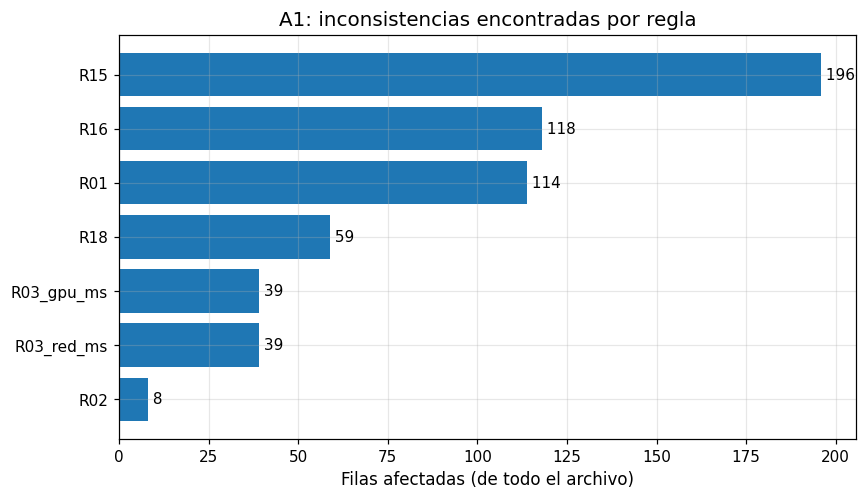

In [ ]:
aud["tratamiento"] = aud.regla.str[:3].map(TRATAMIENTO)       # une cada regla con su tratamiento (R03_x se agrupa como R03)
aud.to_csv("A1_tabla_auditoria.csv", index=False)             # tabla «filas afectadas / criterio / tratamiento» (anexo del informe)
flujo.to_csv("A1_flujo_filas.csv", index=False)               # cuántas filas se pierde en cada paso (bitácora)
df_limpio.to_csv("solicitudes_limpio.csv", index=False)       # archivo limpio que usarán A2 y las demás partes

hall = aud[aud.filas_afectadas > 0].sort_values("filas_afectadas")      # solo reglas con hallazgos, de menor a mayor
fig, ax = plt.subplots(figsize=(8, 0.45 * len(hall) + 1.5))   # alto proporcional al número de barras
ax.barh(hall.regla, hall.filas_afectadas)                     # barras horizontales: una por regla
ax.set_xlabel("Filas afectadas (de todo el archivo)")         # unidades del eje
ax.set_title("A1: inconsistencias encontradas por regla")     # título
for i, v in enumerate(hall.filas_afectadas):                  # escribe el número al final de cada barra
    ax.text(v, i, f" {v}", va="center")
plt.tight_layout()
plt.savefig("fig_A1_defectos.png", dpi=150)                   # guarda la figura para el anexo
plt.show()

In [ ]:
# Resumen en texto para la bitácora
print(f"A1 · archivo {ARCHIVO}: {len(df_raw)} filas, {df_raw.shape[1]} columnas.")
print(f"A1 · filas con al menos un error: {int(hay_error.sum())} ({100 * hay_error.mean():.2f} %).")
print(f"A1 · filas finales tras limpieza: {len(df_limpio)} (perdidas: {len(df_raw) - len(df_limpio)}).")
print(f"A1 · resolución de tiempos = {RESOLUCION_MS} ms | TOL_MS = {TOL_MS} | corrección de unidades en tam_kb = {CORREGIR_TAM}")
print(f"A1 · UMBRAL_REPETICION = {UMBRAL_REPETICION} | FACTOR_REPETICION = {FACTOR_REPETICION} | T_VENTANA = {T_VENTANA}")

A1 · archivo solicitudes.csv: 39489 filas, 10 columnas.
A1 · filas con al menos un error: 451 (1.14 %).
A1 · filas finales tras limpieza: 39129 (perdidas: 360).
A1 · resolución de tiempos = 0.01 ms | TOL_MS = 0.015000000999999999 | corrección de unidades en tam_kb = True
A1 · UMBRAL_REPETICION = 8 | FACTOR_REPETICION = 8 | T_VENTANA = 1200.0


### A2. ¿Un único régimen?
Criterio estadístico cuantitativo, segmentos, sensibilidad al criterio y régimen estable que se usará en adelante.

**Paso 1. ¿Toda la ventana es un único régimen?**

Si la tasa de llegadas fuera constante (Poisson homogéneo), los conteos en bins de 10 s tendrían varianza ≈ media. El índice de dispersión $D=\sum (c_i-\bar c)^2/\bar c$ sigue aprox. una $\chi^2_{k-1}$.

In [ ]:
d_a2 = df_limpio.sort_values("t_llegada_s").reset_index(drop=True)   # orden temporal
conteos = np.histogram(d_a2.t_llegada_s, bins=np.arange(0, T_VENTANA + 10, 10))[0]   # llegadas cada 10 s

D = ((conteos - conteos.mean())**2 / conteos.mean()).sum()     # índice de dispersión
p_disp = stats.chi2.sf(D, len(conteos) - 1)                     # valor p bajo Poisson homogéneo
print(f"D = {D:.1f}, gl = {len(conteos) - 1}, p = {p_disp:.2e}, varianza/media = {conteos.var(ddof=1) / conteos.mean():.1f}")
print("-> NO es un único régimen" if p_disp < alpha else "-> Compatible con un único régimen")

D = 5318.5, gl = 119, p = 0.00e+00, varianza/media = 44.7
-> NO es un único régimen


**Paso 2. ¿Dónde empieza y termina el régimen distinto? (y sensibilidad al criterio)**

Se prueban todos los cortes posibles (inicio, fin) y se elige el que maximiza la verosimilitud de un modelo con tres tramos de tasa constante. Se repite con varios anchos de bin y con otra variable (reintentos) para ver si los cortes cambian.

In [ ]:
def buscar_rafaga(c, ancho):
    """Devuelve (inicio_s, fin_s) del tramo que mejor se separa del resto (máx. verosimilitud Poisson)."""
    def logver(tramo):                                     # log-verosimilitud de un tramo con tasa constante
        s, L = tramo.sum(), len(tramo)
        return s * np.log(s / L) - s if s > 0 else 0
    mejor, corte = -np.inf, None
    for i in range(1, len(c)):                             # todos los pares de cortes i < j
        for j in range(i + 1, len(c)):
            v = logver(c[:i]) + logver(c[i:j]) + logver(c[j:])
            if v > mejor:
                mejor, corte = v, (i * ancho, j * ancho)
    return corte

# Criterio 1: llegadas, con distintos anchos de bin
for ancho in [5, 10, 20, 30, 60]:
    llegadas = np.histogram(d_a2.t_llegada_s, bins=np.arange(0, T_VENTANA + ancho, ancho))[0]
    print(f"Llegadas, bin {ancho:2d} s -> ráfaga en {buscar_rafaga(llegadas, ancho)}")

# Criterio 2: solicitudes que necesitaron reintento (otra variable, misma idea)
reintentos = np.histogram(d_a2.t_llegada_s[d_a2.intentos > 1], bins=np.arange(0, T_VENTANA + 10, 10))[0]
print(f"Reintentos, bin 10 s -> ráfaga en {buscar_rafaga(reintentos, 10)}")

Llegadas, bin  5 s -> ráfaga en (370, 550)
Llegadas, bin 10 s -> ráfaga en (370, 550)
Llegadas, bin 20 s -> ráfaga en (360, 560)
Llegadas, bin 30 s -> ráfaga en (360, 540)
Llegadas, bin 60 s -> ráfaga en (360, 540)
Reintentos, bin 10 s -> ráfaga en (370, 550)


**Paso 3. Régimen estable y verificación**

Se quita la ráfaga. Para unir el tramo anterior y el posterior se comprueba que no difieren (4 pruebas a la vez, por eso se usa Bonferroni: α/4).

In [ ]:
INI, FIN = 370, 550                                            # cortes hallados en el paso 2
en_rafaga = d_a2.t_llegada_s.between(INI, FIN, inclusive="left")
df_estable, df_rafaga = d_a2[~en_rafaga].copy(), d_a2[en_rafaga].copy()   # df_estable se usa en B a F
pre  = df_estable[df_estable.t_llegada_s < INI]
post = df_estable[df_estable.t_llegada_s >= FIN]

# Resumen por tramo
for nombre, d, dur in [("antes", pre, INI), ("ráfaga", df_rafaga, FIN - INI), ("después", post, T_VENTANA - FIN)]:
    print(f"{nombre:8s} tasa = {len(d) / dur:5.2f} sol/s | P(intentos>1) = {(d.intentos > 1).mean():.3f} | "
          f"latencia media = {d.latencia_ms.mean():.1f} ms | éxito = {d.exito.mean():.3f}")

# ¿Antes y después son iguales?
pruebas = {
    "tasa":       stats.binomtest(len(pre), len(df_estable), INI / (T_VENTANA - (FIN - INI))).pvalue,
    "reintentos": stats.chi2_contingency(pd.crosstab(df_estable.t_llegada_s >= FIN, df_estable.intentos > 1))[1],
    "latencia":   stats.ks_2samp(pre.latencia_ms, post.latencia_ms).pvalue,
    "gpu":        stats.ks_2samp(pre.gpu_ms[pre.cache_hit == 0], post.gpu_ms[post.cache_hit == 0]).pvalue,
}
print(f"\nAntes vs después (Bonferroni, α/4 = {alpha / 4:.3f}):")
for nombre, pv in pruebas.items():
    print(f"  {nombre:11s} p = {pv:.3f} -> {'difieren' if pv < alpha / 4 else 'iguales'}")

# ¿El régimen estable es Poisson homogéneo?
c_est = np.concatenate([np.histogram(pre.t_llegada_s, np.arange(0, INI + 1, 10))[0],
                        np.histogram(post.t_llegada_s, np.arange(FIN, T_VENTANA + 1, 10))[0]])
D_est = ((c_est - c_est.mean())**2 / c_est.mean()).sum()
print(f"\nRégimen estable: D = {D_est:.1f}, p = {stats.chi2.sf(D_est, len(c_est) - 1):.3f} | "
      f"{len(df_estable)} solicitudes (ráfaga: {len(df_rafaga)})")

antes    tasa = 27.36 sol/s | P(intentos>1) = 0.210 | latencia media = 53.9 ms | éxito = 0.989
ráfaga   tasa = 60.93 sol/s | P(intentos>1) = 0.419 | latencia media = 83.9 ms | éxito = 0.924
después  tasa = 27.75 sol/s | P(intentos>1) = 0.213 | latencia media = 55.0 ms | éxito = 0.991

Antes vs después (Bonferroni, α/4 = 0.025):
  tasa        p = 0.252 -> iguales
  reintentos  p = 0.639 -> iguales
  latencia    p = 0.087 -> iguales
  gpu         p = 0.084 -> iguales

Régimen estable: D = 92.2, p = 0.723 | 28162 solicitudes (ráfaga: 10967)


**Conclusión A2.** La ventana no es un único régimen: hay una ráfaga en [370, 550) s donde la tasa de llegadas y los reintentos se duplican. Los cortes no dependen del ancho del bin ni de la variable usada. El régimen estable es [0, 370) ∪ [550, 1200) s (`df_estable`), y es el que se usa en las partes B a F.

### A3. Resumen descriptivo
Centro, dispersión, asimetría y curtosis de latencia_ms, gpu_ms, red_ms y tam_kb, por versión y por régimen.

**Figura 1:** evolución temporal del sistema.

**Cómo se resume.** Se usan los datos limpios de A1 con la etiqueta de régimen de A2 (`estable` = [0, 370) ∪ [550, 1200) s, `rafaga` = [370, 550) s).
Para cada variable se reporta, por régimen y por versión (A, B y A+B):
- **centro:** media y mediana
- **dispersión:** desviación estándar e IQR
- **forma:** asimetría y curtosis en exceso (0 = como la normal)

`gpu_ms` se reporta dos veces: con todas las solicitudes y solo con las no cacheadas, porque las cacheadas tienen `gpu_ms = 0` y ese bloque de ceros distorsiona la forma (la variable mixta se estudia en C1).

In [ ]:
# Paso 1. Tabla descriptiva por variable, régimen y versión
d_a2["regimen"] = np.where(d_a2.t_llegada_s.between(INI, FIN, inclusive="left"), "rafaga", "estable")   # etiqueta de A2
d_a2["gpu_sin_cache"] = d_a2.gpu_ms.where(d_a2.cache_hit == 0)   # GPU solo de las solicitudes que usaron GPU

VARIABLES_A3 = ["latencia_ms", "gpu_ms", "gpu_sin_cache", "red_ms", "tam_kb"]


def descriptivos(x):
    """Centro, dispersión, asimetría y curtosis en exceso de una muestra."""
    x = x.dropna()
    return pd.Series({"n": len(x),
                      "media": x.mean(), "mediana": x.median(),                        # centro
                      "desv_est": x.std(), "IQR": x.quantile(.75) - x.quantile(.25),   # dispersión
                      "asimetria": stats.skew(x),                                      # > 0: cola a la derecha
                      "curtosis_exceso": stats.kurtosis(x)})                           # 0: como la normal


con_total = pd.concat([d_a2, d_a2.assign(version="A+B")])       # duplica las filas como "A+B" para tener el total
tabla_a3 = (con_total.melt(id_vars=["regimen", "version"], value_vars=VARIABLES_A3, var_name="variable")
            .groupby(["variable", "regimen", "version"])["value"].apply(descriptivos).unstack()
            .reindex(VARIABLES_A3, level="variable"))            # mismo orden de VARIABLES_A3
tabla_a3["n"] = tabla_a3["n"].astype(int)
tabla_a3.round(4).to_csv("A3_resumen_descriptivo.csv")         # anexo del informe
tabla_a3.round(2)

n   media  mediana  desv_est     IQR  asimetria  curtosis_exceso
variable      regimen version                                                                      
latencia_ms   estable A        14225   55.49    49.78     32.51   43.25       1.54             4.14
                      A+B      28162   54.60    48.80     31.64   42.14       1.55             4.30
                      B        13937   53.69    47.98     30.70   41.11       1.56             4.43
              rafaga  A         5375   85.30    64.81     68.59   90.01       1.34             1.54
                      A+B      10967   83.92    63.85     67.61   88.38       1.39             1.75
                      B         5592   82.58    63.16     66.63   85.74       1.44             1.98
gpu_ms        estable A        14225   26.89    22.46     28.85   41.04       1.62             4.64
                      A+B      28162   26.05    21.40     28.03   39.82       1.61             4.57
                      B        13937   25.20    20.56     27.13   38.72       1.59             4.39
              rafaga  A         5375   26.65    21.82     28.59   41.34       1.56             4.18
                      A+B      10967   25.85    21.11     27.91   39.86       1.57             4.19
                      B         5592   25.08    20.34     27.23   38.52       1.57             4.15
gpu_sin_cache estable A         9469   40.40    33.82     26.55   28.10       1.98             6.84
                      A+B      18704   39.23    32.91     25.80   27.84       1.96             6.70
                      B         9235   38.02    31.75     24.96   27.56       1.93             6.41
              rafaga  A         3558   40.26    33.66     26.20   29.57       1.90             6.18
                      A+B       7237   39.18    32.78     25.67   28.28       1.89             6.11
                      B         3679   38.13    31.87     25.10   27.08       1.86             5.98
red_ms        estable A        14225   25.59    25.57      3.86    5.22      -0.02             0.02
                      A+B      28162   25.60    25.58      3.87    5.24      -0.01            -0.01
                      B        13937   25.61    25.59      3.88    5.26      -0.01            -0.03
              rafaga  A         5375   25.58    25.60      3.87    5.23      -0.01            -0.07
                      A+B      10967   25.59    25.63      3.86    5.23      -0.05             0.03
                      B         5592   25.59    25.65      3.85    5.24      -0.09             0.13
tam_kb        estable A        14225  242.68   205.13    169.69  206.24       1.48             3.58
                      A+B      28162  242.17   204.26    169.54  207.14       1.43             3.15
                      B        13937  241.64   202.82    169.39  207.66       1.38             2.71
              rafaga  A         5375  240.02   201.83    169.46  205.06       1.37             2.54
                      A+B      10967  240.33   202.80    171.59  206.73       1.48             3.53
                      B         5592  240.62   203.46    173.63  207.82       1.58             4.39

**Paso 2. ¿Qué cambia?** Se comparan las medias en dos direcciones: ráfaga frente a estable, y versión B frente a A. También se calcula la espera en cola implícita (L − red − GPU), que explica por qué sube la latencia. Es solo descriptivo: la inferencia con intervalos viene en F3.

In [ ]:
# Paso 2. Cambio relativo de la media (%) y contexto por régimen
m = tabla_a3["media"]                                           # medias de la tabla del paso 1
cambios = pd.DataFrame({
    "ráfaga vs estable (%)": 100 * (m.xs(("rafaga", "A+B"), level=[1, 2]) / m.xs(("estable", "A+B"), level=[1, 2]) - 1),
    "B vs A, estable (%)":   100 * (m.xs(("estable", "B"), level=[1, 2]) / m.xs(("estable", "A"), level=[1, 2]) - 1),
    "B vs A, ráfaga (%)":    100 * (m.xs(("rafaga", "B"), level=[1, 2]) / m.xs(("rafaga", "A"), level=[1, 2]) - 1),
})
print(cambios.round(1).to_string(), "\n")

d_a2["espera_ms"] = (d_a2.latencia_ms - d_a2.red_ms - d_a2.gpu_ms).clip(lower=0)   # L = red + espera + GPU
duracion = {"estable": T_VENTANA - (FIN - INI), "rafaga": FIN - INI}               # segundos de cada régimen
contexto = d_a2.groupby("regimen").agg(n=("t_llegada_s", "size"),
                                       espera_media_ms=("espera_ms", "mean"),
                                       tasa_cache=("cache_hit", "mean"),
                                       P_L_mayor_tau=("latencia_ms", lambda s: (s > tau).mean()),
                                       P_intentos_mayor_1=("intentos", lambda s: (s > 1).mean()))
contexto.insert(1, "llegadas_por_s", contexto.n / pd.Series(duracion))
print(f"Contexto por régimen (tau = {tau} ms):")
print(contexto.round(4).to_string())

               ráfaga vs estable (%)  B vs A, estable (%)  B vs A, ráfaga (%)
variable                                                                     
latencia_ms                     53.7                 -3.2                -3.2
gpu_ms                          -0.8                 -6.3                -5.9
gpu_sin_cache                   -0.1                 -5.9                -5.3
red_ms                          -0.1                  0.1                 0.1
tam_kb                          -0.8                 -0.4                 0.3 

Contexto por régimen (tau = 210 ms):
             n  llegadas_por_s  espera_media_ms  tasa_cache  P_L_mayor_tau  P_intentos_mayor_1
regimen                                                                                       
estable  28162         27.6098           2.9444      0.3358         0.0018              0.2120
rafaga   10967         60.9278          32.4791      0.3401         0.0663              0.4188


### Figura 1. Evolución temporal del sistema
Cuatro paneles con el mismo eje de tiempo (bins de 10 s) y la ráfaga sombreada: carga (llegadas), latencia por versión frente a τ, reintentos y tiempo de GPU. Así se ve qué cambia con el régimen y qué no.

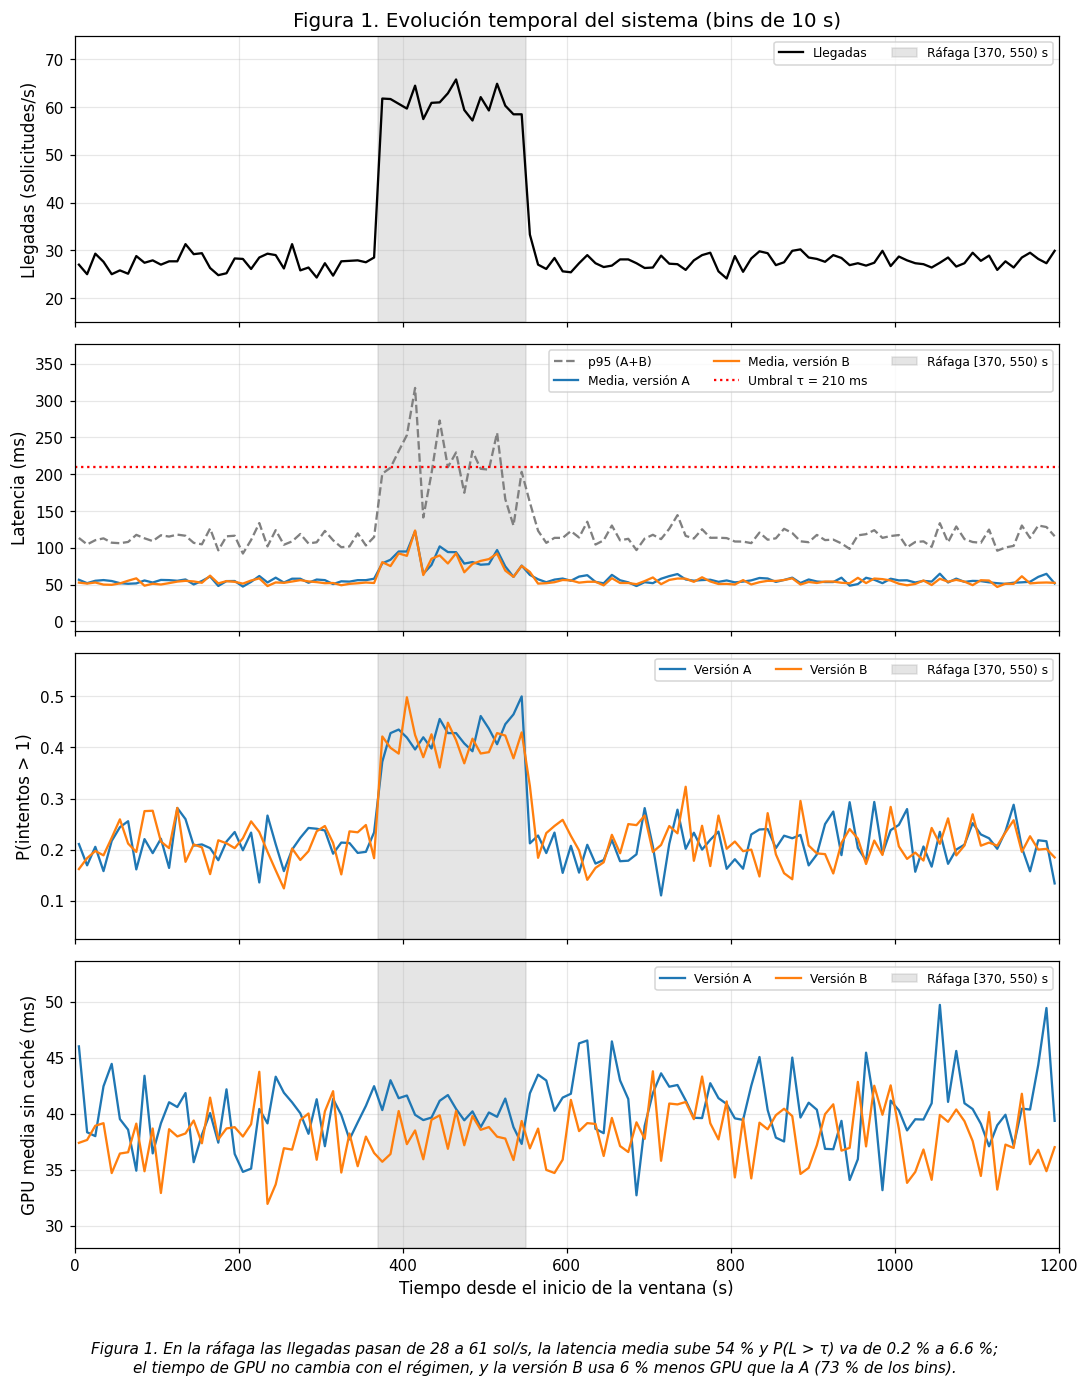

In [ ]:
# Paso 3. Figura 1
ANCHO = 10                                                      # segundos por bin
bin_s = (d_a2.t_llegada_s // ANCHO) * ANCHO + ANCHO / 2        # centro del bin de cada solicitud
por_bin = d_a2.groupby(bin_s)
por_bin_ver = d_a2.groupby([bin_s, "version"])
COLOR = {"A": "tab:blue", "B": "tab:orange"}

fig, ax = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

ax[0].plot(por_bin.size() / ANCHO, color="black", label="Llegadas")
ax[0].set_ylabel("Llegadas (solicitudes/s)")
ax[0].set_title("Figura 1. Evolución temporal del sistema (bins de 10 s)")

ax[1].plot(por_bin.latencia_ms.quantile(0.95), color="grey", linestyle="--", label="p95 (A+B)")
lat = por_bin_ver.latencia_ms.mean().unstack()
rein = por_bin_ver.intentos.apply(lambda s: (s > 1).mean()).unstack()
gpu = por_bin_ver.gpu_sin_cache.mean().unstack()
for v in ["A", "B"]:
    ax[1].plot(lat[v], color=COLOR[v], label=f"Media, versión {v}")
    ax[2].plot(rein[v], color=COLOR[v], label=f"Versión {v}")
    ax[3].plot(gpu[v], color=COLOR[v], label=f"Versión {v}")
ax[1].axhline(tau, color="red", linestyle=":", label=f"Umbral τ = {tau} ms")
ax[1].set_ylabel("Latencia (ms)")
ax[2].set_ylabel("P(intentos > 1)")
ax[3].set_ylabel("GPU media sin caché (ms)")
ax[3].set_xlabel("Tiempo desde el inicio de la ventana (s)")

for a_ in ax:                                                   # ráfaga sombreada y leyenda en cada panel
    a_.axvspan(INI, FIN, color="grey", alpha=0.2, label=f"Ráfaga [{INI}, {FIN}) s")
    a_.margins(y=0.22)
    a_.legend(loc="upper right", fontsize=8, ncol=3)
    a_.set_xlim(0, T_VENTANA)

frac_B_menor = (gpu["B"] < gpu["A"]).mean()                    # bins donde B tiene menos GPU que A
est, raf = contexto.loc["estable"], contexto.loc["rafaga"]
pie_de_figura(fig, 1,
              f"En la ráfaga las llegadas pasan de {est.llegadas_por_s:.0f} a {raf.llegadas_por_s:.0f} sol/s, la latencia media "
              f"sube {cambios.loc['latencia_ms', 'ráfaga vs estable (%)']:.0f} % y P(L > τ) va de {100 * est.P_L_mayor_tau:.1f} % "
              f"a {100 * raf.P_L_mayor_tau:.1f} %;\nel tiempo de GPU no cambia con el régimen, y la versión B usa "
              f"{abs(cambios.loc['gpu_sin_cache', 'B vs A, estable (%)']):.0f} % menos GPU que la A ({100 * frac_B_menor:.0f} % de los bins).")
plt.tight_layout()
guardar_figura(fig, 1)                                          # figuras/figura_1.png
plt.show()

**Conclusión A3.**
- **La ráfaga solo afecta la latencia:** la media sube ≈ 54 % y la espera en cola pasa de ≈ 3 a ≈ 32 ms, mientras GPU, red y tamaño no cambian. El deterioro es por carga, no por el modelo.
- **La versión B usa ≈ 6 % menos GPU que la A** en ambos regímenes. Es una pista descriptiva; la prueba formal es F3.
- **Forma:** latencia, GPU y tamaño son asimétricas a la derecha (media > mediana, asimetría > 0) y con colas pesadas; `red_ms` tiene asimetría y curtosis ≈ 0, compatible con una normal (se prueba en C3).

# Parte B - Llegadas, fallos y reintentos (14 pts)

### B1. Modelo del proceso de llegadas

**Modelo propuesto.** Si las solicitudes llegan de forma independiente y con tasa constante λ (régimen estable), las llegadas forman un **proceso de Poisson homogéneo**. Eso implica dos cosas que se pueden contrastar con los datos:
- los **tiempos entre llegadas** son independientes y siguen una **Exponencial(λ)**, con media 1/λ;
- el **número de llegadas** en un intervalo de Δ segundos sigue una **Poisson(λΔ)**, con media = varianza = λΔ.

El régimen estable son dos tramos separados ([0, 370) y [550, 1200) s), así que los tiempos entre llegadas se calculan **dentro de cada tramo**, para no contar el hueco de la ráfaga como un tiempo entre llegadas.

In [ ]:
# Paso 1. Datos del régimen estable: tiempos entre llegadas y conteos por segundo
DELTA = 1.0                                                     # ancho (s) de los intervalos para contar llegadas
tramos = [(0, INI), (FIN, T_VENTANA)]                           # los dos tramos del régimen estable
T_EST = sum(b - a for a, b in tramos)                           # tiempo total observado: 1020 s

entre_llegadas, conteos_b1 = [], []
for a, b in tramos:
    t = np.sort(df_estable.t_llegada_s[(df_estable.t_llegada_s >= a) & (df_estable.t_llegada_s < b)].to_numpy())
    entre_llegadas.append(np.diff(t))                           # tiempos entre llegadas consecutivas DEL MISMO tramo
    conteos_b1.append(np.histogram(t, bins=np.arange(a, b + DELTA, DELTA))[0])   # llegadas en cada segundo
X = np.concatenate(entre_llegadas)                              # tiempos entre llegadas (s)
C = np.concatenate(conteos_b1)                                  # conteos por intervalo de 1 s
n_lleg = len(df_estable)

print(f"Llegadas: {n_lleg} en {T_EST:.0f} s | tiempos entre llegadas: {len(X)} | intervalos de {DELTA:.0f} s: {len(C)}")
print(f"Tiempo entre llegadas: media = {1000 * X.mean():.2f} ms, desv. est. = {1000 * X.std(ddof=1):.2f} ms, "
      f"CV = {X.std(ddof=1) / X.mean():.3f}  (Exponencial: CV = 1)")
print(f"Conteos por segundo: media = {C.mean():.2f}, varianza = {C.var(ddof=1):.2f}, "
      f"varianza/media = {C.var(ddof=1) / C.mean():.3f}  (Poisson: = 1)")

Llegadas: 28162 en 1020 s | tiempos entre llegadas: 28160 | intervalos de 1 s: 1020
Tiempo entre llegadas: media = 36.22 ms, desv. est. = 36.39 ms, CV = 1.005  (Exponencial: CV = 1)
Conteos por segundo: media = 27.61, varianza = 29.19, varianza/media = 1.057  (Poisson: = 1)


**Paso 2. Estimación de λ.** El estimador de máxima verosimilitud de la tasa es $\hat\lambda = N/T$ (llegadas entre tiempo observado), equivalente a $1/\bar X$ con los tiempos entre llegadas. Se reportan dos intervalos exactos al nivel 1 − α del grupo:
- **por conteos:** N ~ Poisson(λT), intervalo de Garwood con cuantiles χ²;
- **por tiempos entre llegadas:** si $X_i$ ~ Exp(λ), entonces $2\lambda\sum X_i \sim \chi^2_{2n}$.

También se da el intervalo para la media entre llegadas, 1/λ.

In [ ]:
# Paso 2. Estimación puntual e intervalos de confianza de lambda
lam_hat = n_lleg / T_EST                                        # MLE con conteos: N / T
lam_hat_x = 1 / X.mean()                                        # MLE con tiempos entre llegadas: 1 / media

# IC exacto por conteos (Garwood): N ~ Poisson(lambda * T)
lam_li = stats.chi2.ppf(alpha / 2, 2 * n_lleg) / (2 * T_EST)
lam_ls = stats.chi2.ppf(1 - alpha / 2, 2 * n_lleg + 2) / (2 * T_EST)

# IC exacto por tiempos entre llegadas: 2 * lambda * sum(X) ~ chi2 con 2n grados de libertad
n_x, suma_x = len(X), X.sum()
lamx_li = stats.chi2.ppf(alpha / 2, 2 * n_x) / (2 * suma_x)
lamx_ls = stats.chi2.ppf(1 - alpha / 2, 2 * n_x) / (2 * suma_x)

print("lambda (solicitudes/s), por conteos:          ", formatear_intervalo(lam_hat, lam_li, lam_ls, "Poisson exacto (Garwood)"))
print("lambda (solicitudes/s), por entre llegadas:   ", formatear_intervalo(lam_hat_x, lamx_li, lamx_ls, "chi2 exacto, Exponencial"))
print("media entre llegadas 1/lambda (ms):           ", formatear_intervalo(1000 / lam_hat_x, 1000 / lamx_ls, 1000 / lamx_li, "chi2 exacto, Exponencial", 2))

lambda (solicitudes/s), por conteos:           27.610  [27.340, 27.882]  (IC 90%, método: Poisson exacto (Garwood))
lambda (solicitudes/s), por entre llegadas:    27.609  [27.339, 27.880]  (IC 90%, método: chi2 exacto, Exponencial)
media entre llegadas 1/lambda (ms):            36.22  [35.87, 36.58]  (IC 90%, método: chi2 exacto, Exponencial)


**Paso 3. Validación (dos vías cuantitativas, una por cada parte del modelo).**
1. **Tiempos entre llegadas vs. Exponencial(λ̂):** prueba de Kolmogórov-Smirnov. Como λ se estimó con los mismos datos, el valor p de la KS clásica sería demasiado optimista; por eso se calcula por **bootstrap paramétrico** (se simulan muestras Exponenciales con λ̂, se re-estima λ en cada una y se recalcula el estadístico). Además se revisa la **independencia** con la autocorrelación de orden 1.
2. **Conteos por segundo vs. Poisson(λ̂):** prueba **χ² de bondad de ajuste**, agrupando las colas para que cada clase tenga frecuencia esperada ≥ 5, y el **índice de dispersión** (varianza/media = 1).

In [ ]:
# Paso 3a. Tiempos entre llegadas: KS contra Exponencial(lambda estimada), valor p por bootstrap paramétrico
B_BOOT = 1000                                                   # réplicas del bootstrap
ks_obs = stats.kstest(X, "expon", args=(0, 1 / lam_hat_x)).statistic
ks_boot = np.empty(B_BOOT)
for b in range(B_BOOT):
    xb = rng.exponential(1 / lam_hat_x, size=n_x)               # muestra simulada bajo H0
    ks_boot[b] = stats.kstest(xb, "expon", args=(0, xb.mean())).statistic   # se re-estima lambda en cada réplica
p_ks = (1 + (ks_boot >= ks_obs).sum()) / (B_BOOT + 1)
print(f"KS tiempos entre llegadas: D = {ks_obs:.4f}, p (bootstrap paramétrico) = {p_ks:.3f} "
      f"-> {'se rechaza' if p_ks < alpha else 'no se rechaza'} la Exponencial")

# Independencia: autocorrelación de orden 1 de los tiempos entre llegadas (bajo independencia ~ N(0, 1/n))
rho1 = np.corrcoef(X[:-1], X[1:])[0, 1]
z_rho = rho1 * np.sqrt(n_x)
print(f"Autocorrelación de orden 1: {rho1:.4f}, z = {z_rho:.2f}, p = {2 * stats.norm.sf(abs(z_rho)):.3f}")

KS tiempos entre llegadas: D = 0.0055, p (bootstrap paramétrico) = 0.154 -> no se rechaza la Exponencial
Autocorrelación de orden 1: -0.0028, z = -0.47, p = 0.641


In [ ]:
# Paso 3b. Conteos por segundo: chi^2 de bondad de ajuste contra Poisson(lambda * DELTA)
mu = lam_hat * DELTA                                            # media esperada por intervalo
k_lo, k_hi = int(stats.poisson.ppf(0.005, mu)), int(stats.poisson.ppf(0.995, mu))
clases = np.arange(k_lo, k_hi + 1)                              # clases centrales; las colas se agrupan en los extremos
obs = np.array([(C <= k_lo).sum()] + [(C == k).sum() for k in clases[1:-1]] + [(C >= k_hi).sum()])
p_cl = np.concatenate([[stats.poisson.cdf(k_lo, mu)], stats.poisson.pmf(clases[1:-1], mu), [stats.poisson.sf(k_hi - 1, mu)]])
esp = len(C) * p_cl

# Agrupa clases vecinas hasta que todas tengan frecuencia esperada >= 5
while esp.min() < 5:
    i = int(np.argmin(esp)); j = i + 1 if i < len(esp) - 1 else i - 1
    obs[j] += obs[i]; esp[j] += esp[i]
    obs, esp = np.delete(obs, i), np.delete(esp, i)

chi2_obs = ((obs - esp) ** 2 / esp).sum()
gl_chi2 = len(obs) - 1 - 1                                      # -1 por la suma fija y -1 por estimar lambda
p_chi2 = stats.chi2.sf(chi2_obs, gl_chi2)
print(f"Chi^2 conteos por segundo: X2 = {chi2_obs:.2f}, gl = {gl_chi2}, p = {p_chi2:.3f} "
      f"-> {'se rechaza' if p_chi2 < alpha else 'no se rechaza'} la Poisson")

D_b1 = ((C - C.mean()) ** 2 / C.mean()).sum()                   # índice de dispersión (como en A2, ahora con bins de 1 s)
p_disp_b1 = 2 * min(stats.chi2.sf(D_b1, len(C) - 1), stats.chi2.cdf(D_b1, len(C) - 1))   # bilateral: sobre o subdispersión
print(f"Índice de dispersión: D = {D_b1:.1f}, gl = {len(C) - 1}, varianza/media = {C.var(ddof=1) / C.mean():.3f}, p = {p_disp_b1:.3f}")

Chi^2 conteos por segundo: X2 = 33.61, gl = 25, p = 0.117 -> no se rechaza la Poisson
Índice de dispersión: D = 1077.3, gl = 1019, varianza/media = 1.057, p = 0.200


**Gráfica de apoyo.** A la izquierda, el QQ-plot de los tiempos entre llegadas contra la Exponencial(λ̂): si el modelo es bueno, los puntos caen sobre la diagonal. A la derecha, la frecuencia observada de los conteos por segundo frente a la Poisson(λ̂).

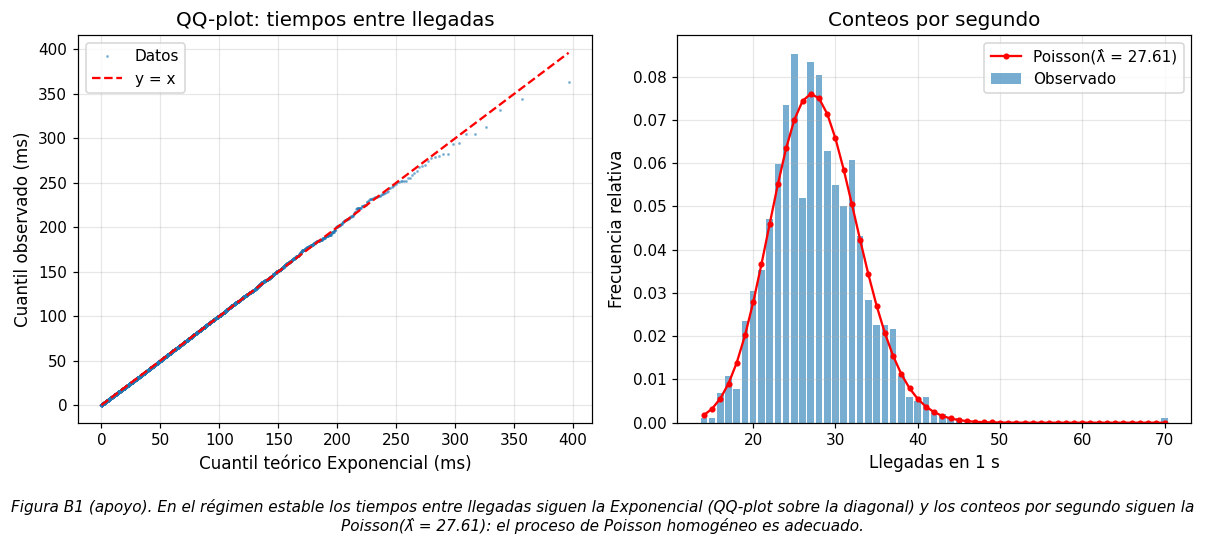

In [ ]:
# Paso 4. Gráfica de apoyo (no es una figura numerada del enunciado)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

prob = (np.arange(1, n_x + 1) - 0.5) / n_x                      # probabilidades de los cuantiles
teo = stats.expon.ppf(prob, scale=1 / lam_hat_x) * 1000         # cuantiles teóricos (ms)
ax[0].plot(teo, np.sort(X) * 1000, ".", ms=2, alpha=0.4, label="Datos")
ax[0].plot([0, teo.max()], [0, teo.max()], "r--", label="y = x")
ax[0].set_xlabel("Cuantil teórico Exponencial (ms)")
ax[0].set_ylabel("Cuantil observado (ms)")
ax[0].set_title("QQ-plot: tiempos entre llegadas")
ax[0].legend()

k = np.arange(C.min(), C.max() + 1)
ax[1].bar(k, [(C == v).mean() for v in k], color="tab:blue", alpha=0.6, label="Observado")
ax[1].plot(k, stats.poisson.pmf(k, mu), "ro-", ms=3, label=f"Poisson(λ̂ = {mu:.2f})")
ax[1].set_xlabel("Llegadas en 1 s")
ax[1].set_ylabel("Frecuencia relativa")
ax[1].set_title("Conteos por segundo")
ax[1].legend()

plt.tight_layout()
pie_de_figura(fig, "B1 (apoyo)",
              f"En el régimen estable los tiempos entre llegadas siguen la Exponencial (QQ-plot sobre la diagonal) "
              f"y los conteos por segundo siguen la Poisson(λ̂ = {mu:.2f}): el proceso de Poisson homogéneo es adecuado.")
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_B1.png"), bbox_inches="tight")
plt.show()

**Conclusión B1.** En el régimen estable las llegadas son compatibles con un proceso de Poisson homogéneo: los tiempos entre llegadas se ajustan a una Exponencial y no están correlacionados, y los conteos por segundo se ajustan a una Poisson con varianza ≈ media. La tasa estimada es λ̂ ≈ 27,6 solicitudes/s (ver intervalos arriba); este λ̂ es el que se usa en B4 y en la simulación de la Parte G.

### B2. Bloques de 100 solicitudes

**Modelo propuesto.** Sea $Y_j$ el número de solicitudes del bloque $j$ (100 solicitudes consecutivas) que necesitaron más de un intento. Si dentro de un régimen
cada solicitud necesita reintento de forma **independiente** y con la **misma probabilidad** $p$, entonces
$$Y_j \sim \text{Binomial}(100,\,p), \qquad E[Y_j] = 100p, \qquad \text{Var}(Y_j) = 100p(1-p).$$
Se ajusta una Binomial **por régimen**, porque A2 mostró que los reintentos se duplican en la ráfaga. Los bloques se arman **dentro de cada tramo** (igual que en B1,
para no mezclar solicitudes separadas por el hueco de la ráfaga) y se descartan las solicitudes sobrantes al final de cada tramo, que no completan un bloque.

Dos cosas pueden fallar y se contrastan con los datos: que $p$ no sea constante dentro del régimen, o que haya dependencia entre solicitudes (ráfagas de fallos).
Cualquiera de las dos haría la varianza de $Y_j$ **mayor** que $100p(1-p)$ (sobredispersión).

In [ ]:
# Paso 1. Bloques consecutivos de 100 solicitudes y número de solicitudes con más de un intento en cada bloque
TAM_BLOQUE = 100                                                # solicitudes por bloque (enunciado)


def contar_por_bloque(d, tramos_):
    """Y_j = solicitudes con intentos > 1 en cada bloque de 100 consecutivas; los bloques se arman dentro de cada tramo.
    Devuelve (Y, instantes inicial y final de cada bloque, solicitudes descartadas)."""
    ys, lim, descartadas = [], [], 0
    for a, b in tramos_:
        t = d[(d.t_llegada_s >= a) & (d.t_llegada_s < b)].sort_values("t_llegada_s")   # solicitudes del tramo, en orden de llegada
        reint = (t.intentos.to_numpy() > 1).astype(int)         # 1 si la solicitud necesitó más de un intento
        k = len(reint) // TAM_BLOQUE                            # bloques completos que caben en el tramo
        ys.append(reint[:k * TAM_BLOQUE].reshape(k, TAM_BLOQUE).sum(axis=1))   # reintentos por bloque
        ti = t.t_llegada_s.to_numpy()[:k * TAM_BLOQUE].reshape(k, TAM_BLOQUE)  # instantes de llegada de cada bloque
        lim.append(np.column_stack([ti[:, 0], ti[:, -1]]))      # (primera, última) llegada de cada bloque
        descartadas += len(reint) - k * TAM_BLOQUE              # solicitudes que no completan un bloque
    return np.concatenate(ys), np.vstack(lim), descartadas


Y, LIM = {}, {}                                                 # Y[reg]: reintentos por bloque; LIM[reg]: (inicio, fin) en s de cada bloque
Y["estable"], LIM["estable"], desc_e = contar_por_bloque(df_estable, tramos)    # `tramos` = los dos tramos del régimen estable (B1)
Y["rafaga"], LIM["rafaga"], desc_r = contar_por_bloque(df_rafaga, [(INI, FIN)])

for reg, descartadas in [("estable", desc_e), ("rafaga", desc_r)]:
    y = Y[reg]
    print(f"{reg:8s} bloques = {len(y):3d} (solicitudes descartadas: {descartadas}) | "
          f"media de Y = {y.mean():5.2f} | varianza de Y = {y.var(ddof=1):5.2f} | mín = {y.min()}, máx = {y.max()}")

estable  bloques = 281 (solicitudes descartadas: 62) | media de Y = 21.21 | varianza de Y = 18.72 | mín = 10, máx = 44
rafaga   bloques = 109 (solicitudes descartadas: 67) | media de Y = 41.83 | varianza de Y = 25.46 | mín = 29, máx = 53


**Paso 2. Estimación de $p$.** El estimador de máxima verosimilitud es la proporción global de solicitudes con reintento, $\hat p = \sum_j Y_j / (100K)$, con $K$ bloques.
Si las solicitudes son independientes, $\sum_j Y_j \sim \text{Binomial}(100K, p)$ y se obtiene un intervalo **exacto de Clopper-Pearson** al nivel 1 − α del grupo.

In [ ]:
# Paso 2. Estimación puntual e intervalo de confianza de p, por régimen
def estimar_p(y):
    """MLE de p y su intervalo exacto de Clopper-Pearson al nivel 1 - alpha."""
    n = TAM_BLOQUE * len(y)                                     # solicitudes totales usadas
    x = int(y.sum())                                            # solicitudes con reintento
    li = stats.beta.ppf(alpha / 2, x, n - x + 1) if x > 0 else 0.0
    ls = stats.beta.ppf(1 - alpha / 2, x + 1, n - x) if x < n else 1.0
    return x / n, li, ls, x, n


EST = {reg: estimar_p(Y[reg]) for reg in Y}                     # reg -> (p_hat, inferior, superior, x, n)
for reg, (p_hat, li, ls, x, n) in EST.items():
    print(f"p ({reg:8s}): ", formatear_intervalo(p_hat, li, ls, "Clopper-Pearson"), f"| {x} de {n} solicitudes")

p (estable ):  0.212  [0.208, 0.216]  (IC 90%, método: Clopper-Pearson) | 5959 de 28100 solicitudes
p (rafaga  ):  0.418  [0.410, 0.426]  (IC 90%, método: Clopper-Pearson) | 4559 de 10900 solicitudes


**Paso 3. Validación (dos vías cuantitativas, más la independencia entre bloques).**
1. **χ² de bondad de ajuste** de la distribución de $Y_j$ contra Binomial(100, $\hat p$), agrupando clases hasta que cada una tenga frecuencia esperada ≥ 5
   (grados de libertad: clases − 1 − 1, por haber estimado $p$).
2. **Índice de dispersión** $D=\sum_j (Y_j-\bar Y)^2 / (100\hat p(1-\hat p))$, que bajo el modelo sigue aprox. $\chi^2_{K-1}$ (varianza/varianza binomial = 1). El valor p es bilateral:
   un valor grande indicaría sobredispersión y uno pequeño subdispersión.
3. **Independencia entre bloques:** autocorrelación de orden 1 de $Y_j$ (bajo independencia es aprox. $N(0, 1/K)$).

In [ ]:
# Paso 3. Validación del modelo Binomial(100, p) en cada régimen
def chi2_binomial(y, n, p):
    """Chi^2 de bondad de ajuste de los conteos y contra Binomial(n, p); clases agrupadas hasta tener esperada >= 5."""
    K = len(y)
    obs_k = np.bincount(y, minlength=n + 1)                     # frecuencia observada de cada valor 0..n
    esp_k = K * stats.binom.pmf(np.arange(n + 1), n, p)         # frecuencia esperada bajo el modelo
    obs, esp, o_acc, e_acc = [], [], 0, 0.0
    for o, e in zip(obs_k, esp_k):                              # recorre las clases de izquierda a derecha
        o_acc, e_acc = o_acc + o, e_acc + e                     # acumula hasta que la esperada llegue a 5
        if e_acc >= 5:
            obs.append(o_acc); esp.append(e_acc); o_acc, e_acc = 0, 0.0
    if e_acc > 0:                                               # el resto de la cola derecha se pega a la última clase
        obs[-1] += o_acc; esp[-1] += e_acc
    obs, esp = np.array(obs), np.array(esp)
    X2 = ((obs - esp) ** 2 / esp).sum()
    gl = len(obs) - 1 - 1                                       # -1 por la suma fija y -1 por estimar p
    return X2, gl, stats.chi2.sf(X2, gl)


filas_val = []
for reg, y in Y.items():
    K, p_hat = len(y), EST[reg][0]
    X2, gl, p_chi2 = chi2_binomial(y, TAM_BLOQUE, p_hat)        # vía 1: bondad de ajuste
    var_bin = TAM_BLOQUE * p_hat * (1 - p_hat)                  # varianza que predice el modelo
    D_b2 = ((y - y.mean()) ** 2).sum() / var_bin                # vía 2: índice de dispersión
    p_disp = 2 * min(stats.chi2.sf(D_b2, K - 1), stats.chi2.cdf(D_b2, K - 1))
    rho1 = np.corrcoef(y[:-1], y[1:])[0, 1]                     # independencia entre bloques consecutivos
    z_rho = rho1 * np.sqrt(K)
    filas_val.append({"régimen": reg, "K": K, "media Y": y.mean(), "100·p̂": TAM_BLOQUE * p_hat,
                      "var Y": y.var(ddof=1), "var Binomial": var_bin, "var/var Bin": y.var(ddof=1) / var_bin,
                      "χ² (gl)": f"{X2:.1f} ({gl})", "p χ²": p_chi2, "p dispersión": p_disp,
                      "autocorr. lag 1": rho1, "p autocorr.": 2 * stats.norm.sf(abs(z_rho))})
validacion = pd.DataFrame(filas_val).set_index("régimen")
print(validacion.round(3).T.to_string())
print(f"\nNivel de decisión α = {alpha}: un valor p < α rechaza el modelo.")

régimen            estable    rafaga
K                      281       109
media Y             21.206    41.826
100·p̂              21.206    41.826
var Y               18.722     25.46
var Binomial        16.709    24.332
var/var Bin           1.12     1.046
χ² (gl)          13.8 (15)  8.8 (13)
p χ²                 0.544     0.787
p dispersión         0.162     0.703
autocorr. lag 1      0.061    -0.108
p autocorr.           0.31     0.261

Nivel de decisión α = 0.1: un valor p < α rechaza el modelo.


**Paso 4. Contraste entre regímenes y explicación de la discrepancia.** Se comprueba (i) que $p$ es constante **dentro** de cada régimen (si no, el modelo Binomial tendría sobredispersión),
(ii) qué pasa si se usa el modelo del régimen estable para describir la ráfaga, y (iii) cuánto cambia $p$ entre regímenes, con su intervalo.

In [ ]:
# Paso 4a. ¿p es constante dentro de cada régimen? Se parten los bloques en tres grupos consecutivos y se compara la proporción (chi^2 de homogeneidad)
for reg, y in Y.items():
    grupos = np.array_split(y, 3)                               # tres tramos consecutivos de bloques
    tabla = np.array([[g.sum(), TAM_BLOQUE * len(g) - g.sum()] for g in grupos])   # [con reintento, sin reintento] por grupo
    chi2_h, p_h, _, _ = stats.chi2_contingency(tabla)
    props = ", ".join(f"{g.sum() / (TAM_BLOQUE * len(g)):.3f}" for g in grupos)
    print(f"{reg:8s} proporción por tercios: {props} | chi2 de homogeneidad p = {p_h:.3f} "
          f"-> {'p cambia' if p_h < alpha else 'p constante'}")

# Paso 4b. Usar el modelo del régimen estable (p estable) para describir la ráfaga
p_e, p_r = EST["estable"][0], EST["rafaga"][0]
y_r = Y["rafaga"]
z_med = (y_r.mean() - TAM_BLOQUE * p_e) / np.sqrt(TAM_BLOQUE * p_e * (1 - p_e) / len(y_r))   # media observada frente a la que predice p_e
q999 = stats.binom.ppf(0.999, TAM_BLOQUE, p_e)                  # cuantil 99,9 % de la Binomial(100, p estable)
frac_sobre = (y_r > q999).mean()                                # bloques de la ráfaga por encima de ese cuantil
print(f"\nModelo del régimen estable aplicado a la ráfaga: se esperaría E[Y] = {TAM_BLOQUE * p_e:.1f} y se observa {y_r.mean():.1f} "
      f"(z = {z_med:.1f}); {100 * frac_sobre:.0f} % de los bloques de la ráfaga superan el cuantil 99,9 % ({q999:.0f}).")

# Paso 4c. Diferencia y cociente de proporciones entre regímenes
(pe_hat, _, _, xe, ne), (pr_hat, _, _, xr, nr) = EST["estable"], EST["rafaga"]
dif = pr_hat - pe_hat
ee = np.sqrt(pe_hat * (1 - pe_hat) / ne + pr_hat * (1 - pr_hat) / nr)      # error estándar de la diferencia
zc = stats.norm.ppf(1 - alpha / 2)
p_dif = stats.chi2_contingency([[xe, ne - xe], [xr, nr - xr]], correction=False)[1]
print(formatear_intervalo(dif, dif - zc * ee, dif + zc * ee, "Wald para diferencia de proporciones"), f"| p (chi2) = {p_dif:.1e}")
print(f"Cociente p(ráfaga)/p(estable) = {pr_hat / pe_hat:.2f}")

estable  proporción por tercios: 0.210, 0.211, 0.215 | chi2 de homogeneidad p = 0.681 -> p constante
rafaga   proporción por tercios: 0.415, 0.411, 0.428 | chi2 de homogeneidad p = 0.326 -> p constante

Modelo del régimen estable aplicado a la ráfaga: se esperaría E[Y] = 21.2 y se observa 41.8 (z = 52.7); 90 % de los bloques de la ráfaga superan el cuantil 99,9 % (35).
0.206  [0.197, 0.215]  (IC 90%, método: Wald para diferencia de proporciones) | p (chi2) = 0.0e+00
Cociente p(ráfaga)/p(estable) = 1.97


**Paso 4d. Bloques atípicos.** El índice de dispersión del régimen estable queda algo por encima de 1. Para ver si es un problema general del modelo o lo causan pocos bloques,
se busca cada bloque cuyo conteo es demasiado extremo para su Binomial (valor p bilateral < α/K, con la corrección de Bonferroni porque se prueban K bloques a la vez).
Para cada bloque marcado se revisa **qué pasó en su ventana de tiempo**: cuántas llegadas hubo frente a lo esperado y qué proporción de reintentos tuvo.
Finalmente se repite la validación sin esos bloques, para medir cuánto dependen las conclusiones de ellos.

In [ ]:
# Paso 4d. Bloques atípicos y sensibilidad
LAM = {"estable": lam_hat, "rafaga": len(df_rafaga) / (FIN - INI)}      # tasa de llegadas de cada régimen (sol/s); lam_hat viene de B1
marcados = {}                                                   # reg -> índices de bloques marcados
for reg, y in Y.items():
    K, p_hat = len(y), EST[reg][0]
    p_blq = 2 * np.minimum(stats.binom.sf(y - 1, TAM_BLOQUE, p_hat), stats.binom.cdf(y, TAM_BLOQUE, p_hat))   # p bilateral de cada bloque
    marcados[reg] = np.flatnonzero(p_blq < alpha / K)           # Bonferroni
    print(f"{reg:8s} bloques marcados (p < alpha/K = {alpha / K:.1e}): {len(marcados[reg])}")
    for j in marcados[reg]:
        a, b = LIM[reg][j]                                      # ventana de tiempo del bloque
        sub = d_a2[(d_a2.t_llegada_s >= a) & (d_a2.t_llegada_s <= b)]
        esperadas = LAM[reg] * (b - a)                          # llegadas que predice la tasa del régimen en esa ventana
        x_w, n_w = int((sub.intentos > 1).sum()), len(sub)
        print(f"  bloque {j}: [{a:.2f}, {b:.2f}] s, Y = {y[j]}, p del bloque = {p_blq[j]:.1e} | llegadas: {n_w} (esperadas {esperadas:.0f}, "
              f"P(N >= {n_w}) = {stats.poisson.sf(n_w - 1, esperadas):.1e}) | reintentos: {x_w / n_w:.2f}")
        for otro in ["estable", "rafaga"]:                      # ¿con qué régimen es compatible la proporción de reintentos de la ventana?
            po = EST[otro][0]
            pv = 2 * min(stats.binom.sf(x_w - 1, n_w, po), stats.binom.cdf(x_w, n_w, po))
            print(f"           ¿compatible con la proporción del régimen {otro} (p = {po:.3f})? p = {pv:.1e}")

print("\nValidación SIN los bloques marcados (sensibilidad):")
for reg, y in Y.items():
    y2 = np.delete(y, marcados[reg]); K2 = len(y2)
    p2 = y2.sum() / (TAM_BLOQUE * K2)
    v2 = TAM_BLOQUE * p2 * (1 - p2)
    D2 = ((y2 - y2.mean()) ** 2).sum() / v2
    pd2 = 2 * min(stats.chi2.sf(D2, K2 - 1), stats.chi2.cdf(D2, K2 - 1))
    print(f"  {reg:8s} K = {K2}, p̂ = {p2:.4f} (antes {EST[reg][0]:.4f}), var/var Bin = {y2.var(ddof=1) / v2:.3f} "
          f"(antes {validacion.loc[reg, 'var/var Bin']:.3f}), p(dispersión) = {pd2:.3f} (antes {validacion.loc[reg, 'p dispersión']:.3f})")

estable  bloques marcados (p < alpha/K = 3.6e-04): 1
  bloque 101: [550.00, 551.97] s, Y = 44, p del bloque = 5.4e-07 | llegadas: 100 (esperadas 54, P(N >= 100) = 2.0e-08) | reintentos: 0.44
           ¿compatible con la proporción del régimen estable (p = 0.212)? p = 5.4e-07
           ¿compatible con la proporción del régimen rafaga (p = 0.418)? p = 7.3e-01
rafaga   bloques marcados (p < alpha/K = 9.2e-04): 0

Validación SIN los bloques marcados (sensibilidad):
  estable  K = 280, p̂ = 0.2112 (antes 0.2121), var/var Bin = 1.015 (antes 1.120), p(dispersión) = 0.834 (antes 0.162)
  rafaga   K = 109, p̂ = 0.4183 (antes 0.4183), var/var Bin = 1.046 (antes 1.046), p(dispersión) = 0.703 (antes 0.703)


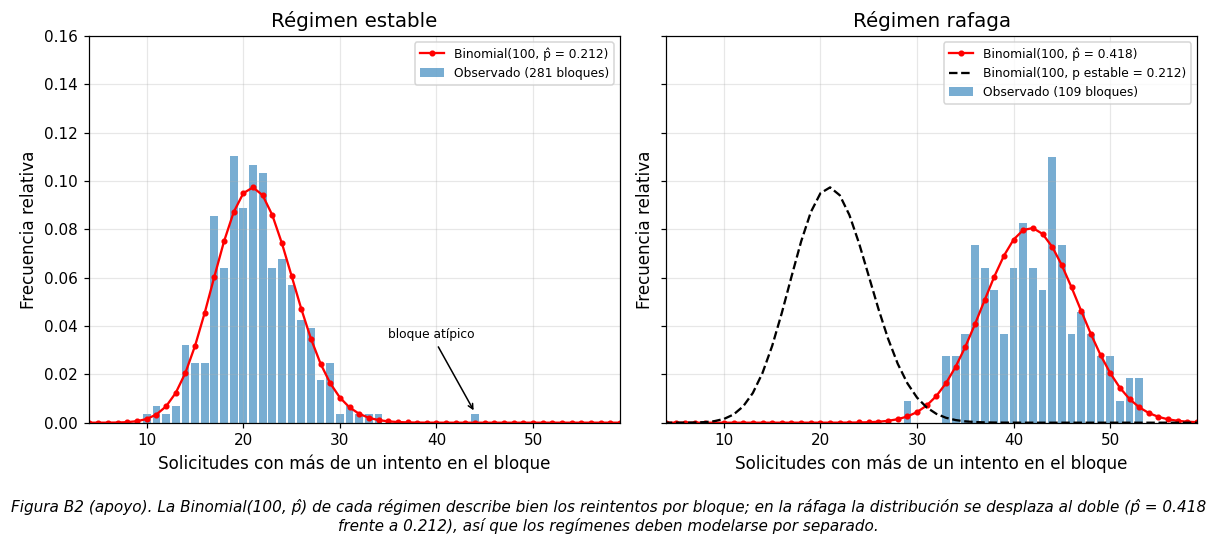

In [ ]:
# Paso 5. Gráfica de apoyo distribución de Y por régimen frente al modelo
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)    # mismo eje X para comparar los dos regímenes
x_lo = max(0, min(y.min() for y in Y.values()) - 6)             # límites del eje X que dejan ver todos los bloques
x_hi = min(TAM_BLOQUE, max(y.max() for y in Y.values()) + 6)
for a_, reg in zip(ax, ["estable", "rafaga"]):
    y, p_hat = Y[reg], EST[reg][0]
    k = np.arange(0, TAM_BLOQUE + 1)
    vals = np.arange(y.min(), y.max() + 1)
    a_.bar(vals, [(y == v).mean() for v in vals], color="tab:blue", alpha=0.6, label=f"Observado ({len(y)} bloques)")
    a_.plot(k, stats.binom.pmf(k, TAM_BLOQUE, p_hat), "ro-", ms=3, label=f"Binomial(100, p̂ = {p_hat:.3f})")
    if reg == "rafaga":                                         # en la ráfaga también se muestra el modelo del régimen estable
        a_.plot(k, stats.binom.pmf(k, TAM_BLOQUE, p_e), "k--", label=f"Binomial(100, p estable = {p_e:.3f})")
    for j in marcados[reg]:                                     # señala los bloques atípicos del paso 4d
        a_.annotate("bloque atípico", xy=(y[j], 0.004), xytext=(y[j] - 9, 0.035), fontsize=8,
                    arrowprops=dict(arrowstyle="->"))
    a_.set_xlim(x_lo, x_hi)
    a_.set_ylim(0, 0.16)                                        # deja espacio arriba para la leyenda
    a_.set_xlabel("Solicitudes con más de un intento en el bloque")
    a_.set_ylabel("Frecuencia relativa")
    a_.set_title(f"Régimen {reg}")
    a_.legend(fontsize=8, loc="upper right")
plt.tight_layout()
pie_de_figura(fig, "B2 (apoyo)",
              f"La Binomial(100, p̂) de cada régimen describe bien los reintentos por bloque; en la ráfaga la distribución "
              f"se desplaza al doble (p̂ = {p_r:.3f} frente a {p_e:.3f}), así que los regímenes deben modelarse por separado.")
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_B2.png"), bbox_inches="tight")
plt.show()

**Conclusión B2.**
- **Modelo.** En cada régimen, el número de solicitudes con más de un intento en un bloque de 100 sigue una **Binomial(100, p)**. Estable: $\hat p = 0{,}212$ (IC 90 % [0,208; 0,216], 281 bloques).
  Ráfaga: $\hat p = 0{,}418$ (IC 90 % [0,410; 0,426], 109 bloques). No se rechaza el modelo con el χ² de bondad de ajuste (p = 0,54 y 0,79), ni con el índice de dispersión (p = 0,16 y 0,70),
  ni hay autocorrelación entre bloques (p = 0,31 y 0,26), y $p$ es constante dentro de cada régimen (p = 0,68 y 0,33). Es decir, los datos son compatibles con reintentos independientes y con probabilidad constante dentro de cada régimen.
- **Discrepancia principal: la ráfaga no se parece al régimen estable.** El modelo del régimen estable predice 21,2 reintentos por bloque y en la ráfaga se observan 41,8 (z = 53); 90 % de los bloques de la ráfaga
  superan su cuantil 99,9 %. La probabilidad de reintento se duplica (cociente 1,97; diferencia 0,206, IC 90 % [0,197; 0,215]). No es sobredispersión (varianza/varianza binomial = 1,05): es un cambio de $p$, por eso hay que modelar los regímenes por separado.
- **Discrepancia menor, explicada: un bloque atípico en el régimen estable.** El exceso de varianza del régimen estable (1,12) lo causa un solo bloque, el que cubre [550,00; 551,97] s, con 44 reintentos
  (p = 5·10⁻⁷ frente a Bonferroni α/K = 3,6·10⁻⁴). En esa ventana hubo 100 llegadas en 2 s (se esperaban 54) y una proporción de reintentos compatible con la ráfaga (p = 0,73) y no con el régimen estable (p = 5·10⁻⁷).
  Es decir, la ráfaga termina unos 1 a 2 s después del corte de 550 s que dio la rejilla de 10 s de A2. Sin ese bloque, varianza/varianza binomial = 1,015 y p(dispersión) = 0,83; $\hat p$ casi no cambia (0,2121 → 0,2112).
  La conclusión de A2 se mantiene; solo hay que anotar que el borde de la ráfaga tiene una incertidumbre de 1 a 2 s.
- **Para B3.** Con la distribución de `intentos` (P(1) = 1 − p, P(2) = p(1 − p), P(3) = p²), el $\hat p$ de aquí estima la misma probabilidad de fallo por intento que B3. El MLE de B3 usa además cuántas solicitudes llegan a 2 y a 3 intentos, así que bajo el modelo ambas estimaciones deberían ser parecidas (no idénticas); B3 las compara.

### B3. Modelo de la variable intentos

### Modelo y deducción del estimador de máxima verosimilitud (la deducción manuscrita va en E3)

**Cómo se generan los datos.** Cada intento falla de forma independiente con probabilidad $q$ (y tiene éxito con $1-q$). El SDK reintenta hasta tener éxito, pero **abandona tras 3 fallos**. Por eso `intentos` es una **geométrica truncada en 3**, y para saber qué pasó en el tercer intento hay que mirar `exito`. Solo hay cuatro resultados posibles:

| (intentos, éxito) | Qué pasó | Probabilidad |
|---|---|---|
| (1, 1) | éxito al primer intento | $1-q$ |
| (2, 1) | falla y luego éxito | $q(1-q)$ |
| (3, 1) | dos fallas y luego éxito | $q^2(1-q)$ |
| (3, 0) | tres fallas, el SDK abandona | $q^3$ |

**Verosimilitud.** Cada solicitud aporta $q^{(\text{intentos fallidos})}(1-q)^{(\text{intentos exitosos})}$. Con $F$ = total de intentos fallidos y $S$ = total de intentos exitosos (= número de solicitudes con éxito):
$$L(q) = q^{F}(1-q)^{S}, \qquad \ell(q) = F\ln q + S\ln(1-q), \qquad \ell'(q) = \frac{F}{q} - \frac{S}{1-q} = 0 \;\Rightarrow\; \hat q = \frac{F}{F+S}.$$
Como $F + S = \sum_i \text{intentos}_i$, el estimador es simplemente **intentos fallidos / intentos totales**. La información observada es $F/q^2 + S/(1-q)^2$, así que $\widehat{\text{Var}}(\hat q) = \hat q(1-\hat q)/\sum_i \text{intentos}_i$.

**El estimador "inmediato"** trata `intentos` como una geométrica **sin** truncar: $E[I] = 1/(1-q)$, de donde $\tilde q = 1 - 1/\bar I$. Pero con el tope de 3 la media verdadera es $E[I] = 1 + q + q^2 < 1/(1-q)$, así que $\tilde q$ debería **subestimar** $q$. Esto se comprueba por simulación en el paso 3.

In [ ]:
# Paso 1. Tabla (intentos, éxito) en el régimen estable y estadísticos suficientes F y S
tabla_b3 = pd.crosstab(df_estable.intentos, df_estable.exito)
print(tabla_b3, "\n")

I = df_estable.intentos.to_numpy()                              # intentos por solicitud
E = df_estable.exito.to_numpy()                                 # 1 si algún intento tuvo éxito
S_b3 = int(E.sum())                                             # intentos exitosos (uno por solicitud con éxito)
N_int = int(I.sum())                                            # intentos totales
F_b3 = N_int - S_b3                                             # intentos fallidos
print(f"Solicitudes: {len(I)} | intentos totales: {N_int} | fallidos F = {F_b3} | exitosos S = {S_b3} | media de intentos = {I.mean():.4f}")

exito       0      1
intentos            
1           0  22192
2           0   4672
3         276   1022 

Solicitudes: 28162 | intentos totales: 35430 | fallidos F = 7544 | exitosos S = 27886 | media de intentos = 1.2581


**Paso 2. Estimación e intervalos.** Se reportan dos intervalos al nivel del grupo: Wald (con la información de Fisher) y el de **razón de verosimilitud**, $\{q: 2[\ell(\hat q) - \ell(q)] \le \chi^2_{1,1-\alpha}\}$, que no depende de la aproximación normal. Luego se valida el modelo comparando las frecuencias observadas de las 4 categorías con las que predice $\hat q$ (χ², con 4 − 1 − 1 = 2 grados de libertad).

In [ ]:
# Paso 2. MLE de q, intervalos y bondad de ajuste
q_mle = F_b3 / N_int                                            # MLE: intentos fallidos / intentos totales
ee_q = np.sqrt(q_mle * (1 - q_mle) / N_int)                     # error estándar (información de Fisher)
z_b3 = stats.norm.ppf(1 - alpha / 2)
print("q (MLE):", formatear_intervalo(q_mle, q_mle - z_b3 * ee_q, q_mle + z_b3 * ee_q, "Wald, información de Fisher", 4))

def logver_q(q):
    return F_b3 * np.log(q) + S_b3 * np.log(1 - q)
corte = logver_q(q_mle) - stats.chi2.ppf(1 - alpha, 1) / 2      # nivel de la log-verosimilitud que delimita el intervalo
rv_li = optimize.brentq(lambda q: logver_q(q) - corte, 1e-9, q_mle)
rv_ls = optimize.brentq(lambda q: logver_q(q) - corte, q_mle, 1 - 1e-9)
print("q (MLE):", formatear_intervalo(q_mle, rv_li, rv_ls, "razón de verosimilitud", 4))

# Bondad de ajuste de las 4 categorías (intentos, éxito)
obs_b3 = np.array([tabla_b3.loc[1, 1], tabla_b3.loc[2, 1], tabla_b3.loc[3, 1], tabla_b3.loc[3, 0]])
prob_b3 = np.array([1 - q_mle, q_mle * (1 - q_mle), q_mle**2 * (1 - q_mle), q_mle**3])
esp_b3 = len(I) * prob_b3
X2_b3 = ((obs_b3 - esp_b3) ** 2 / esp_b3).sum()
p_b3 = stats.chi2.sf(X2_b3, 2)                                  # 4 categorías - 1 - 1 parámetro estimado
print(pd.DataFrame({"categoría": ["(1, éxito)", "(2, éxito)", "(3, éxito)", "(3, abandono)"],
                    "observado": obs_b3, "esperado": esp_b3.round(1)}).to_string(index=False))
print(f"Chi^2 = {X2_b3:.2f}, gl = 2, p = {p_b3:.3f} -> {'se rechaza' if p_b3 < alpha else 'no se rechaza'} el modelo")

# Estimador inmediato (geométrica sin truncar) y estimador de momentos correcto (E[I] = 1 + q + q^2), con los datos
q_naive = 1 - 1 / I.mean()
q_mom = (-1 + np.sqrt(1 - 4 * (1 - I.mean()))) / 2             # raíz positiva de q^2 + q + 1 - media = 0
print(f"\nEstimador inmediato 1 - 1/media = {q_naive:.4f} | momentos con truncamiento = {q_mom:.4f} | MLE = {q_mle:.4f}")

q (MLE): 0.2129  [0.2093, 0.2165]  (IC 90%, método: Wald, información de Fisher)
q (MLE): 0.2129  [0.2094, 0.2165]  (IC 90%, método: razón de verosimilitud)
    categoría  observado  esperado
   (1, éxito)      22192   22165.6
   (2, éxito)       4672    4719.6
   (3, éxito)       1022    1004.9
(3, abandono)        276     271.9
Chi^2 = 0.86, gl = 2, p = 0.649 -> no se rechaza el modelo

Estimador inmediato 1 - 1/media = 0.2051 | momentos con truncamiento = 0.2128 | MLE = 0.2129


**Paso 3. ¿Es adecuado el estimador inmediato? Simulación calibrada.** Se simulan muchas muestras del mismo tamaño que los datos, generadas exactamente como el sistema real (intentos Bernoulli con $q = \hat q$ y abandono tras 3 fallos). En cada una se calculan el MLE y el estimador inmediato $\tilde q = 1 - 1/\bar I$, y se comparan su sesgo, su error cuadrático medio y la cobertura de sus intervalos de Wald al nivel 1 − α.

In [ ]:
# Paso 3. Simulación calibrada con q_mle: sesgo, ECM y cobertura de los dos estimadores
R_B3 = 2000                                                     # réplicas
n_b3 = len(I)                                                   # mismo tamaño de muestra que los datos
q_real = q_mle                                                  # parámetro verdadero de la simulación
cat_p = np.array([1 - q_real, q_real * (1 - q_real), q_real**2 * (1 - q_real), q_real**3])   # probabilidades de las 4 categorías
int_cat = np.array([1, 2, 3, 3]); exi_cat = np.array([1, 1, 1, 0])                           # intentos y éxito de cada categoría

res = {"MLE": [], "inmediato": []}
cubre = {"MLE": 0, "inmediato": 0}
for _ in range(R_B3):
    conteo = rng.multinomial(n_b3, cat_p)                       # cuántas solicitudes caen en cada categoría
    tot = (conteo * int_cat).sum()                              # intentos totales de la muestra simulada
    s = (conteo * exi_cat).sum()                                # intentos exitosos
    qm = (tot - s) / tot                                        # MLE
    media = tot / n_b3
    qn = 1 - 1 / media                                          # estimador inmediato
    res["MLE"].append(qm); res["inmediato"].append(qn)
    ee_m = np.sqrt(qm * (1 - qm) / tot)                         # Wald del MLE
    ee_n = np.sqrt(qn * (1 - qn) / tot)                         # Wald "ingenuo" del inmediato (mismo error estándar)
    cubre["MLE"] += abs(qm - q_real) <= z_b3 * ee_m
    cubre["inmediato"] += abs(qn - q_real) <= z_b3 * ee_n

resumen_b3 = pd.DataFrame({k: {"media": np.mean(v), "sesgo": np.mean(v) - q_real,
                               "desv. est.": np.std(v, ddof=1),
                               "sesgo / desv. est.": (np.mean(v) - q_real) / np.std(v, ddof=1),
                               "RECM": np.sqrt(np.mean((np.array(v) - q_real) ** 2)),
                               "cobertura IC": cubre[k] / R_B3} for k, v in res.items()}).T
print(f"q verdadero = {q_real:.4f}, n = {n_b3}, {R_B3} réplicas, nivel nominal = {nivel_confianza:.0%}")
print(resumen_b3.round(4).to_string())

q verdadero = 0.2129, n = 28162, 2000 réplicas, nivel nominal = 90%
            media   sesgo  desv. est.  sesgo / desv. est.    RECM  cobertura IC
MLE        0.2128 -0.0001      0.0022             -0.0505  0.0022         0.897
inmediato  0.2052 -0.0078      0.0020             -3.7976  0.0080         0.023


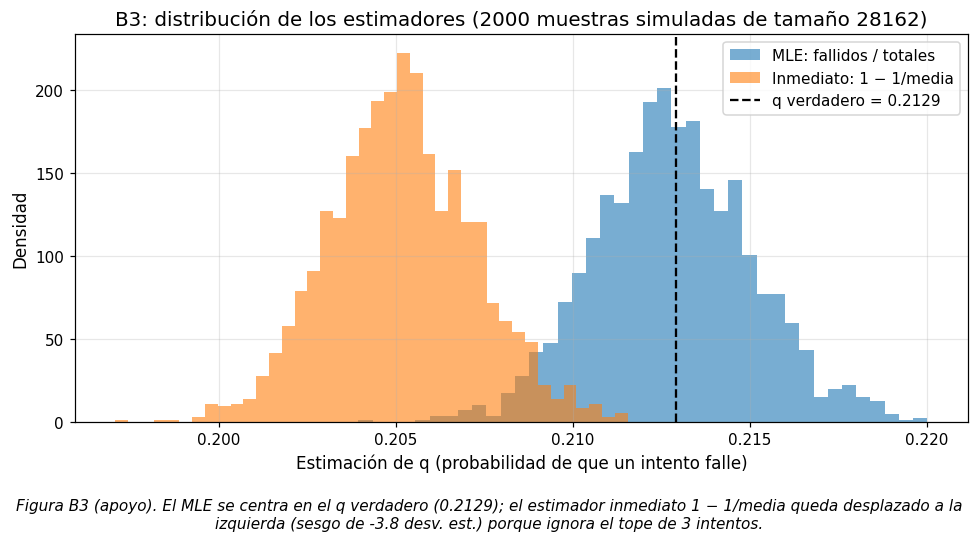

In [ ]:
# Gráfica de apoyo: distribución de los dos estimadores en la simulación
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(res["MLE"], bins=40, alpha=0.6, density=True, label="MLE: fallidos / totales")
ax.hist(res["inmediato"], bins=40, alpha=0.6, density=True, label="Inmediato: 1 − 1/media")
ax.axvline(q_real, color="black", linestyle="--", label=f"q verdadero = {q_real:.4f}")
ax.set_xlabel("Estimación de q (probabilidad de que un intento falle)")
ax.set_ylabel("Densidad")
ax.set_title(f"B3: distribución de los estimadores ({R_B3} muestras simuladas de tamaño {n_b3})")
ax.legend()
plt.tight_layout()
pie_de_figura(fig, "B3 (apoyo)",
              f"El MLE se centra en el q verdadero ({q_real:.4f}); el estimador inmediato 1 − 1/media queda desplazado a la izquierda "
              f"(sesgo de {resumen_b3.loc['inmediato', 'sesgo / desv. est.']:.1f} desv. est.) porque ignora el tope de 3 intentos.")
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_B3.png"), bbox_inches="tight")
plt.show()

**Conclusión B3.** `intentos` sigue una geométrica truncada en 3 con probabilidad de fallo por intento $q$; el MLE, que usa también `exito`, es intentos fallidos / intentos totales. El modelo ajusta bien las cuatro categorías. El estimador inmediato $1 - 1/\bar I$ **no es adecuado**: ignora el tope de 3 intentos, por lo que subestima $q$ de forma sistemática, con un sesgo varias veces mayor que su desviación estándar, y su intervalo casi nunca contiene el valor verdadero. El MLE es prácticamente insesgado y su intervalo tiene la cobertura nominal.

### B4. Reintentos en una ventana de 10 s

### Modelo (justificación de cada propiedad)

Sea $N_{10}$ el número de solicitudes que requieren más de un intento en una ventana de 10 s del régimen estable.
1. **Las llegadas son un proceso de Poisson de tasa λ** (validado en B1).
2. **Cada solicitud necesita reintento de forma independiente, con la misma probabilidad $p$**, y sin depender del instante en que llega. B2 mostró que $p$ es constante dentro del régimen y que no hay dependencia entre bloques; B3 mostró que los intentos son compatibles con fallos independientes.
3. **Adelgazamiento (thinning) de un proceso de Poisson:** si a cada llegada de un Poisson(λ) se le marca de forma independiente con probabilidad $p$, las llegadas marcadas forman otro proceso de Poisson, de tasa $\lambda p$.
4. **Incrementos estacionarios:** el número de eventos en cualquier ventana de largo $t$ sigue una Poisson$(\lambda p\, t)$, sin importar dónde empiece la ventana.

Por lo tanto $N_{10} \sim \text{Poisson}(\mu)$, con $\mu = 10\,\lambda p$, y
$$P(N_{10} \ge k) = 1 - \sum_{j=0}^{k-1} \frac{e^{-\mu}\mu^{j}}{j!}, \qquad k = \lceil\hat\mu\rceil + r.$$

In [ ]:
# Paso 1. Estimación de mu y de k
VENTANA = 10.0                                                  # segundos
n_reint = int((df_estable.intentos > 1).sum())                  # solicitudes con más de un intento en el régimen estable
p_reint = n_reint / len(df_estable)                             # p: proporción de solicitudes con reintento
mu_hat = VENTANA * n_reint / T_EST                              # = 10 * lambda_hat * p_hat (MLE por invariancia)
mu_li = VENTANA * stats.chi2.ppf(alpha / 2, 2 * n_reint) / (2 * T_EST)          # IC exacto (Garwood) para la tasa de reintentos
mu_ls = VENTANA * stats.chi2.ppf(1 - alpha / 2, 2 * n_reint + 2) / (2 * T_EST)
k_b4 = int(np.ceil(mu_hat)) + r                                 # umbral del enunciado: ceil(mu) + r
print(f"lambda = {lam_hat:.3f} sol/s, p = {p_reint:.4f} -> tasa de reintentos lambda*p = {n_reint / T_EST:.3f} sol/s")
print("mu (reintentos esperados en 10 s):", formatear_intervalo(mu_hat, mu_li, mu_ls, "Poisson exacto (Garwood)", 2))
print(f"r = {r} -> k = ceil({mu_hat:.2f}) + {r} = {k_b4}")

lambda = 27.610 sol/s, p = 0.2120 -> tasa de reintentos lambda*p = 5.853 sol/s
mu (reintentos esperados en 10 s): 58.53  [57.29, 59.79]  (IC 90%, método: Poisson exacto (Garwood))
r = 0 -> k = ceil(58.53) + 0 = 59


**Paso 2. Cálculo analítico.** Se evalúa la cola de la Poisson$(\hat\mu)$. Como $\hat\mu$ es grande, también se muestra la aproximación normal con corrección por continuidad, $P(N \ge k) \approx 1 - \Phi\left(\frac{k - 0.5 - \mu}{\sqrt{\mu}}\right)$, y cómo cambia la probabilidad en los extremos del intervalo de $\mu$.

In [ ]:
# Paso 2. Probabilidad analítica P(N >= k) con N ~ Poisson(mu)
p_analitica = stats.poisson.sf(k_b4 - 1, mu_hat)                # sf(k - 1) = P(N >= k)
p_normal = stats.norm.sf((k_b4 - 0.5 - mu_hat) / np.sqrt(mu_hat))   # aproximación normal con corrección por continuidad
print(f"P(N_10 >= {k_b4}) exacta (Poisson)      = {p_analitica:.4f}")
print(f"P(N_10 >= {k_b4}) aproximación normal   = {p_normal:.4f}")
print(f"Sensibilidad a mu: con mu = {mu_li:.2f} -> {stats.poisson.sf(k_b4 - 1, mu_li):.4f}; "
      f"con mu = {mu_ls:.2f} -> {stats.poisson.sf(k_b4 - 1, mu_ls):.4f}")

P(N_10 >= 59) exacta (Poisson)      = 0.4928
P(N_10 >= 59) aproximación normal   = 0.5015
Sensibilidad a mu: con mu = 57.29 -> 0.4280; con mu = 59.79 -> 0.5580


**Paso 3. Verificación por Montecarlo.** Se simula el mecanismo completo, **sin usar la fórmula de la Poisson**: en cada réplica se generan las llegadas de una ventana de 10 s con tiempos entre llegadas Exponenciales(λ̂), a cada solicitud se le decide de forma independiente si necesita reintento (probabilidad $\hat p$), y se cuenta cuántas lo necesitaron. Además, como contraste empírico, se cuentan los reintentos en las 102 ventanas reales de 10 s del régimen estable.

In [ ]:
# Paso 3. Montecarlo del mecanismo llegadas + reintentos
R_B4 = 100_000                                                  # réplicas
conteos_mc = np.empty(R_B4, dtype=int)
for i_rep in range(R_B4):
    t_acum, n_ventana = 0.0, 0
    while True:                                                 # llegadas de una ventana de 10 s (proceso de Poisson)
        t_acum += rng.exponential(1 / lam_hat)
        if t_acum > VENTANA:
            break
        n_ventana += 1
    conteos_mc[i_rep] = rng.binomial(n_ventana, p_reint)        # cada llegada necesita reintento con probabilidad p
p_mc = (conteos_mc >= k_b4).mean()
ee_mc = np.sqrt(p_mc * (1 - p_mc) / R_B4)                       # error de Montecarlo
z_b4 = stats.norm.ppf(1 - alpha / 2)
print("P(N_10 >= k) por Montecarlo:", formatear_intervalo(p_mc, p_mc - z_b4 * ee_mc, p_mc + z_b4 * ee_mc, f"Wald, {R_B4} réplicas", 4))
print(f"Analítica = {p_analitica:.4f} -> {'dentro' if abs(p_mc - p_analitica) <= z_b4 * ee_mc else 'fuera'} del intervalo de Montecarlo")
print(f"Media y varianza simuladas: {conteos_mc.mean():.2f} y {conteos_mc.var(ddof=1):.2f} (Poisson: ambas = {mu_hat:.2f})")

# Contraste con los datos: reintentos en las ventanas reales de 10 s del régimen estable
reint_t = df_estable.t_llegada_s[df_estable.intentos > 1]
c_real = np.concatenate([np.histogram(reint_t[(reint_t >= a) & (reint_t < b)], bins=np.arange(a, b + VENTANA, VENTANA))[0]
                         for a, b in tramos])
def dispersion(c):
    """Varianza/media y valor p bilateral del índice de dispersión (Poisson: varianza = media)."""
    D = ((c - c.mean()) ** 2 / c.mean()).sum()
    return c.var(ddof=1) / c.mean(), 2 * min(stats.chi2.sf(D, len(c) - 1), stats.chi2.cdf(D, len(c) - 1))

print(f"Datos: {len(c_real)} ventanas, media = {c_real.mean():.2f}, varianza = {c_real.var(ddof=1):.2f}, "
      f"fracción con N >= {k_b4}: {(c_real >= k_b4).mean():.3f}")
vm, pv = dispersion(c_real)
i_max = int(np.argmax(c_real))                                  # ventana con más reintentos
a_max = FIN + (i_max - len(np.arange(0, INI, VENTANA))) * VENTANA if i_max >= INI / VENTANA else i_max * VENTANA
print(f"  varianza/media = {vm:.3f} (p = {pv:.3f}); la ventana con más reintentos es [{a_max:.0f}, {a_max + VENTANA:.0f}) s, con {c_real[i_max]}")
vm2, pv2 = dispersion(np.delete(c_real, i_max))
print(f"  sin esa ventana (cola de la ráfaga, ver B2): varianza/media = {vm2:.3f} (p = {pv2:.3f})")

P(N_10 >= k) por Montecarlo: 0.4921  [0.4895, 0.4947]  (IC 90%, método: Wald, 100000 réplicas)
Analítica = 0.4928 -> dentro del intervalo de Montecarlo
Media y varianza simuladas: 58.50 y 58.54 (Poisson: ambas = 58.53)
Datos: 102 ventanas, media = 58.53, varianza = 73.02, fracción con N >= 59: 0.480
  varianza/media = 1.248 (p = 0.093); la ventana con más reintentos es [550, 560) s, con 88
  sin esa ventana (cola de la ráfaga, ver B2): varianza/media = 1.116 (p = 0.403)


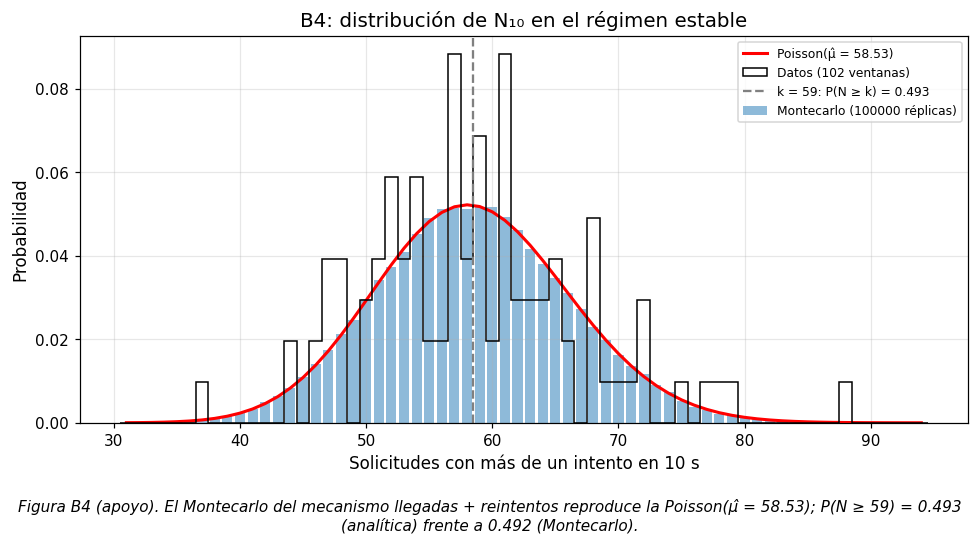

In [ ]:
# Gráfica de apoyo: distribución de N_10 (Poisson, Montecarlo y datos) con el umbral k
fig, ax = plt.subplots(figsize=(9, 4.5))
vals = np.arange(conteos_mc.min(), conteos_mc.max() + 1)
ax.bar(vals, [(conteos_mc == v).mean() for v in vals], color="tab:blue", alpha=0.5, label=f"Montecarlo ({R_B4} réplicas)")
ax.plot(vals, stats.poisson.pmf(vals, mu_hat), "r-", lw=2, label=f"Poisson(μ̂ = {mu_hat:.2f})")
ax.hist(c_real, bins=np.arange(vals.min(), vals.max() + 2) - 0.5, density=True, histtype="step", color="black",
        lw=1.5, label=f"Datos ({len(c_real)} ventanas)")
ax.axvline(k_b4 - 0.5, color="grey", linestyle="--", label=f"k = {k_b4}: P(N ≥ k) = {p_analitica:.3f}")
ax.set_xlabel("Solicitudes con más de un intento en 10 s")
ax.set_ylabel("Probabilidad")
ax.set_title("B4: distribución de N₁₀ en el régimen estable")
ax.legend(fontsize=8)
plt.tight_layout()
pie_de_figura(fig, "B4 (apoyo)",
              f"El Montecarlo del mecanismo llegadas + reintentos reproduce la Poisson(μ̂ = {mu_hat:.2f}); "
              f"P(N ≥ {k_b4}) = {p_analitica:.3f} (analítica) frente a {p_mc:.3f} (Montecarlo).")
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_B4.png"), bbox_inches="tight")
plt.show()

**Conclusión B4.** Por adelgazamiento del proceso de Poisson, las solicitudes que requieren reintento llegan como un Poisson de tasa λp, y en 10 s su número es Poisson(μ̂). La probabilidad de alcanzar al menos k reintentos se calcula de forma exacta con la cola de la Poisson, y la simulación del mecanismo completo da el mismo valor dentro de su error de Montecarlo. Como k = ⌈μ̂⌉ + r con r = 0, k queda apenas por encima de la media, y la probabilidad es cercana a 1/2. En los datos reales, la única ventana que se sale del modelo es la primera después de la ráfaga (su cola, como en B2); sin ella, los conteos de 10 s son compatibles con una Poisson.

# Parte C - Tiempo de cómputo y tiempo de red (14 pts)

### C1. Distribución de G (todas las solicitudes)

### Naturaleza de G y su función de distribución (la deducción manuscrita va en E3)

Se usan **todas** las solicitudes del régimen estable, con las cacheadas incluidas. Si la solicitud se responde desde caché, la GPU no trabaja y $G = 0$ exactamente; si no, $G$ es un tiempo de cómputo positivo que puede tomar cualquier valor en un intervalo. Por eso $G$ es una **variable mixta**: una masa de probabilidad $c = P(\text{caché})$ en el punto 0, más una parte continua $C$ (el tiempo de GPU de las no cacheadas), con función de distribución $F_C$ y $F_C(0) = 0$.

$$F_G(g) = P(G \le g) = \begin{cases} 0, & g < 0 \\ c + (1-c)\,F_C(g), & g \ge 0 \end{cases}$$

$F_G$ tiene un **salto de altura $c$ en 0** (no es continua) y después crece de forma continua (no es discreta).

**Momentos.** Con $m = E[C]$ y $v = \text{Var}(C)$, por la ley de la esperanza total condicionando en si hubo caché:
$$E[G] = c\cdot 0 + (1-c)\,m = (1-c)\,m, \qquad E[G^2] = (1-c)(v + m^2),$$
$$\text{Var}(G) = E[G^2] - E[G]^2 = (1-c)\,v + c\,(1-c)\,m^2.$$
El segundo término, $c(1-c)m^2$, es la varianza que agrega la mezcla de "cero o no cero": aunque $C$ tuviera varianza 0, $G$ tendría varianza por el solo hecho de ser a veces 0.

In [ ]:
# Paso 1. Evidencia de la naturaleza mixta de G y estimación de los parámetros c, m, v
G = df_estable.gpu_ms.to_numpy()                                # G de todas las solicitudes del régimen estable
cache = df_estable.cache_hit.to_numpy() == 1
G_cont = G[~cache]                                              # parte continua: solicitudes no cacheadas
n_G, n_cache = len(G), int(cache.sum())

print(f"Solicitudes: {n_G} | con caché: {n_cache} | P(G = 0) observada = {(G == 0).mean():.4f}")
print(f"¿Toda solicitud con caché tiene G = 0? {bool((G[cache] == 0).all())} | ¿alguna sin caché tiene G = 0? {bool((G_cont == 0).any())}")
print(f"Parte continua: {len(G_cont)} valores entre {G_cont.min():.2f} y {G_cont.max():.2f} ms, "
      f"{len(np.unique(G_cont))} valores distintos (las repeticiones se deben solo al redondeo a 0,01 ms)")

c_hat = n_cache / n_G                                           # MLE de c (proporción cacheada)
c_li = stats.beta.ppf(alpha / 2, n_cache, n_G - n_cache + 1)    # IC exacto de Clopper-Pearson
c_ls = stats.beta.ppf(1 - alpha / 2, n_cache + 1, n_G - n_cache)
m_hat, v_hat = G_cont.mean(), G_cont.var(ddof=1)                # media y varianza de la parte continua
print("\nc = P(caché):", formatear_intervalo(c_hat, c_li, c_ls, "Clopper-Pearson", 4))
print(f"m = E[C] = {m_hat:.3f} ms | v = Var(C) = {v_hat:.2f} ms^2 (desv. est. {np.sqrt(v_hat):.2f} ms)")

Solicitudes: 28162 | con caché: 9458 | P(G = 0) observada = 0.3358
¿Toda solicitud con caché tiene G = 0? True | ¿alguna sin caché tiene G = 0? False
Parte continua: 18704 valores entre 2.06 y 295.47 ms, 7258 valores distintos (las repeticiones se deben solo al redondeo a 0,01 ms)

c = P(caché): 0.3358  [0.3312, 0.3405]  (IC 90%, método: Clopper-Pearson)
m = E[C] = 39.229 ms | v = Var(C) = 665.75 ms^2 (desv. est. 25.80 ms)


**Paso 2. Momentos teóricos frente a muestrales.** Se evalúan las fórmulas con $\hat c, \hat m, \hat v$ y se comparan con la media y la varianza muestrales de $G$ calculadas directamente sobre todas las solicitudes. Para cuantificar la incertidumbre se dan intervalos por **bootstrap** (se remuestrean solicitudes, se re-estiman $c, m, v$ y se recalculan las fórmulas). También se muestra la descomposición de la varianza: cuánto viene de la parte continua y cuánto de la masa en 0.

In [ ]:
# Paso 2. E[G] y Var(G): fórmulas del modelo vs. valores muestrales, con IC bootstrap
def momentos_formula(g, es_cache):
    """E[G] y Var(G) con las fórmulas del modelo mixto, a partir de una muestra."""
    c_ = es_cache.mean(); x = g[~es_cache]
    m_, v_ = x.mean(), x.var(ddof=1)
    return (1 - c_) * m_, (1 - c_) * v_ + c_ * (1 - c_) * m_**2

EG_f, VG_f = momentos_formula(G, cache)                          # fórmulas
EG_m, VG_m = G.mean(), G.var(ddof=1)                             # directamente de la muestra

B_C1 = 2000
boot = np.empty((B_C1, 2))
for b in range(B_C1):
    idx = rng.integers(0, n_G, n_G)                              # remuestreo de solicitudes con reemplazo
    boot[b] = momentos_formula(G[idx], cache[idx])
li_E, ls_E = np.quantile(boot[:, 0], [alpha / 2, 1 - alpha / 2])
li_V, ls_V = np.quantile(boot[:, 1], [alpha / 2, 1 - alpha / 2])

print("E[G] fórmula (1-c)m:            ", formatear_intervalo(EG_f, li_E, ls_E, "bootstrap percentil", 3), f"| muestral = {EG_m:.3f} ms")
print("Var(G) fórmula (1-c)v + c(1-c)m^2:", formatear_intervalo(VG_f, li_V, ls_V, "bootstrap percentil", 1), f"| muestral = {VG_m:.1f} ms^2")
print(f"Diferencia relativa: E[G] {100 * (EG_f / EG_m - 1):+.4f} %, Var(G) {100 * (VG_f / VG_m - 1):+.4f} %")

parte_cont = (1 - c_hat) * v_hat                                 # varianza que aporta la parte continua
parte_mezcla = c_hat * (1 - c_hat) * m_hat**2                    # varianza que aporta la masa en 0
print(f"\nDescomposición de Var(G): parte continua (1-c)v = {parte_cont:.1f} ({100 * parte_cont / VG_f:.1f} %), "
      f"masa en 0 c(1-c)m^2 = {parte_mezcla:.1f} ({100 * parte_mezcla / VG_f:.1f} %)")
print(f"Si se ignorara la masa en 0 y se usara solo la parte continua: media {m_hat:.2f} ms (vs {EG_m:.2f}), varianza {v_hat:.1f} (vs {VG_m:.1f})")

E[G] fórmula (1-c)m:             26.054  [25.775, 26.322]  (IC 90%, método: bootstrap percentil) | muestral = 26.054 ms
Var(G) fórmula (1-c)v + c(1-c)m^2: 785.4  [766.5, 805.0]  (IC 90%, método: bootstrap percentil) | muestral = 785.4 ms^2
Diferencia relativa: E[G] -0.0000 %, Var(G) -0.0005 %

Descomposición de Var(G): parte continua (1-c)v = 442.2 (56.3 %), masa en 0 c(1-c)m^2 = 343.3 (43.7 %)
Si se ignorara la masa en 0 y se usara solo la parte continua: media 39.23 ms (vs 26.05), varianza 665.8 (vs 785.4)


**Paso 3. Verificación por simulación.** Las fórmulas no dependen de la forma de $F_C$, solo de $m$ y $v$. Para comprobarlo se simula $G$ como mezcla — con probabilidad $\hat c$ vale 0 y si no se toma de una distribución continua con media $\hat m$ y varianza $\hat v$ — usando dos formas distintas de $F_C$: una Gamma ajustada por momentos y la distribución empírica de las no cacheadas.

In [ ]:
# Paso 3. Simulación de la mezcla con dos formas distintas de la parte continua
N_SIM_C1 = 1_000_000
es_cero = rng.random(N_SIM_C1) < c_hat                           # 0 con probabilidad c
forma_k, escala = m_hat**2 / v_hat, v_hat / m_hat               # Gamma con la misma media y varianza
sim_gamma = np.where(es_cero, 0.0, rng.gamma(forma_k, escala, N_SIM_C1))
sim_emp = np.where(es_cero, 0.0, rng.choice(G_cont, N_SIM_C1))  # parte continua remuestreada de los datos
for nombre, s in [("Gamma por momentos", sim_gamma), ("empírica", sim_emp)]:
    print(f"Simulación ({nombre:18s}): E[G] = {s.mean():.3f} (fórmula {EG_f:.3f}) | Var(G) = {s.var():.1f} (fórmula {VG_f:.1f}) | P(G = 0) = {(s == 0).mean():.4f}")

Simulación (Gamma por momentos): E[G] = 26.073 (fórmula 26.054) | Var(G) = 786.5 (fórmula 785.4) | P(G = 0) = 0.3362
Simulación (empírica          ): E[G] = 26.074 (fórmula 26.054) | Var(G) = 787.0 (fórmula 785.4) | P(G = 0) = 0.3362


### Figura 2
A la izquierda, la función de distribución acumulada empírica de $G$: el **salto vertical en 0** es la masa de las solicitudes cacheadas. A la derecha, la densidad de la parte continua.

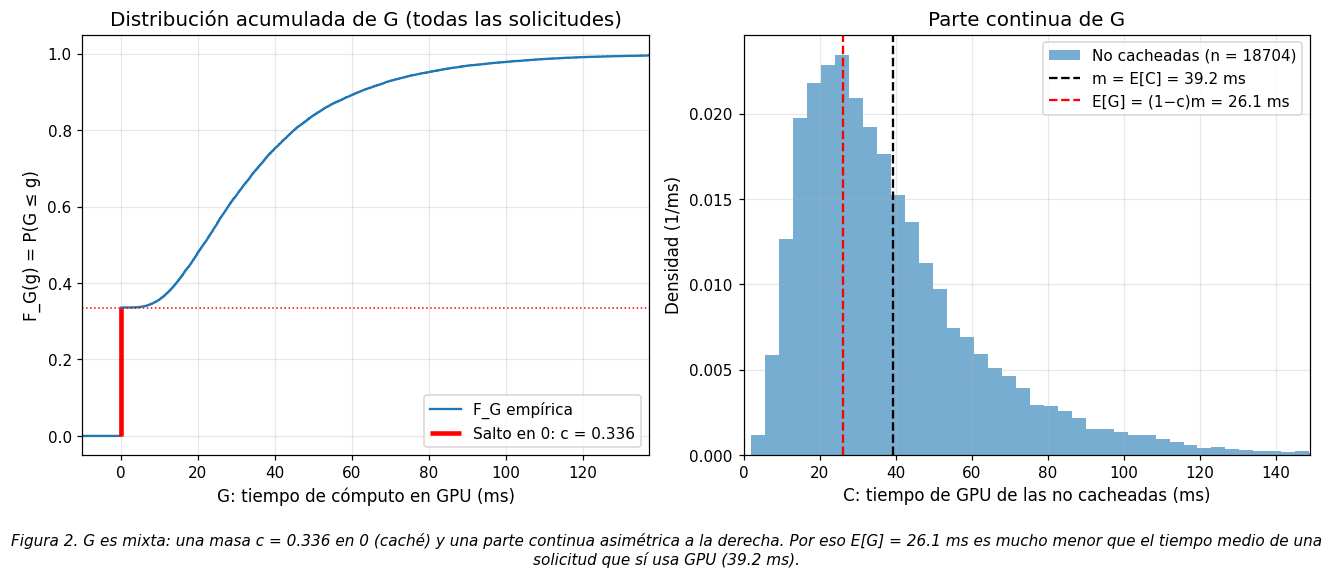

In [ ]:
# Figura 2. Distribución de G: salto en 0 (caché) y parte continua
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))

g_ord = np.sort(G)
F_emp = np.arange(1, n_G + 1) / n_G                             # distribución acumulada empírica
ax[0].step(np.r_[-10, g_ord], np.r_[0, F_emp], where="post", color="tab:blue", label="F_G empírica")
ax[0].vlines(0, 0, c_hat, color="red", lw=3, label=f"Salto en 0: c = {c_hat:.3f}")
ax[0].axhline(c_hat, color="red", linestyle=":", lw=1)
ax[0].set_xlim(-10, np.quantile(G, 0.995))
ax[0].set_xlabel("G: tiempo de cómputo en GPU (ms)")
ax[0].set_ylabel("F_G(g) = P(G ≤ g)")
ax[0].set_title("Distribución acumulada de G (todas las solicitudes)")
ax[0].legend(loc="lower right")

ax[1].hist(G_cont, bins=80, density=True, color="tab:blue", alpha=0.6, label=f"No cacheadas (n = {len(G_cont)})")
ax[1].axvline(m_hat, color="black", linestyle="--", label=f"m = E[C] = {m_hat:.1f} ms")
ax[1].axvline(EG_f, color="red", linestyle="--", label=f"E[G] = (1−c)m = {EG_f:.1f} ms")
ax[1].set_xlim(0, np.quantile(G_cont, 0.995))
ax[1].set_xlabel("C: tiempo de GPU de las no cacheadas (ms)")
ax[1].set_ylabel("Densidad (1/ms)")
ax[1].set_title("Parte continua de G")
ax[1].legend()

pie_de_figura(fig, 2, f"G es mixta: una masa c = {c_hat:.3f} en 0 (caché) y una parte continua asimétrica a la derecha. "
                      f"Por eso E[G] = {EG_f:.1f} ms es mucho menor que el tiempo medio de una solicitud que sí usa GPU ({m_hat:.1f} ms).")
plt.tight_layout()
guardar_figura(fig, 2)
plt.show()

**Conclusión C1.** $G$ es una variable mixta: vale 0 con probabilidad $c$ (caché) y es continua y positiva en el resto. Su función de distribución tiene un salto de altura $c$ en 0. Las fórmulas $E[G] = (1-c)m$ y $\text{Var}(G) = (1-c)v + c(1-c)m^2$ reproducen los valores muestrales, y la simulación confirma que valen para cualquier forma de la parte continua. Una parte importante de la varianza de $G$ viene solo de la mezcla entre 0 y no 0. La forma de la parte continua se modela en C2.

### C2. Máxima verosimilitud para la parte continua de G

**Qué se modela.** La parte continua de $G$: el tiempo de GPU $X$ de las solicitudes **no cacheadas** del régimen estable. Es positiva y asimétrica a la derecha (A3 y C1), así que se comparan dos familias habituales para tiempos de servicio:
- **Lognormal**$(\mu, \sigma)$: $\ln X \sim N(\mu, \sigma^2)$, con densidad $f(x) = \frac{1}{x\sigma\sqrt{2\pi}}\exp\!\left(-\frac{(\ln x - \mu)^2}{2\sigma^2}\right)$.
- **Gamma**$(k, \theta)$: $f(x) = \frac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\,\theta^k}$.

**Log-verosimilitudes escritas por el grupo** (con $n$ observaciones):
$$\ell_{LN}(\mu,\sigma) = -\sum_i \ln x_i - n\ln\sigma - \tfrac{n}{2}\ln(2\pi) - \frac{1}{2\sigma^2}\sum_i(\ln x_i - \mu)^2$$
$$\ell_{\Gamma}(k,\theta) = (k-1)\sum_i \ln x_i - \frac{1}{\theta}\sum_i x_i - n\ln\Gamma(k) - nk\ln\theta$$
Se maximizan **numéricamente** con `scipy.optimize.minimize` sobre parámetros transformados ($\ln\sigma$, $\ln k$, $\ln\theta$) para que siempre sean positivos. Los errores estándar salen de la **inversa del Hessiano** de $-\ell$ en el óptimo (información observada).

In [ ]:
# Paso 1. Máxima verosimilitud implementada por el grupo (log-verosimilitud + optimización numérica)
from scipy import special                                       # gammaln = ln Gamma(k), para la log-verosimilitud gamma
X_gpu = df_estable.gpu_ms[df_estable.cache_hit == 0].to_numpy()   # parte continua de G (ms)
n_x2 = len(X_gpu)
lx, sum_lx, sum_x = np.log(X_gpu), np.log(X_gpu).sum(), X_gpu.sum()   # estadísticos suficientes


def nll_lognormal(par):
    """Menos la log-verosimilitud lognormal; par = (mu, ln sigma)."""
    mu, sig = par[0], np.exp(par[1])
    return -(-sum_lx - n_x2 * np.log(sig) - 0.5 * n_x2 * np.log(2 * np.pi) - ((lx - mu) ** 2).sum() / (2 * sig**2))


def nll_gamma(par):
    """Menos la log-verosimilitud gamma; par = (ln k, ln theta)."""
    k, th = np.exp(par)
    return -((k - 1) * sum_lx - sum_x / th - n_x2 * special.gammaln(k) - n_x2 * k * np.log(th))


def hessiano(f, p, h=1e-4):
    """Hessiano numérico por diferencias centrales."""
    p = np.asarray(p, float); H = np.zeros((len(p), len(p)))
    for i in range(len(p)):
        for j in range(len(p)):
            e_i, e_j = np.eye(len(p))[i] * h, np.eye(len(p))[j] * h
            H[i, j] = (f(p + e_i + e_j) - f(p + e_i - e_j) - f(p - e_i + e_j) + f(p - e_i - e_j)) / (4 * h * h)
    return H


z_c2 = stats.norm.ppf(1 - alpha / 2)
ajustes = {}
for nombre, nll, p0, nombres in [("Lognormal", nll_lognormal, [np.log(X_gpu.mean()), 0.0], ["mu", "sigma"]),
                                  ("Gamma", nll_gamma, [0.0, np.log(X_gpu.mean())], ["k", "theta"])]:
    opt = optimize.minimize(nll, p0, method="Nelder-Mead", options={"xatol": 1e-9, "fatol": 1e-9, "maxiter": 5000})
    cov_t = np.linalg.inv(hessiano(nll, opt.x))                 # covarianza en la escala transformada
    if nombre == "Lognormal":                                   # (mu, ln sigma) -> (mu, sigma) por el método delta
        est = np.array([opt.x[0], np.exp(opt.x[1])]); jac = np.diag([1.0, est[1]])
    else:                                                       # (ln k, ln theta) -> (k, theta)
        est = np.exp(opt.x); jac = np.diag(est)
    ee = np.sqrt(np.diag(jac @ cov_t @ jac.T))
    ll_max = -opt.fun
    ajustes[nombre] = {"est": est, "ee": ee, "ll": ll_max, "AIC": 2 * 2 - 2 * ll_max}
    print(f"{nombre}: log-verosimilitud máxima = {ll_max:.1f}, AIC = {2 * 2 - 2 * ll_max:.1f}, convergió = {opt.success}")
    for nom_p, e_p, s_p in zip(nombres, est, ee):
        print(f"   {nom_p:6s}:", formatear_intervalo(e_p, e_p - z_c2 * s_p, e_p + z_c2 * s_p, "Wald, Hessiano numérico", 4))

# Verificación: la lognormal tiene MLE en forma cerrada (media y desv. est. de ln x con divisor n)
print(f"\nComprobación lognormal (forma cerrada): mu = {lx.mean():.4f}, sigma = {lx.std(ddof=0):.4f}")
print(f"Diferencia de AIC (Gamma - Lognormal) = {ajustes['Gamma']['AIC'] - ajustes['Lognormal']['AIC']:.1f} -> se prefiere la "
      f"{'Lognormal' if ajustes['Lognormal']['AIC'] < ajustes['Gamma']['AIC'] else 'Gamma'}")

Lognormal: log-verosimilitud máxima = -82743.7, AIC = 165491.3, convergió = True
   mu    : 3.4809  [3.4734, 3.4883]  (IC 90%, método: Wald, Hessiano numérico)
   sigma : 0.6213  [0.6160, 0.6266]  (IC 90%, método: Wald, Hessiano numérico)
Gamma: log-verosimilitud máxima = -83093.6, AIC = 166191.2, convergió = True
   k     : 2.8074  [2.7622, 2.8526]  (IC 90%, método: Wald, Hessiano numérico)
   theta : 13.9732  [13.7268, 14.2195]  (IC 90%, método: Wald, Hessiano numérico)

Comprobación lognormal (forma cerrada): mu = 3.4809, sigma = 0.6213
Diferencia de AIC (Gamma - Lognormal) = 699.9 -> se prefiere la Lognormal


**Paso 2. Otro método de estimación: momentos.** Para la lognormal, $E[X] = e^{\mu + \sigma^2/2}$ y $\text{Var}(X) = (e^{\sigma^2} - 1)\,E[X]^2$. Igualando a la media $\bar x$ y la varianza $s^2$ muestrales: $\tilde\sigma^2 = \ln(1 + s^2/\bar x^2)$ y $\tilde\mu = \ln\bar x - \tilde\sigma^2/2$. Se comparan las estimaciones, la log-verosimilitud que alcanza cada una y los cuantiles que predicen.

In [ ]:
# Paso 2. Lognormal por el método de momentos y comparación con el MLE
mu_mle, sig_mle = ajustes["Lognormal"]["est"]
s2_mom = np.log(1 + X_gpu.var(ddof=1) / X_gpu.mean() ** 2)
sig_mom, mu_mom = np.sqrt(s2_mom), np.log(X_gpu.mean()) - s2_mom / 2

cuantiles = [0.5, 0.9, 0.99, 0.999]
comp_c2 = pd.DataFrame({
    "MLE": [mu_mle, sig_mle, -nll_lognormal([mu_mle, np.log(sig_mle)]), np.exp(mu_mle + sig_mle**2 / 2)]
           + list(stats.lognorm.ppf(cuantiles, sig_mle, scale=np.exp(mu_mle))),
    "Momentos": [mu_mom, sig_mom, -nll_lognormal([mu_mom, np.log(sig_mom)]), np.exp(mu_mom + sig_mom**2 / 2)]
                + list(stats.lognorm.ppf(cuantiles, sig_mom, scale=np.exp(mu_mom))),
    "Datos": [np.nan, np.nan, np.nan, X_gpu.mean()] + list(np.quantile(X_gpu, cuantiles)),
}, index=["mu", "sigma", "log-verosimilitud", "media (ms)"] + [f"percentil {100 * q:g} (ms)" for q in cuantiles])
print(comp_c2.round(3).to_string())

                           MLE   Momentos    Datos
mu                       3.481      3.490      NaN
sigma                    0.621      0.600      NaN
log-verosimilitud   -82743.659 -82769.895      NaN
media (ms)              39.404     39.229   39.229
percentil 50 (ms)       32.488     32.775   32.910
percentil 90 (ms)       72.030     70.673   71.857
percentil 99 (ms)      137.855    132.225  128.709
percentil 99.9 (ms)    221.583    209.038  201.863


**Paso 3. Bondad de ajuste (numérica y gráfica).**
1. **Kolmogórov-Smirnov** con valor p por **bootstrap paramétrico** (los parámetros se estimaron con los mismos datos, así que la tabla clásica no sirve).
2. **χ² de bondad de ajuste** con 20 clases equiprobables bajo el modelo (grados de libertad: 20 − 1 − 2).
3. **QQ-plot** y comparación de densidades en la gráfica de apoyo.

In [ ]:
# Paso 3. KS con bootstrap paramétrico y chi^2 con clases equiprobables, para los dos modelos MLE
B_C2 = 500
param_scipy = {"Lognormal": lambda e: (stats.lognorm, (e[1], 0, np.exp(e[0]))),
               "Gamma": lambda e: (stats.gamma, (e[0], 0, e[1]))}
for nombre in ["Lognormal", "Gamma"]:
    dist, par = param_scipy[nombre](ajustes[nombre]["est"])
    D_obs = stats.kstest(X_gpu, dist.cdf, args=par).statistic
    D_boot = np.empty(B_C2)
    for b in range(B_C2):
        xb = dist.rvs(*par, size=n_x2, random_state=rng)        # muestra simulada bajo el modelo
        if nombre == "Lognormal":                               # se re-estima en cada réplica (MLE en forma cerrada)
            pb = (np.log(xb).std(ddof=0), 0, np.exp(np.log(xb).mean()))
        else:
            pb = stats.gamma.fit(xb, floc=0)
        D_boot[b] = stats.kstest(xb, dist.cdf, args=pb).statistic
    p_ks2 = (1 + (D_boot >= D_obs).sum()) / (B_C2 + 1)

    bordes = dist.ppf(np.linspace(0, 1, 21), *par)              # 20 clases equiprobables bajo el modelo
    obs_c = np.histogram(X_gpu, bins=bordes)[0]
    esp_c = np.full(20, n_x2 / 20)
    X2_c2 = ((obs_c - esp_c) ** 2 / esp_c).sum()
    p_chi_c2 = stats.chi2.sf(X2_c2, 20 - 1 - 2)
    ajustes[nombre].update({"KS": D_obs, "p_KS": p_ks2, "X2": X2_c2, "p_X2": p_chi_c2})
    print(f"{nombre:9s}: KS D = {D_obs:.4f}, p bootstrap = {p_ks2:.3f} | chi^2 = {X2_c2:.1f} (gl 17), p = {p_chi_c2:.2e}")

Lognormal: KS D = 0.0092, p bootstrap = 0.002 | chi^2 = 30.4 (gl 17), p = 2.33e-02
Gamma    : KS D = 0.0366, p bootstrap = 0.002 | chi^2 = 449.2 (gl 17), p = 9.16e-85


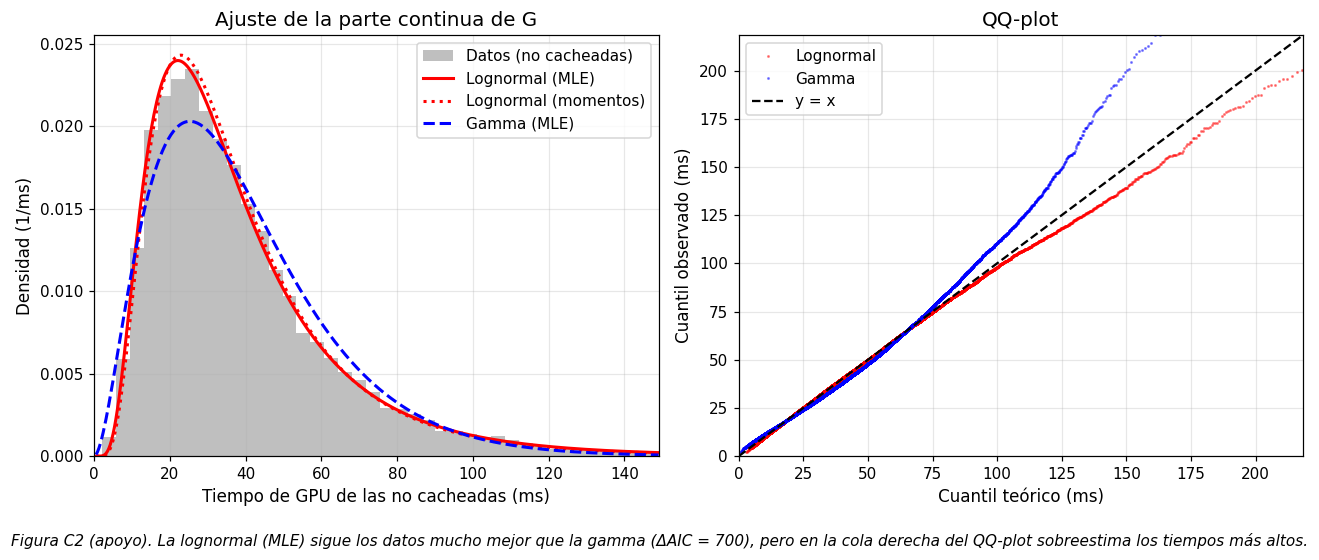

In [ ]:
# Gráfica de apoyo: densidades ajustadas y QQ-plot de la lognormal
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
xs = np.linspace(0.5, np.quantile(X_gpu, 0.995), 400)
ax[0].hist(X_gpu, bins=80, density=True, alpha=0.5, color="grey", label="Datos (no cacheadas)")
ax[0].plot(xs, stats.lognorm.pdf(xs, sig_mle, scale=np.exp(mu_mle)), "r-", lw=2, label="Lognormal (MLE)")
ax[0].plot(xs, stats.lognorm.pdf(xs, sig_mom, scale=np.exp(mu_mom)), "r:", lw=2, label="Lognormal (momentos)")
k_g, th_g = ajustes["Gamma"]["est"]
ax[0].plot(xs, stats.gamma.pdf(xs, k_g, scale=th_g), "b--", lw=2, label="Gamma (MLE)")
ax[0].set_xlim(0, xs.max())
ax[0].set_xlabel("Tiempo de GPU de las no cacheadas (ms)")
ax[0].set_ylabel("Densidad (1/ms)")
ax[0].set_title("Ajuste de la parte continua de G")
ax[0].legend()

prob_q = (np.arange(1, n_x2 + 1) - 0.5) / n_x2
for nombre, color in [("Lognormal", "red"), ("Gamma", "blue")]:
    dist, par = param_scipy[nombre](ajustes[nombre]["est"])
    ax[1].plot(dist.ppf(prob_q, *par), np.sort(X_gpu), ".", ms=2, color=color, alpha=0.4, label=nombre)
lim = np.quantile(X_gpu, 0.9995)
ax[1].plot([0, lim], [0, lim], "k--", label="y = x")
ax[1].set_xlim(0, lim); ax[1].set_ylim(0, lim)
ax[1].set_xlabel("Cuantil teórico (ms)")
ax[1].set_ylabel("Cuantil observado (ms)")
ax[1].set_title("QQ-plot")
ax[1].legend()
plt.tight_layout()
pie_de_figura(fig, "C2 (apoyo)",
              f"La lognormal (MLE) sigue los datos mucho mejor que la gamma (ΔAIC = {ajustes['Gamma']['AIC'] - ajustes['Lognormal']['AIC']:.0f}), "
              f"pero en la cola derecha del QQ-plot sobreestima los tiempos más altos.")
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_C2.png"), bbox_inches="tight")
plt.show()

**Paso 4. ¿Es adecuado el modelo marginal? Discusión con la estructura del sistema.** El tiempo de GPU no es una variable "pura": depende del **tamaño de la imagen** y de la **versión del modelo** (A3 mostró que B usa ≈ 6 % menos GPU). Entonces la distribución marginal de $X$ es una **mezcla** de distribuciones condicionales, una por cada tamaño y versión, y ningún modelo de dos parámetros tiene por qué describirla bien. Se cuantifica cuánto explica la estructura con una regresión de $\ln X$ sobre $\ln(\text{tam\_kb})$ y la versión (el modelo lineal formal es D3).

In [ ]:
# Paso 4. Estructura condicional: ln(G) en función de ln(tam_kb) y la versión
nc2 = df_estable[df_estable.cache_hit == 0]
Xd = np.column_stack([np.ones(n_x2), np.log(nc2.tam_kb.to_numpy()), (nc2.version == "B").to_numpy(dtype=float)])
beta_c2 = np.linalg.solve(Xd.T @ Xd, Xd.T @ lx)                 # mínimos cuadrados por ecuaciones normales
res_c2 = lx - Xd @ beta_c2
r2_c2 = 1 - res_c2.var() / lx.var()
print(f"Correlación entre tam_kb y gpu_ms: {np.corrcoef(nc2.tam_kb, X_gpu)[0, 1]:.3f}")
print(f"ln(G) = {beta_c2[0]:.3f} + {beta_c2[1]:.3f}·ln(tam_kb) {beta_c2[2]:+.3f}·[versión B] | R² = {r2_c2:.3f}")
print(f"  -> elasticidad: si el tamaño se duplica, G se multiplica por {2 ** beta_c2[1]:.2f}; la versión B multiplica G por {np.exp(beta_c2[2]):.3f}")
print(f"Residuos de ln(G): asimetría = {stats.skew(res_c2):.2f}, curtosis en exceso = {stats.kurtosis(res_c2):.2f} "
      f"(si G | tamaño fuera lognormal, ambos serían ≈ 0)")
cola = pd.DataFrame({"datos": np.quantile(X_gpu, [0.99, 0.999]),
                     "lognormal MLE": stats.lognorm.ppf([0.99, 0.999], sig_mle, scale=np.exp(mu_mle))},
                    index=["percentil 99", "percentil 99,9"])
print("\nCola derecha (ms):"); print(cola.round(1).to_string())

Correlación entre tam_kb y gpu_ms: 0.670
ln(G) = 0.705 + 0.527·ln(tam_kb) -0.060·[versión B] | R² = 0.405
  -> elasticidad: si el tamaño se duplica, G se multiplica por 1.44; la versión B multiplica G por 0.942
Residuos de ln(G): asimetría = -0.40, curtosis en exceso = 0.45 (si G | tamaño fuera lognormal, ambos serían ≈ 0)

Cola derecha (ms):
                datos  lognormal MLE
percentil 99    128.7          137.9
percentil 99,9  201.9          221.6


**Conclusión C2.** Entre los modelos ajustados por máxima verosimilitud propia, la **lognormal** es claramente mejor que la gamma: AIC 700 puntos menor, estadístico KS cuatro veces menor y QQ-plot casi sobre la diagonal. El método de momentos da estimaciones parecidas pero con menor verosimilitud, como se espera, porque el MLE es el que la maximiza. Aun así, **ambos modelos se rechazan formalmente** al nivel del grupo: con casi 19 000 datos las pruebas detectan desviaciones pequeñas, y la lognormal **sobreestima la cola extrema** (percentil 99,9: 222 ms contra 202 ms observados). La razón de fondo está en la estructura del sistema: el tiempo de GPU depende del tamaño de la imagen (correlación ≈ 0,67) y de la versión, que juntos explican ≈ 40 % de la variabilidad de $\ln G$. La marginal es entonces una **mezcla** de distribuciones condicionales, y ningún modelo de dos parámetros la describe exactamente. Para describir $G$ en conjunto la lognormal es una buena aproximación; para predecir el tiempo de una solicitud concreta, o para simular en la Parte G, conviene un modelo **condicional al tamaño** (D2–D3) o remuestrear los tiempos observados.

### C3. ¿red_ms admite un modelo normal?

**Qué se evalúa.** El tiempo de red `red_ms` de **todas** las solicitudes del régimen estable (la red se recorre igual haya o no caché). El modelo candidato es una **Normal**$(\mu, \sigma^2)$, sugerido por A3 (asimetría y curtosis ≈ 0). Antes de probarlo se comprueba que `red_ms` es **una sola población**: si dependiera de la caché, la versión o el tamaño, la marginal sería una mezcla (como pasó con $G$ en C2) y no tendría por qué ser normal.

**Advertencia física.** Un tiempo es positivo y la normal da probabilidad a valores negativos; se calcula cuánta, para ver si el problema importa en la práctica.

Los estimadores de máxima verosimilitud son $\hat\mu = \bar x$ y $\hat\sigma^2 = \frac1n\sum(x_i-\bar x)^2$; se usa $s$ (divisor $n-1$), que con $n \approx 28\,000$ es prácticamente igual.

In [ ]:
# Paso 1. Datos de red_ms, estimación de la normal y comprobación de que es una sola población
red = df_estable.red_ms.to_numpy()                              # tiempo de red (ms), todas las solicitudes del régimen estable
n_red = len(red)
mu_red, sd_red = red.mean(), red.std(ddof=1)                    # estimaciones de mu y sigma
z_c3 = stats.norm.ppf(1 - alpha / 2)

# IC exactos bajo normalidad: t de Student para mu, chi^2 para sigma
t_c3 = stats.t.ppf(1 - alpha / 2, n_red - 1)
sd_li = sd_red * np.sqrt((n_red - 1) / stats.chi2.ppf(1 - alpha / 2, n_red - 1))
sd_ls = sd_red * np.sqrt((n_red - 1) / stats.chi2.ppf(alpha / 2, n_red - 1))
print(f"n = {n_red} | mín = {red.min():.2f} ms, máx = {red.max():.2f} ms")
print("mu    (ms):", formatear_intervalo(mu_red, mu_red - t_c3 * sd_red / np.sqrt(n_red), mu_red + t_c3 * sd_red / np.sqrt(n_red), "t de Student", 3))
print("sigma (ms):", formatear_intervalo(sd_red, sd_li, sd_ls, "chi^2", 3))

# ¿Una sola población? (si no, la marginal sería una mezcla)
es_B = (df_estable.version == "B").to_numpy()
p_red_cache = stats.ttest_ind(red[cache], red[~cache], equal_var=False).pvalue     # `cache` viene de C1
p_red_ver = stats.ttest_ind(red[es_B], red[~es_B], equal_var=False).pvalue
r_red_tam = np.corrcoef(red, df_estable.tam_kb)[0, 1]
p_red_tam = 2 * stats.norm.sf(abs(r_red_tam) * np.sqrt(n_red))  # bajo correlación 0, r*sqrt(n) ~ N(0, 1)
r_red_gpu = np.corrcoef(red[~cache], G_cont)[0, 1]
print(f"\nMedia con caché {red[cache].mean():.3f} vs sin caché {red[~cache].mean():.3f} ms (Welch p = {p_red_cache:.3f})")
print(f"Media versión A {red[~es_B].mean():.3f} vs versión B {red[es_B].mean():.3f} ms (Welch p = {p_red_ver:.3f})")
print(f"Correlación con tam_kb = {r_red_tam:.4f} (p = {p_red_tam:.3f}) | con gpu_ms de las no cacheadas = {r_red_gpu:.4f}")

# Advertencia física: probabilidad de un tiempo de red negativo bajo el modelo
print(f"\nP(red < 0) bajo la normal = {stats.norm.cdf(0, mu_red, sd_red):.1e} "
      f"(el 0 está a {mu_red / sd_red:.1f} desviaciones estándar de la media): el problema del soporte es despreciable")

n = 28162 | mín = 7.32 ms, máx = 40.09 ms
mu    (ms): 25.602  [25.564, 25.640]  (IC 90%, método: t de Student)
sigma (ms): 3.871  [3.845, 3.898]  (IC 90%, método: chi^2)

Media con caché 25.575 vs sin caché 25.615 ms (Welch p = 0.416)
Media versión A 25.593 vs versión B 25.611 ms (Welch p = 0.689)
Correlación con tam_kb = 0.0037 (p = 0.537) | con gpu_ms de las no cacheadas = 0.0042

P(red < 0) bajo la normal = 1.9e-11 (el 0 está a 6.6 desviaciones estándar de la media): el problema del soporte es despreciable


**Paso 2. ¿Es normal? Cuatro criterios cuantitativos.**
1. **Forma (D'Agostino-Pearson):** combina la asimetría y la curtosis muestrales, que bajo normalidad son ≈ 0 con errores estándar $\approx\sqrt{6/n}$ y $\sqrt{24/n}$.
2. **Kolmogórov-Smirnov (Lilliefors)** y **Anderson-Darling**, este último más sensible a las colas. Como $\mu$ y $\sigma$ se estiman con los mismos datos, los valores p se calculan por **bootstrap paramétrico** (igual que en B1 y C2). El estadístico de Anderson-Darling se programa directamente, $A^2 = -n - \frac1n\sum_{i=1}^n (2i-1)\left[\ln F(x_{(i)}) + \ln\big(1 - F(x_{(n+1-i)})\big)\right]$.
3. **χ² de bondad de ajuste** con 30 clases equiprobables bajo el modelo (gl = 30 − 1 − 2). Como `red_ms` está redondeado a 0,01 ms (A1), los bordes de clase se colocan en los puntos medios de esa rejilla; si no, los valores que caen exactamente en un borde quedan todos de un lado y el χ² se infla de forma artificial. Se muestran las dos versiones y su sensibilidad al número de clases.
4. **Colas:** número de observaciones más allá de $\hat\mu \pm k\hat\sigma$ frente al número que predice la normal. Las preguntas que siguen (P(red > x) altas y percentil 99,9 %) dependen justamente de la cola.

No se usa Shapiro-Wilk porque scipy advierte que su valor p no es fiable con más de 5000 datos.

In [ ]:
# Paso 2. Pruebas de normalidad de red_ms
def estadistico_AD(x, cdf):
    # Anderson-Darling A^2 de la muestra x contra la función de distribución cdf
    n_ = len(x)
    F = np.clip(cdf(np.sort(x)), 1e-300, 1 - 1e-16)             # se evita log(0)
    i = np.arange(1, n_ + 1)
    return -n_ - np.mean((2 * i - 1) * (np.log(F) + np.log(1 - F[::-1])))

# 1. Forma
asim_red, curt_red = stats.skew(red), stats.kurtosis(red)
p_dag = stats.normaltest(red).pvalue
print(f"Asimetría = {asim_red:.4f} (ee ≈ {np.sqrt(6 / n_red):.4f}) | curtosis en exceso = {curt_red:.4f} (ee ≈ {np.sqrt(24 / n_red):.4f})")
print(f"1. D'Agostino-Pearson: p = {p_dag:.3f}")

# 2. KS y Anderson-Darling con valor p por bootstrap paramétrico (se re-estiman mu y sigma en cada réplica)
normal_ajustada = stats.norm(mu_red, sd_red)
KS_red = stats.kstest(red, normal_ajustada.cdf).statistic
AD_red = estadistico_AD(red, normal_ajustada.cdf)
B_C3 = 1000
KS_boot, AD_boot = np.empty(B_C3), np.empty(B_C3)
for b in range(B_C3):
    xb = rng.normal(mu_red, sd_red, n_red)                      # muestra simulada bajo H0
    nb_ = stats.norm(xb.mean(), xb.std(ddof=1))                 # normal re-estimada con esa muestra
    KS_boot[b] = stats.kstest(xb, nb_.cdf).statistic
    AD_boot[b] = estadistico_AD(xb, nb_.cdf)
p_KS_red = (1 + (KS_boot >= KS_red).sum()) / (B_C3 + 1)
p_AD_red = (1 + (AD_boot >= AD_red).sum()) / (B_C3 + 1)
print(f"2. KS (Lilliefors): D = {KS_red:.4f}, p bootstrap = {p_KS_red:.3f} | Anderson-Darling: A² = {AD_red:.3f}, p bootstrap = {p_AD_red:.3f}")

# 3. Chi^2 con clases equiprobables. red_ms está redondeado a RESOLUCION_MS (A1): con clases estrechas, los valores
#    que caen justo en un borde se asignan de un solo lado y el chi^2 se infla. Corrección: mover cada borde al punto
#    medio de la rejilla de redondeo más cercano y calcular las esperadas con esos bordes.
def chi2_normal(x, K, corregir_redondeo):
    # Chi^2 de x contra la normal ajustada con K clases (aprox.) equiprobables; devuelve (X2, gl, p)
    bordes = normal_ajustada.ppf(np.linspace(0, 1, K + 1))      # extremos -inf y +inf incluidos
    if corregir_redondeo:
        bordes[1:-1] = np.round(bordes[1:-1], DEC_TIEMPOS) + RESOLUCION_MS / 2
    obs = np.histogram(x, bins=bordes)[0]
    esp = len(x) * np.diff(normal_ajustada.cdf(bordes))
    X2 = ((obs - esp) ** 2 / esp).sum()
    return X2, K - 3, stats.chi2.sf(X2, K - 3)                  # gl = clases - 1 - 2 parámetros estimados

K_C3 = 30
X2_raw, gl_X2, p_X2_raw = chi2_normal(red, K_C3, False)
X2_red, _, p_X2_red = chi2_normal(red, K_C3, True)
print(f"3. Chi^2 ({K_C3} clases, gl = {gl_X2}): bordes ingenuos X2 = {X2_raw:.1f}, p = {p_X2_raw:.3f} | "
      f"bordes en puntos medios de la rejilla de {RESOLUCION_MS} ms X2 = {X2_red:.1f}, p = {p_X2_red:.3f}")
sens_chi2 = pd.DataFrame({K: {"p bordes ingenuos": chi2_normal(red, K, False)[2], "p bordes corregidos": chi2_normal(red, K, True)[2]}
                          for K in [10, 20, 30, 40, 50, 60]}).T
sens_chi2.index.name = "clases"
print("   Sensibilidad al número de clases:"); print(sens_chi2.round(3).T.to_string())

# 4. Colas: observado vs esperado más allá de mu ± k sigma
z_red = (red - mu_red) / sd_red
colas = pd.DataFrame({f"|z| > {k}": {"observadas": int((np.abs(z_red) > k).sum()),
                                      "esperadas (normal)": n_red * 2 * stats.norm.sf(k),
                                      "inferior / superior": f"{int((z_red < -k).sum())} / {int((z_red > k).sum())}"}
                      for k in [2, 3, 3.5, 4]}).T
print("4. Colas:"); print(colas.to_string())
print(f"   Observación más extrema: mín = {red.min():.2f} ms (z = {z_red.min():.2f}), máx = {red.max():.2f} ms (z = {z_red.max():.2f}); "
      f"con n = {n_red}, el máximo |z| esperado bajo normalidad ronda {stats.norm.ppf(1 - 0.5 / (2 * n_red)):.2f}")

pruebas_red = {"D'Agostino-Pearson": p_dag, "KS (Lilliefors)": p_KS_red, "Anderson-Darling": p_AD_red, "Chi^2": p_X2_red}
print(f"\nNivel alpha = {alpha}: " + ", ".join(f"{k} {'rechaza' if v < alpha else 'no rechaza'}" for k, v in pruebas_red.items()))

Asimetría = -0.0135 (ee ≈ 0.0146) | curtosis en exceso = -0.0065 (ee ≈ 0.0292)
1. D'Agostino-Pearson: p = 0.638
2. KS (Lilliefors): D = 0.0043, p bootstrap = 0.256 | Anderson-Darling: A² = 0.386, p bootstrap = 0.391
3. Chi^2 (30 clases, gl = 27): bordes ingenuos X2 = 39.7, p = 0.054 | bordes en puntos medios de la rejilla de 0.01 ms X2 = 29.0, p = 0.362
   Sensibilidad al número de clases:
clases                  10     20     30     40    50     60
p bordes ingenuos    0.101  0.136  0.054  0.002  0.04  0.004
p bordes corregidos  0.200  0.703  0.362  0.273  0.41  0.373
4. Colas:
          observadas esperadas (normal) inferior / superior
|z| > 2         1253        1281.378432           650 / 603
|z| > 3           74          76.031657             40 / 34
|z| > 3.5         11            13.1026               6 / 5
|z| > 4            2           1.783851               2 / 0
   Observación más extrema: mín = 7.32 ms (z = -4.72), máx = 40.09 ms (z = 3.74); con n = 28162, el máximo |z| esp

**Paso 3. $P(\text{red} > x)$ para tres valores de $x$.** Se eligen para cubrir el cuerpo, la cola y la cola extrema:
$x = 30$ ms (≈ $\hat\mu + 1{,}1\hat\sigma$), $x = 35$ ms (≈ $\hat\mu + 2{,}4\hat\sigma$) y $x = 40$ ms (≈ $\hat\mu + 3{,}7\hat\sigma$, en el borde de lo observado, que es donde el modelo aporta más que la proporción empírica).

Con el modelo, $P(\text{red} > x) = 1 - \Phi(z)$, $z = (x-\mu)/\sigma$. Su intervalo se obtiene por el **método delta**: como $\partial P/\partial\mu = \varphi(z)/\sigma$, $\partial P/\partial\sigma = z\,\varphi(z)/\sigma$, $\text{Var}(\hat\mu) = \sigma^2/n$ y $\text{Var}(\hat\sigma) \approx \sigma^2/(2n)$ (independientes bajo normalidad),
$$\text{ee}\big(\hat P\big) \approx \varphi(\hat z)\sqrt{\frac{1 + \hat z^2/2}{n}}.$$
Se compara con la proporción empírica y su intervalo exacto de Clopper-Pearson, que no supone normalidad.

In [ ]:
# Paso 3. P(red > x): modelo normal (IC por método delta) frente a proporción empírica (Clopper-Pearson)
X_RED = [30.0, 35.0, 40.0]                                      # valores de x elegidos (ms)


def cola_normal(x, mu_, sd_, n_):
    # P(red > x) bajo la normal y su error estándar por el método delta
    z_ = (x - mu_) / sd_
    return stats.norm.sf(z_), stats.norm.pdf(z_) * np.sqrt((1 + z_**2 / 2) / n_), z_


filas_c3 = []
for x in X_RED:
    P_mod, ee_mod, zx = cola_normal(x, mu_red, sd_red, n_red)
    k_x = int((red > x).sum())                                  # observaciones por encima de x
    cp_li = stats.beta.ppf(alpha / 2, k_x, n_red - k_x + 1) if k_x > 0 else 0.0
    cp_ls = stats.beta.ppf(1 - alpha / 2, k_x + 1, n_red - k_x)
    filas_c3.append({"x (ms)": x, "z": zx,
                     "P normal": P_mod, "IC normal (delta)": f"[{P_mod - z_c3 * ee_mod:.2e}, {P_mod + z_c3 * ee_mod:.2e}]",
                     "ancho relativo normal": 2 * z_c3 * ee_mod / P_mod,
                     "observadas": k_x, "P empírica": k_x / n_red, "IC empírico (Clopper-Pearson)": f"[{cp_li:.2e}, {cp_ls:.2e}]",
                     "ancho relativo empírico": (cp_ls - cp_li) / max(k_x / n_red, 1 / n_red)})
tabla_c3 = pd.DataFrame(filas_c3).set_index("x (ms)")
print(f"Nivel {nivel_confianza:.0%}, n = {n_red}")
print(tabla_c3.to_string(float_format=lambda v: f"{v:.4g}"))
for x in X_RED:
    P_mod, ee_mod, _ = cola_normal(x, mu_red, sd_red, n_red)
    dec_x = max(4, int(np.ceil(-np.log10(P_mod))) + 2)          # decimales suficientes para ver probabilidades pequeñas
    print(f"P(red > {x:.0f} ms):", formatear_intervalo(P_mod, P_mod - z_c3 * ee_mod, P_mod + z_c3 * ee_mod, "normal + método delta", dec_x))

Nivel 90%, n = 28162
           z  P normal     IC normal (delta)  ancho relativo normal  observadas  P empírica IC empírico (Clopper-Pearson)  ancho relativo empírico
x (ms)                                                                                                                                            
30.0   1.136     0.128  [1.25e-01, 1.31e-01]                0.04112        3620      0.1285          [1.25e-01, 1.32e-01]                  0.05132
35.0   2.428  0.007599  [7.19e-03, 8.01e-03]                 0.1074         216     0.00767          [6.83e-03, 8.58e-03]                   0.2277
40.0   3.719 9.995e-05  [8.90e-05, 1.11e-04]                 0.2183           1   3.551e-05          [1.82e-06, 1.68e-04]                    4.692
P(red > 30 ms): 0.1280  [0.1253, 0.1306]  (IC 90%, método: normal + método delta)
P(red > 35 ms): 0.00760  [0.00719, 0.00801]  (IC 90%, método: normal + método delta)
P(red > 40 ms): 0.0000999  [0.0000890, 0.0001109]  (IC 90%, método: normal + 

**Paso 4. Percentil 99,9 % con intervalo de confianza.** Bajo el modelo, $q_{0{,}999} = \mu + z_{0{,}999}\,\sigma$ con $z_{0{,}999} = \Phi^{-1}(0{,}999) \approx 3{,}09$. Se comparan tres intervalos:
1. **Método delta:** $\text{ee}(\hat q) \approx \sigma\sqrt{\frac{1}{n} + \frac{z_{0,999}^2}{2n}}$.
2. **Exacto bajo normalidad (t no central):** $T = \sqrt n\,(\bar x - q)/s \sim t'_{n-1}\big(-z_{0,999}\sqrt n\big)$, porque $\sqrt n(\bar x - \mu)/\sigma \sim N(0,1)$ es independiente de $s/\sigma$. Despejando, $q \in \big[\bar x - t'_{1-\alpha/2}\,s/\sqrt n,\; \bar x - t'_{\alpha/2}\,s/\sqrt n\big]$.
3. **Bootstrap no paramétrico del percentil empírico**, que no supone normalidad y sirve de contraste: si el modelo es bueno, ambos deben ser compatibles.

In [ ]:
# Paso 4. Percentil 99,9 % de red_ms con tres intervalos
P_Q = 0.999
z_q = stats.norm.ppf(P_Q)
q_red = mu_red + z_q * sd_red                                   # percentil del modelo normal

# 1. Método delta
ee_q_red = sd_red * np.sqrt(1 / n_red + z_q**2 / (2 * n_red))
# 2. Exacto con la t no central
t_nc = stats.nct.ppf([alpha / 2, 1 - alpha / 2], n_red - 1, -z_q * np.sqrt(n_red))
q_nct_li, q_nct_ls = mu_red - t_nc[1] * sd_red / np.sqrt(n_red), mu_red - t_nc[0] * sd_red / np.sqrt(n_red)
# 3. Bootstrap no paramétrico del percentil empírico
q_emp = np.quantile(red, P_Q)
B_Q = 2000
q_boot = np.array([np.quantile(red[rng.integers(0, n_red, n_red)], P_Q) for _ in range(B_Q)])
q_bt_li, q_bt_ls = np.quantile(q_boot, [alpha / 2, 1 - alpha / 2])

print(f"Observaciones por encima del percentil 99,9 % empírico: {int((red > q_emp).sum())} (por eso el empírico es más incierto)")
print("Percentil 99,9 % normal:   ", formatear_intervalo(q_red, q_red - z_c3 * ee_q_red, q_red + z_c3 * ee_q_red, "normal + método delta", 3))
print("Percentil 99,9 % normal:   ", formatear_intervalo(q_red, q_nct_li, q_nct_ls, "exacto, t no central", 3))
print("Percentil 99,9 % empírico: ", formatear_intervalo(q_emp, q_bt_li, q_bt_ls, f"bootstrap percentil, {B_Q} réplicas", 3))
print(f"Ancho: delta {2 * z_c3 * ee_q_red:.3f} ms | t no central {q_nct_ls - q_nct_li:.3f} ms | bootstrap empírico {q_bt_ls - q_bt_li:.3f} ms")

Observaciones por encima del percentil 99,9 % empírico: 29 (por eso el empírico es más incierto)
Percentil 99,9 % normal:    37.565  [37.474, 37.656]  (IC 90%, método: normal + método delta)
Percentil 99,9 % normal:    37.565  [37.475, 37.657]  (IC 90%, método: exacto, t no central)
Percentil 99,9 % empírico:  37.453  [37.105, 37.873]  (IC 90%, método: bootstrap percentil, 2000 réplicas)
Ancho: delta 0.182 ms | t no central 0.182 ms | bootstrap empírico 0.767 ms


**Paso 5. Verificación por simulación de los intervalos analíticos.** Se generan muchas muestras normales del mismo tamaño con $\mu = \hat\mu$ y $\sigma = \hat\sigma$ y se mide con qué frecuencia cada intervalo contiene el valor verdadero (cobertura efectiva frente al nivel nominal). Como los intervalos solo dependen de $\bar x$ y $s$, se simulan directamente sus distribuciones exactas: $\bar x \sim N(\mu, \sigma^2/n)$ y $(n-1)s^2/\sigma^2 \sim \chi^2_{n-1}$, independientes. Esto permite muchas réplicas sin generar 28 000 datos en cada una.

In [ ]:
# Paso 5. Cobertura por Montecarlo de los intervalos de P(red > x) (delta) y del percentil 99,9 % (delta y t no central)
R_C3 = 20_000
xbar_s = rng.normal(mu_red, sd_red / np.sqrt(n_red), R_C3)                         # distribución exacta de la media
sd_s = sd_red * np.sqrt(rng.chisquare(n_red - 1, R_C3) / (n_red - 1))             # distribución exacta de s

cob = {}
for x in X_RED:                                                 # P(red > x): método delta
    P_true = stats.norm.sf((x - mu_red) / sd_red)
    P_s, ee_s, _ = cola_normal(x, xbar_s, sd_s, n_red)
    cob[f"P(red > {x:.0f}), delta"] = np.mean(np.abs(P_s - P_true) <= z_c3 * ee_s)
q_true = mu_red + z_q * sd_red                                  # percentil 99,9 %
q_s = xbar_s + z_q * sd_s
ee_qs = sd_s * np.sqrt(1 / n_red + z_q**2 / (2 * n_red))
cob["percentil 99,9 %, delta"] = np.mean(np.abs(q_s - q_true) <= z_c3 * ee_qs)
cob["percentil 99,9 %, t no central"] = np.mean((xbar_s - t_nc[1] * sd_s / np.sqrt(n_red) <= q_true) &
                                                (q_true <= xbar_s - t_nc[0] * sd_s / np.sqrt(n_red)))
ee_mc_c3 = np.sqrt(nivel_confianza * (1 - nivel_confianza) / R_C3)
print(f"Cobertura efectiva ({R_C3} réplicas, nominal {nivel_confianza:.0%}, error de Montecarlo ≈ ±{z_c3 * ee_mc_c3:.3f}):")
for k, v in cob.items():
    print(f"  {k:32s} {v:.4f}")

Cobertura efectiva (20000 réplicas, nominal 90%, error de Montecarlo ≈ ±0.003):
  P(red > 30), delta               0.8970
  P(red > 35), delta               0.8983
  P(red > 40), delta               0.9002
  percentil 99,9 %, delta          0.8994
  percentil 99,9 %, t no central   0.8985


### Figura 3
Izquierda: histograma de `red_ms` con la densidad normal ajustada. Centro: QQ-plot normal. Derecha: función de supervivencia $P(\text{red} > x)$ en escala logarítmica, empírica frente a la normal, con los tres valores de $x$ y el percentil 99,9 %. El panel derecho es el que importa para las preguntas de cola.

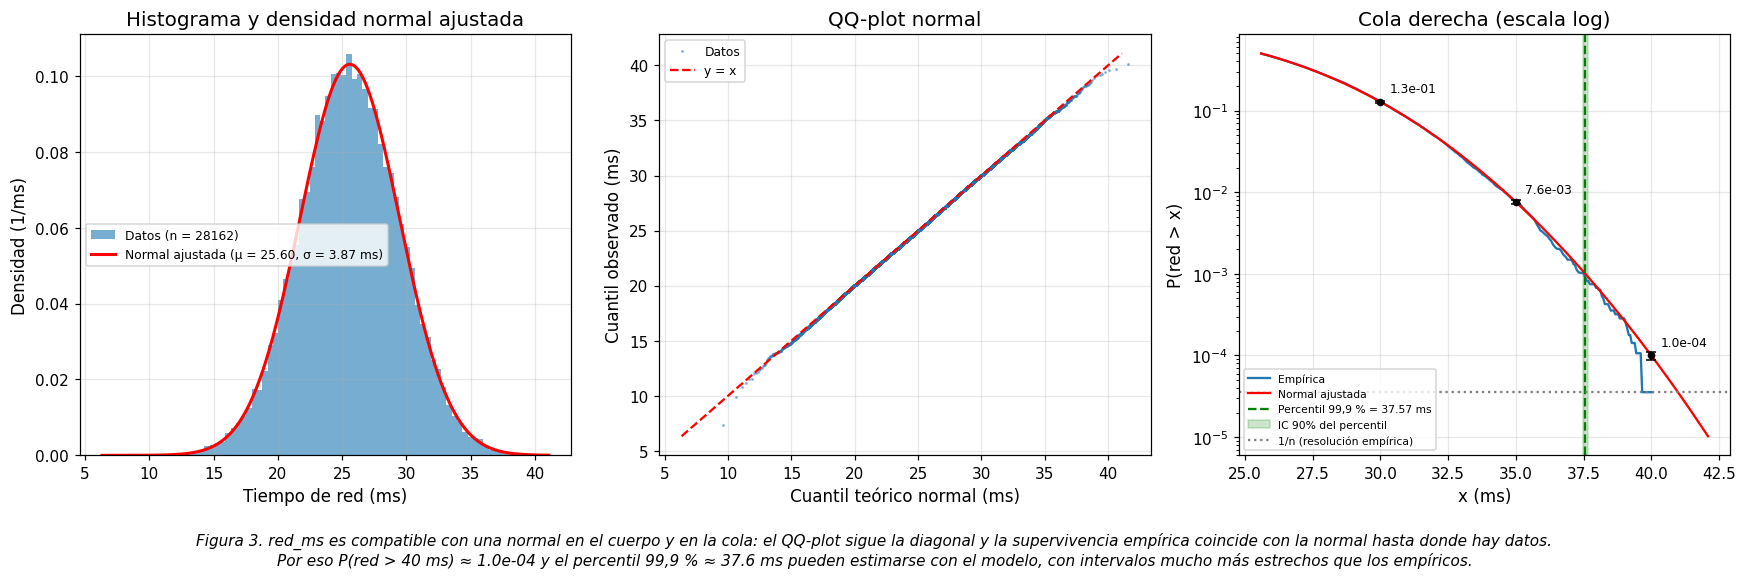

In [ ]:
# Figura 3. ¿red_ms es normal? Cuerpo, cuantiles y cola
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))

xs_red = np.linspace(red.min() - 1, red.max() + 1, 400)
ax[0].hist(red, bins=80, density=True, color="tab:blue", alpha=0.6, label=f"Datos (n = {n_red})")
ax[0].plot(xs_red, normal_ajustada.pdf(xs_red), "r-", lw=2, label=f"Normal ajustada (μ = {mu_red:.2f}, σ = {sd_red:.2f} ms)")
ax[0].set_xlabel("Tiempo de red (ms)")
ax[0].set_ylabel("Densidad (1/ms)")
ax[0].set_title("Histograma y densidad normal ajustada")
ax[0].legend(fontsize=8)

prob_red = (np.arange(1, n_red + 1) - 0.5) / n_red
ax[1].plot(normal_ajustada.ppf(prob_red), np.sort(red), ".", ms=2, alpha=0.4, label="Datos")
ax[1].plot(xs_red, xs_red, "r--", label="y = x")
ax[1].set_xlabel("Cuantil teórico normal (ms)")
ax[1].set_ylabel("Cuantil observado (ms)")
ax[1].set_title("QQ-plot normal")
ax[1].legend(fontsize=8)

xs_cola = np.linspace(mu_red, red.max() + 2, 300)
sup_emp = np.array([(red > v).mean() for v in xs_cola])
ax[2].semilogy(xs_cola, np.where(sup_emp > 0, sup_emp, np.nan), color="tab:blue", label="Empírica")
ax[2].semilogy(xs_cola, normal_ajustada.sf(xs_cola), "r-", lw=1.5, label="Normal ajustada")
for x in X_RED:
    P_mod, ee_mod, _ = cola_normal(x, mu_red, sd_red, n_red)
    ax[2].errorbar(x, P_mod, yerr=z_c3 * ee_mod, fmt="ko", ms=4, capsize=3)
    ax[2].annotate(f"{P_mod:.1e}", (x, P_mod), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax[2].axvline(q_red, color="green", linestyle="--", label=f"Percentil 99,9 % = {q_red:.2f} ms")
ax[2].axvspan(q_nct_li, q_nct_ls, color="green", alpha=0.2, label=f"IC {nivel_confianza:.0%} del percentil")
ax[2].axhline(1 / n_red, color="grey", linestyle=":", label="1/n (resolución empírica)")
ax[2].set_xlabel("x (ms)")
ax[2].set_ylabel("P(red > x)")
ax[2].set_title("Cola derecha (escala log)")
ax[2].legend(fontsize=7, loc="lower left")

pie_de_figura(fig, 3, f"red_ms es compatible con una normal en el cuerpo y en la cola: el QQ-plot sigue la diagonal y la supervivencia empírica "
                      f"coincide con la normal hasta donde hay datos.\nPor eso P(red > 40 ms) ≈ {stats.norm.sf((40 - mu_red) / sd_red):.1e} y el percentil 99,9 % "
                      f"≈ {q_red:.1f} ms pueden estimarse con el modelo, con intervalos mucho más estrechos que los empíricos.")
plt.tight_layout()
guardar_figura(fig, 3)
plt.show()

**Conclusión C3.** `red_ms` admite un modelo **normal**, $N(\hat\mu = 25{,}60;\ \hat\sigma = 3{,}87)$ ms (IC 90 %: μ ∈ [25,56; 25,64], σ ∈ [3,85; 3,90]).
- **Una sola población:** no depende de la caché (p = 0,42), de la versión (p = 0,69) ni del tamaño (r = 0,004). A diferencia de $G$, no es una mezcla.
- **Normalidad, cuatro criterios, ninguno rechaza al 10 %:** asimetría −0,01 y curtosis −0,01, ambas dentro de su error estándar (D'Agostino-Pearson p = 0,64); KS-Lilliefors p = 0,26 y Anderson-Darling p = 0,39, con valores p por bootstrap paramétrico; χ² p = 0,36. Las colas coinciden con lo esperado: 74 observaciones con |z| > 3 frente a 76 esperadas, y 11 con |z| > 3,5 frente a 13.
- **Observación sobre el χ²:** con bordes de clase ingenuos rechaza para algunos números de clases (p = 0,002 a 0,14). Es un **artefacto del redondeo a 0,01 ms**: al poner los bordes en los puntos medios de la rejilla, ningún número de clases rechaza (p entre 0,20 y 0,70). No es una falla del modelo.
- **Soporte:** P(red < 0) = 2·10⁻¹¹ bajo el modelo, así que dar probabilidad a tiempos negativos no tiene consecuencias prácticas.
- **Probabilidades de cola** (normal, IC 90 % por método delta): P(red > 30) = 0,128 [0,125; 0,131]; P(red > 35) = 0,0076 [0,0072; 0,0080]; P(red > 40) = 1,0·10⁻⁴ [0,89; 1,11]·10⁻⁴. En la cola el modelo es mucho más informativo que los datos. Para x = 40 solo hay 1 observación, y el intervalo empírico va de 2·10⁻⁶ a 1,7·10⁻⁴, unas 20 veces más ancho.
- **Percentil 99,9 %:** 37,57 ms, IC 90 % [37,47; 37,66] (exacto con t no central; el método delta da lo mismo). El percentil empírico, 37,45 ms [37,11; 37,87], es compatible y su intervalo es 4 veces más ancho, porque solo 29 datos superan ese valor.
- **Verificación por simulación:** los intervalos analíticos tienen cobertura efectiva entre 0,897 y 0,900 frente al 0,90 nominal.
- **Implicación para el SLO:** la red casi nunca supera ~38 ms. Con τ = 210 ms, la red sola no viola el umbral: las violaciones vienen de la espera en cola y de la GPU, que es lo que la Parte G debe modelar con cuidado. Para el simulador basta con red ~ N(25,60; 3,87²), independiente del resto.

### C4. Tiempo total de GPU de N solicitudes no cacheadas

**Qué se pide.** Sea $X_1, \dots, X_N$ el tiempo de GPU de $N$ solicitudes consecutivas **no cacheadas** (la parte continua de $G$, estudiada en C1–C2) y $T_N = X_1 + \dots + X_N$ el tiempo total de GPU que consumen. Con $N = 14$ (parámetro del grupo) y $\hat m$ la media muestral de `gpu_ms` de las no cacheadas, se busca
$$P\big(T_N > N(\hat m + 15)\big),$$
es decir, la probabilidad de que esas $N$ solicitudes consuman en promedio **más de 15 ms por encima de lo normal**. El umbral se calcula una vez con los datos y después se trata como un número fijo.

**Supuestos.** Los $X_i$ son **independientes e idénticamente distribuidos**, con media $m$, varianza $v$, asimetría $\gamma$ y curtosis en exceso $\kappa$. Esto se comprueba en el paso 1: (i) la autocorrelación de `gpu_ms` en orden de llegada debe ser ≈ 0; (ii) A2 mostró que la distribución de la GPU no cambia con el régimen.

**Momentos exactos de la suma.** Por linealidad y por independencia:
$$E[T_N] = Nm, \qquad \text{Var}(T_N) = Nv, \qquad \gamma(T_N) = \frac{\gamma}{\sqrt N}, \qquad \kappa(T_N) = \frac{\kappa}{N}.$$
La media y la varianza crecen con $N$, mientras que la asimetría y la curtosis se diluyen solo como $1/\sqrt N$ y $1/N$. Con $N = 14$ y la fuerte asimetría de la GPU ($\gamma \approx 2$, C2), la suma sigue siendo **claramente asimétrica**. Esa es la clave de todo el ítem.

**Por qué no hay fórmula exacta.** La suma de lognormales no tiene distribución conocida en forma cerrada, y en todo caso C2 mostró que la lognormal tampoco es exacta para $X$. Por eso se comparan **cuatro aproximaciones analíticas** con una **simulación**.

In [ ]:
# Paso 1. Datos, umbral y comprobación de los supuestos (independencia e idéntica distribución)
# X_gpu viene de C2: gpu_ms de las solicitudes NO cacheadas del régimen estable (la parte continua de G)
m_c4 = X_gpu.mean()                                             # m̂: media muestral (es la misma que m_hat de C1)
v_c4 = X_gpu.var(ddof=1)                                        # v̂: varianza muestral
gam_c4 = stats.skew(X_gpu)                                      # γ̂: asimetría (0 en la normal)
kap_c4 = stats.kurtosis(X_gpu)                                  # κ̂: curtosis en exceso (0 en la normal)
umbral_c4 = N * (m_c4 + 15)                                     # umbral del enunciado: N(m̂ + 15) ms, fijo de aquí en adelante

print(f"N = {N} solicitudes | m̂ = {m_c4:.3f} ms | v̂ = {v_c4:.2f} ms² (desv. est. {np.sqrt(v_c4):.2f}) | "
      f"γ̂ = {gam_c4:.3f} | κ̂ = {kap_c4:.3f}")
print(f"Umbral: N(m̂ + 15) = {N} × {m_c4 + 15:.3f} = {umbral_c4:.2f} ms")
print(f"Momentos de T_N: E = N·m = {N * m_c4:.2f} ms | desv. est. = sqrt(N·v) = {np.sqrt(N * v_c4):.2f} ms | "
      f"asimetría = γ/sqrt(N) = {gam_c4 / np.sqrt(N):.3f} | curtosis = κ/N = {kap_c4 / N:.3f}")
print(f"El umbral está a z = {(umbral_c4 - N * m_c4) / np.sqrt(N * v_c4):.3f} desviaciones estándar de la media de T_N")

# Supuesto de independencia: GPU de solicitudes no cacheadas CONSECUTIVAS, en orden de llegada y dentro de cada tramo
# del régimen estable (no se une el final del primer tramo con el inicio del segundo, porque entre ellos está la ráfaga)
nc_c4 = df_estable[df_estable.cache_hit == 0].sort_values("t_llegada_s")
pares = [nc_c4.gpu_ms[(nc_c4.t_llegada_s >= a) & (nc_c4.t_llegada_s < b)].to_numpy() for a, b in tramos]
x_ant = np.concatenate([s[:-1] for s in pares]); x_sig = np.concatenate([s[1:] for s in pares])
rho_c4 = np.corrcoef(x_ant, x_sig)[0, 1]                        # autocorrelación de orden 1
print(f"\nAutocorrelación de orden 1 de gpu_ms en orden de llegada: {rho_c4:.4f} "
      f"(z = {rho_c4 * np.sqrt(len(x_ant)):.2f}, p = {2 * stats.norm.sf(abs(rho_c4) * np.sqrt(len(x_ant))):.3f}) "
      f"-> {'compatible' if 2 * stats.norm.sf(abs(rho_c4) * np.sqrt(len(x_ant))) >= alpha else 'NO compatible'} con independencia")

N = 14 solicitudes | m̂ = 39.229 ms | v̂ = 665.75 ms² (desv. est. 25.80) | γ̂ = 1.961 | κ̂ = 6.699
Umbral: N(m̂ + 15) = 14 × 54.229 = 759.20 ms
Momentos de T_N: E = N·m = 549.20 ms | desv. est. = sqrt(N·v) = 96.54 ms | asimetría = γ/sqrt(N) = 0.524 | curtosis = κ/N = 0.478
El umbral está a z = 2.175 desviaciones estándar de la media de T_N

Autocorrelación de orden 1 de gpu_ms en orden de llegada: -0.0004 (z = -0.06, p = 0.953) -> compatible con independencia


**Paso 2. Cuatro aproximaciones analíticas.** Todas usan solo los momentos estimados de $X$. Con $\mu_T = Nm$, $\sigma_T = \sqrt{Nv}$ y $z = (t - \mu_T)/\sigma_T$, donde $t$ es el umbral:

1. **Normal (teorema del límite central):** $T_N \approx N(\mu_T, \sigma_T^2)$, así que $P \approx 1 - \Phi(z)$. Solo iguala media y varianza, y **supone asimetría 0**.
2. **Expansión de Edgeworth (dos términos):** corrige la normal con la asimetría y la curtosis de la suma, $\gamma_N = \gamma/\sqrt N$ y $\kappa_N = \kappa/N$:
$$P \approx 1 - \Phi(z) + \varphi(z)\left[\frac{\gamma_N}{6}(z^2 - 1) + \frac{\kappa_N}{24}(z^3 - 3z) + \frac{\gamma_N^2}{72}(z^5 - 10z^3 + 15z)\right].$$
3. **Gamma por momentos:** si $X \sim \text{Gamma}(k, \theta)$ con $k = m^2/v$ y $\theta = v/m$, entonces la suma de $N$ gammas independientes con la misma escala es **exactamente** $\text{Gamma}(Nk, \theta)$. Iguala media y varianza, y su asimetría queda fija en $2/\sqrt{Nk}$.
4. **Lognormal de Fenton-Wilkinson:** aproxima $T_N$ por una lognormal con su misma media y varianza: $\sigma_L^2 = \ln\!\left(1 + \frac{Nv}{(Nm)^2}\right)$, $\mu_L = \ln(Nm) - \sigma_L^2/2$, y $P \approx 1 - \Phi\!\left(\frac{\ln t - \mu_L}{\sigma_L}\right)$. Su asimetría es $(e^{\sigma_L^2} + 2)\sqrt{e^{\sigma_L^2} - 1}$.

Las cuatro coinciden en media y varianza; **se diferencian en la asimetría que le asignan a $T_N$**. Como el umbral está en la cola derecha, esa diferencia es la que decide cuál acierta. Por eso se reporta también la asimetría implícita de cada una.

In [ ]:
# Paso 2. Las cuatro aproximaciones analíticas, como función de los momentos (así se pueden recalcular en el bootstrap)
def aproximaciones_c4(m, v, gam, kap, t=umbral_c4, n=N):
    # P(T_n > t) con cuatro aproximaciones; devuelve un diccionario {método: probabilidad}
    mu_T, sd_T = n * m, np.sqrt(n * v)                          # media y desviación estándar exactas de la suma
    z = (t - mu_T) / sd_T                                       # umbral estandarizado
    g_n, k_n = gam / np.sqrt(n), kap / n                        # asimetría y curtosis de la suma
    # 1. Normal: solo media y varianza
    p_norm = stats.norm.sf(z)
    # 2. Edgeworth: normal + corrección por asimetría (término en g_n) y por curtosis y asimetría² (segundo orden)
    p_edge = p_norm + stats.norm.pdf(z) * (g_n / 6 * (z**2 - 1) + k_n / 24 * (z**3 - 3 * z)
                                           + g_n**2 / 72 * (z**5 - 10 * z**3 + 15 * z))
    # 3. Gamma por momentos: X ~ Gamma(k, θ) => T_n ~ Gamma(n·k, θ) exactamente
    k_g, th_g = m**2 / v, v / m
    p_gam = stats.gamma.sf(t, n * k_g, scale=th_g)
    # 4. Lognormal de Fenton-Wilkinson: lognormal con la media y la varianza de T_n
    s2_L = np.log(1 + (n * v) / (n * m) ** 2)
    mu_L = np.log(n * m) - s2_L / 2
    p_fw = stats.norm.sf((np.log(t) - mu_L) / np.sqrt(s2_L))
    return {"Normal (TLC)": p_norm, "Edgeworth (2 términos)": p_edge,
            "Gamma por momentos": p_gam, "Lognormal Fenton-Wilkinson": p_fw}


p_aprox = aproximaciones_c4(m_c4, v_c4, gam_c4, kap_c4)

# Asimetría que cada aproximación le asigna a T_N, frente a la verdadera γ/sqrt(N) (estimada con los datos)
s2_L = np.log(1 + v_c4 / (N * m_c4**2))
asim_implicita = {"Normal (TLC)": 0.0,
                  "Edgeworth (2 términos)": gam_c4 / np.sqrt(N),        # la usa explícitamente
                  "Gamma por momentos": 2 / np.sqrt(N * m_c4**2 / v_c4),
                  "Lognormal Fenton-Wilkinson": (np.exp(s2_L) + 2) * np.sqrt(np.exp(s2_L) - 1)}
print(f"Asimetría de T_N estimada con los datos: γ̂/sqrt(N) = {gam_c4 / np.sqrt(N):.3f}\n")
for k_, p_ in p_aprox.items():
    print(f"{k_:28s} P(T_N > {umbral_c4:.1f}) = {p_:.5f} | asimetría que asume para T_N = {asim_implicita[k_]:.3f}")

Asimetría de T_N estimada con los datos: γ̂/sqrt(N) = 0.524

Normal (TLC)                 P(T_N > 759.2) = 0.01481 | asimetría que asume para T_N = 0.000
Edgeworth (2 términos)       P(T_N > 759.2) = 0.02674 | asimetría que asume para T_N = 0.524
Gamma por momentos           P(T_N > 759.2) = 0.02254 | asimetría que asume para T_N = 0.352
Lognormal Fenton-Wilkinson   P(T_N > 759.2) = 0.02599 | asimetría que asume para T_N = 0.533


**Paso 3. Simulación de Montecarlo (referencia).** Se simulan $R = 10^6$ grupos de $N$ solicitudes y se cuenta la fracción en que $T_N$ supera el umbral. Se usan dos formas de generar los $X_i$:
- **Bootstrap (remuestreo de los tiempos observados):** no supone ninguna forma paramétrica, solo independencia. Es la **referencia principal**, porque C2 mostró que ningún modelo de dos parámetros describe exactamente a $X$.
- **Lognormal ajustada por MLE en C2:** muestra cuánto importa el error del modelo marginal en la cola.

Además se hace un **contraste con los datos reales**: se parten las solicitudes no cacheadas, en orden de llegada y dentro de cada tramo, en bloques de $N$ consecutivas, y se cuenta qué fracción de bloques supera el umbral. Esto también pone a prueba el supuesto de independencia, aunque con pocos bloques.

In [ ]:
# Paso 3. Montecarlo: R grupos de N solicitudes no cacheadas
R_C4 = 1_000_000
z_c4 = stats.norm.ppf(1 - alpha / 2)

# (a) Bootstrap: cada X_i se toma al azar (con reemplazo) de los tiempos observados -> sin suponer forma paramétrica
T_boot = rng.choice(X_gpu, size=(R_C4, N)).sum(axis=1)          # R sumas de N tiempos
# (b) Modelo lognormal de C2 (mu_mle, sig_mle por máxima verosimilitud)
T_logn = rng.lognormal(mu_mle, sig_mle, size=(R_C4, N)).sum(axis=1)

p_sim = {}
for nombre, T_ in [("Simulación bootstrap (referencia)", T_boot), ("Simulación lognormal C2", T_logn)]:
    p_ = (T_ > umbral_c4).mean()
    ee_ = np.sqrt(p_ * (1 - p_) / R_C4)                         # error de Montecarlo (binomial)
    p_sim[nombre] = (p_, ee_)
    print(f"{nombre:34s}:", formatear_intervalo(p_, p_ - z_c4 * ee_, p_ + z_c4 * ee_, f"Wald, error de Montecarlo, R = {R_C4}", 5))
print(f"Media de T_N simulada (bootstrap) = {T_boot.mean():.2f} (teórica {N * m_c4:.2f}) | "
      f"asimetría = {stats.skew(T_boot):.3f} (teórica γ/sqrt(N) = {gam_c4 / np.sqrt(N):.3f})")
print(f"Media de los datos según la lognormal de C2 = {np.exp(mu_mle + sig_mle**2 / 2):.2f} ms (observada {m_c4:.2f} ms): "
      f"el modelo pone la media y la cola un poco más arriba")

# (c) Contraste con datos reales: bloques de N solicitudes no cacheadas consecutivas, dentro de cada tramo
T_real = np.concatenate([s[:len(s) // N * N].reshape(-1, N).sum(axis=1) for s in pares])   # `pares` viene del paso 1
k_real = int((T_real > umbral_c4).sum())
cp_li_c4 = stats.beta.ppf(alpha / 2, k_real, len(T_real) - k_real + 1)
cp_ls_c4 = stats.beta.ppf(1 - alpha / 2, k_real + 1, len(T_real) - k_real)
print(f"\nDatos reales: {len(T_real)} bloques de {N} consecutivas, {k_real} superan el umbral ->",
      formatear_intervalo(k_real / len(T_real), cp_li_c4, cp_ls_c4, "Clopper-Pearson", 4))

Simulación bootstrap (referencia) : 0.02598  [0.02572, 0.02624]  (IC 90%, método: Wald, error de Montecarlo, R = 1000000)
Simulación lognormal C2           : 0.03334  [0.03304, 0.03363]  (IC 90%, método: Wald, error de Montecarlo, R = 1000000)
Media de T_N simulada (bootstrap) = 549.28 (teórica 549.20) | asimetría = 0.525 (teórica γ/sqrt(N) = 0.524)
Media de los datos según la lognormal de C2 = 39.40 ms (observada 39.23 ms): el modelo pone la media y la cola un poco más arriba

Datos reales: 1335 bloques de 14 consecutivas, 36 superan el umbral -> 0.0270  [0.0201, 0.0355]  (IC 90%, método: Clopper-Pearson)


**Paso 4. Comparación e incertidumbre de estimación.** Se compara cada aproximación con la referencia (error relativo). Además, $\hat m$, $\hat v$, $\hat\gamma$ y $\hat\kappa$ son estimaciones, así que la probabilidad también es incierta. Para cuantificarlo se usa un **bootstrap no paramétrico**: se remuestrean los tiempos observados, se recalculan los momentos y, con el umbral fijo, se recalcula cada aproximación. En la simulación de referencia, cada réplica bootstrap hace además una simulación interna más pequeña. Los percentiles de esas réplicas dan el intervalo.

In [ ]:
# Paso 4. Tabla comparativa con IC por bootstrap (incertidumbre de estimación de los momentos)
B_C4, R_INT = 500, 20_000                                       # réplicas bootstrap y simulaciones internas por réplica
boot_aprox = {k_: np.empty(B_C4) for k_ in p_aprox}
boot_ref = np.empty(B_C4)
for b in range(B_C4):
    xb = X_gpu[rng.integers(0, n_x2, n_x2)]                     # remuestreo de los tiempos observados
    for k_, p_ in aproximaciones_c4(xb.mean(), xb.var(ddof=1), stats.skew(xb), stats.kurtosis(xb)).items():
        boot_aprox[k_][b] = p_
    boot_ref[b] = (rng.choice(xb, size=(R_INT, N)).sum(axis=1) > umbral_c4).mean()   # referencia con esa muestra

p_ref = p_sim["Simulación bootstrap (referencia)"][0]
filas_c4 = []
for k_, p_ in p_aprox.items():
    li_, ls_ = np.quantile(boot_aprox[k_], [alpha / 2, 1 - alpha / 2])
    filas_c4.append({"método": k_, "P(T_N > umbral)": p_, "IC inf": li_, "IC sup": ls_,
                     "error relativo vs referencia": p_ / p_ref - 1})
li_, ls_ = np.quantile(boot_ref, [alpha / 2, 1 - alpha / 2])
filas_c4.append({"método": "Simulación bootstrap (referencia)", "P(T_N > umbral)": p_ref, "IC inf": li_, "IC sup": ls_,
                 "error relativo vs referencia": 0.0})
p_ln = p_sim["Simulación lognormal C2"][0]
filas_c4.append({"método": "Simulación lognormal C2", "P(T_N > umbral)": p_ln, "IC inf": np.nan, "IC sup": np.nan,
                 "error relativo vs referencia": p_ln / p_ref - 1})
filas_c4.append({"método": "Datos reales (bloques)", "P(T_N > umbral)": k_real / len(T_real), "IC inf": cp_li_c4,
                 "IC sup": cp_ls_c4, "error relativo vs referencia": k_real / len(T_real) / p_ref - 1})
tabla_c4 = pd.DataFrame(filas_c4).set_index("método")
print(f"P(T_{N} > {umbral_c4:.1f} ms) | IC {nivel_confianza:.0%} por bootstrap ({B_C4} réplicas) salvo datos reales (Clopper-Pearson)")
print(tabla_c4.to_string(float_format=lambda v: f"{v:.4f}"))
tabla_c4.round(5).to_csv("C4_comparacion.csv")

P(T_14 > 759.2 ms) | IC 90% por bootstrap (500 réplicas) salvo datos reales (Clopper-Pearson)
                                   P(T_N > umbral)  IC inf  IC sup  error relativo vs referencia
método                                                                                          
Normal (TLC)                                0.0148  0.0122  0.0180                       -0.4301
Edgeworth (2 términos)                      0.0267  0.0233  0.0309                        0.0293
Gamma por momentos                          0.0225  0.0194  0.0263                       -0.1327
Lognormal Fenton-Wilkinson                  0.0260  0.0227  0.0298                        0.0002
Simulación bootstrap (referencia)           0.0260  0.0221  0.0304                        0.0000
Simulación lognormal C2                     0.0333     NaN     NaN                        0.2830
Datos reales (bloques)                      0.0270  0.0201  0.0355                        0.0378


**Gráfica de apoyo.** Izquierda: distribución de $T_N$ simulada frente a la normal y a la lognormal de Fenton-Wilkinson. Derecha: $P(T_N > t)$ para umbrales alrededor del pedido, en escala logarítmica. El panel derecho muestra que el error de la normal **crece** a medida que el umbral se aleja hacia la cola, y que no es un accidente de este umbral en particular.

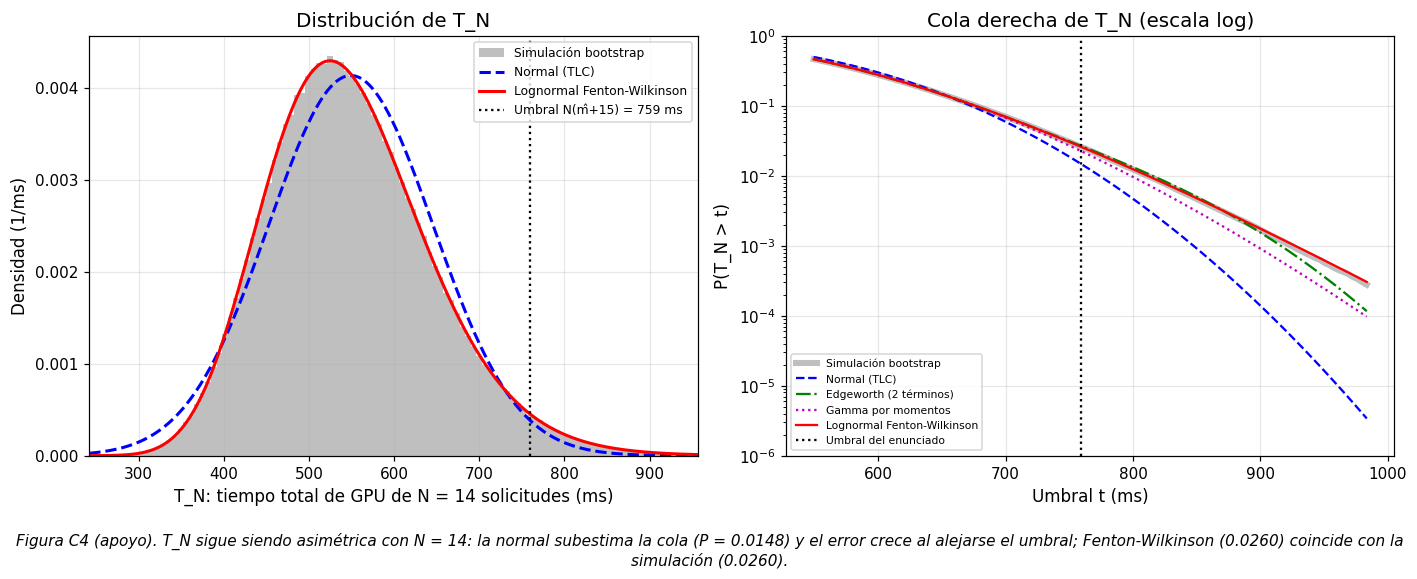

In [ ]:
# Gráfica de apoyo C4 (no es figura numerada del enunciado)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
mu_T, sd_T = N * m_c4, np.sqrt(N * v_c4)
s2_L = np.log(1 + v_c4 / (N * m_c4**2)); mu_L = np.log(N * m_c4) - s2_L / 2

ts = np.linspace(T_boot.min(), np.quantile(T_boot, 0.9995), 400)
ax[0].hist(T_boot, bins=150, density=True, color="grey", alpha=0.5, label="Simulación bootstrap")
ax[0].plot(ts, stats.norm.pdf(ts, mu_T, sd_T), "b--", lw=2, label="Normal (TLC)")
ax[0].plot(ts, stats.lognorm.pdf(ts, np.sqrt(s2_L), scale=np.exp(mu_L)), "r-", lw=2, label="Lognormal Fenton-Wilkinson")
ax[0].axvline(umbral_c4, color="black", linestyle=":", label=f"Umbral N(m̂+15) = {umbral_c4:.0f} ms")
ax[0].set_xlabel(f"T_N: tiempo total de GPU de N = {N} solicitudes (ms)")
ax[0].set_ylabel("Densidad (1/ms)")
ax[0].set_xlim(ts.min(), ts.max())
ax[0].set_title("Distribución de T_N")
ax[0].legend(fontsize=8)

ts2 = np.linspace(mu_T, mu_T + 4.5 * sd_T, 120)
T_ord = np.sort(T_boot)
sup_sim = 1 - np.searchsorted(T_ord, ts2, side="right") / R_C4  # P(T > t) simulada
estilos = {"Normal (TLC)": "b--", "Edgeworth (2 términos)": "g-.", "Gamma por momentos": "m:", "Lognormal Fenton-Wilkinson": "r-"}
ax[1].semilogy(ts2, np.where(sup_sim > 0, sup_sim, np.nan), color="grey", lw=4, alpha=0.5, label="Simulación bootstrap")
for k_, est in estilos.items():
    ax[1].semilogy(ts2, [aproximaciones_c4(m_c4, v_c4, gam_c4, kap_c4, t=t_)[k_] for t_ in ts2], est, lw=1.5, label=k_)
ax[1].axvline(umbral_c4, color="black", linestyle=":", label="Umbral del enunciado")
ax[1].set_ylim(1e-6, 1)
ax[1].set_xlabel("Umbral t (ms)")
ax[1].set_ylabel("P(T_N > t)")
ax[1].set_title("Cola derecha de T_N (escala log)")
ax[1].legend(fontsize=7, loc="lower left")
plt.tight_layout()
pie_de_figura(fig, "C4 (apoyo)",
              f"T_N sigue siendo asimétrica con N = {N}: la normal subestima la cola (P = {p_aprox['Normal (TLC)']:.4f}) y el error "
              f"crece al alejarse el umbral; Fenton-Wilkinson ({p_aprox['Lognormal Fenton-Wilkinson']:.4f}) coincide con la simulación ({p_ref:.4f}).")
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_C4.png"), bbox_inches="tight")
plt.show()

**Conclusión C4.** Con $N = 14$ y $\hat m = 39{,}23$ ms, el umbral es $N(\hat m + 15) = 759{,}2$ ms, a 2,18 desviaciones estándar de la media de $T_N$ (549,2 ms). La probabilidad de superarlo es **≈ 0,026** (referencia por simulación bootstrap: 0,0260; IC 90 % por incertidumbre de estimación [0,022; 0,030]). Es decir, **uno de cada ~38 grupos** de 14 solicitudes no cacheadas consume más de 15 ms extra por solicitud. Los bloques reales de 14 solicitudes consecutivas lo confirman: 36 de 1335, es decir 0,027 [0,020; 0,036]. La autocorrelación en orden de llegada (−0,0004, p = 0,95) respalda el supuesto de independencia.

| Método | P(T₁₄ > 759,2) | Error relativo |
|---|---|---|
| Normal (TLC) | 0,0148 | **−43 %** |
| Gamma por momentos | 0,0225 | −13 % |
| Edgeworth (2 términos) | 0,0267 | +3 % |
| **Lognormal Fenton-Wilkinson** | **0,0260** | **≈ 0 %** |
| Simulación con la lognormal de C2 | 0,0333 | +28 % |

- **Por qué falla la normal:** las cuatro aproximaciones aciertan en media y varianza, pero la suma de 14 tiempos de GPU sigue siendo asimétrica (asimetría $\gamma/\sqrt N = 0{,}52$), y el umbral está en la cola derecha. La normal supone asimetría 0 y **subestima la probabilidad casi a la mitad**; su intervalo [0,012; 0,018] ni siquiera toca el de la referencia. El panel derecho de la gráfica muestra que el error crece cuanto más lejos está el umbral. Con $N = 14$, el TLC todavía no ha "borrado" la asimetría.
- **Por qué acierta Fenton-Wilkinson:** la lognormal con la media y la varianza de $T_N$ tiene asimetría 0,533, prácticamente la verdadera (0,524). La gamma asigna solo 0,352 y por eso se queda corta. Edgeworth usa la asimetría real y también acierta, pero es una corrección polinómica que puede dar valores fuera de [0, 1] en colas lejanas; la lognormal siempre da una probabilidad válida.
- **El modelo marginal importa:** simular con la lognormal ajustada en C2 sobreestima en un 28 %, porque ese modelo pone la cola de $X$ un poco más pesada que la real (C2: percentil 99,9 de 222 frente a 202 ms). Para sumas, es mejor aproximar la **suma** con sus momentos que encadenar un modelo marginal imperfecto.
- **Recomendación:** usar **Fenton-Wilkinson** como aproximación analítica (fórmula cerrada, probabilidad siempre válida, error ≈ 0 % aquí) y verificarla con simulación bootstrap. La incertidumbre de estimación (IC ≈ [0,022; 0,030]) es mayor que la diferencia entre Fenton-Wilkinson y Edgeworth, pero no explica el error de la normal: ese error es **sistemático**, no de muestreo.

# Parte D - Dependencias y esperanza condicional (14 pts)

### D1. Conjunta (clase de tamaño, cache_hit)

**Qué se pide.** Con las fronteras del grupo, $t_1 = 90$ KB y $t_2 = 425$ KB, cada solicitud del régimen estable se clasifica por tamaño: **pequeña** ($<t_1$), **mediana** ($t_1 \le \cdot < t_2$) o **grande** ($\ge t_2$). Se estudia el vector $(T, H)$, con $T$ la clase de tamaño y $H$ = `cache_hit`.

- **Conjunta:** $p_{ij} = P(T = i, H = j)$, estimada por la proporción de solicitudes en cada celda.
- **Marginales:** $p_{i\cdot} = \sum_j p_{ij}$ y $p_{\cdot j} = \sum_i p_{ij}$.
- **Condicionales:** $P(H = 1 \mid T = i) = p_{i1}/p_{i\cdot}$ y $P(T = i \mid H = j) = p_{ij}/p_{\cdot j}$.
- **Independencia:** $T$ y $H$ son independientes si y solo si $p_{ij} = p_{i\cdot}\,p_{\cdot j}$ para todas las celdas, lo que equivale a que $P(H = 1 \mid T = i)$ sea **la misma para las tres clases**.

In [ ]:
# Paso 1. Clases de tamaño, distribución conjunta, marginales y condicionales
ORDEN_CLASES = ["pequeña", "mediana", "grande"]
clase = pd.cut(df_estable.tam_kb, bins=[-np.inf, t1_kb, t2_kb, np.inf], right=False, labels=ORDEN_CLASES)
H = df_estable.cache_hit.astype(int)
n_d1 = len(df_estable)

conteos_d1 = pd.crosstab(clase, H).reindex(ORDEN_CLASES)        # n_ij
conteos_d1.columns = ["sin caché (H=0)", "con caché (H=1)"]
conjunta = conteos_d1 / n_d1                                    # p_ij
tabla_conj = conjunta.copy()
tabla_conj["marginal P(T)"] = conjunta.sum(axis=1)              # p_i.
tabla_conj.loc["marginal P(H)"] = list(conjunta.sum(axis=0)) + [1.0]   # p_.j
print(f"t1 = {t1_kb} KB, t2 = {t2_kb} KB, n = {n_d1}\n")
print("Conteos:"); print(conteos_d1.to_string(), "\n")
print("Distribución conjunta con marginales:"); print(tabla_conj.round(4).to_string(), "\n")

# Condicional P(H = 1 | T = i) con IC exacto de Clopper-Pearson
filas_d1 = []
for c_ in ORDEN_CLASES:
    k_, n_ = int(conteos_d1.loc[c_, "con caché (H=1)"]), int(conteos_d1.loc[c_].sum())
    li_ = stats.beta.ppf(alpha / 2, k_, n_ - k_ + 1); ls_ = stats.beta.ppf(1 - alpha / 2, k_ + 1, n_ - k_)
    filas_d1.append({"clase": c_, "n": n_, "P(caché | clase)": formatear_intervalo(k_ / n_, li_, ls_, "Clopper-Pearson", 3)})
k_t, n_t = int(H.sum()), n_d1
filas_d1.append({"clase": "todas", "n": n_t, "P(caché | clase)": formatear_intervalo(
    k_t / n_t, stats.beta.ppf(alpha / 2, k_t, n_t - k_t + 1), stats.beta.ppf(1 - alpha / 2, k_t + 1, n_t - k_t), "Clopper-Pearson", 3)})
print("Condicional P(H = 1 | T):"); print(pd.DataFrame(filas_d1).set_index("clase").to_string(), "\n")
print("Condicional P(T | H) (columnas suman 1):"); print((conteos_d1 / conteos_d1.sum(axis=0)).round(4).to_string())

t1 = 90 KB, t2 = 425 KB, n = 28162

Conteos:
         sin caché (H=0)  con caché (H=1)
tam_kb                                   
pequeña             2194             2477
mediana            13383             6347
grande              3127              634 

Distribución conjunta con marginales:
               sin caché (H=0)  con caché (H=1)  marginal P(T)
tam_kb                                                        
pequeña                 0.0779           0.0880         0.1659
mediana                 0.4752           0.2254         0.7006
grande                  0.1110           0.0225         0.1335
marginal P(H)           0.6642           0.3358         1.0000 

Condicional P(H = 1 | T):
             n                                          P(caché | clase)
clase                                                                   
pequeña   4671  0.530  [0.518, 0.542]  (IC 90%, método: Clopper-Pearson)
mediana  19730  0.322  [0.316, 0.327]  (IC 90%, método: Clopper-Pearson)
grande 

**Paso 2. ¿Son independientes?** Se usan dos pruebas y medidas del tamaño del efecto:
1. **χ² de independencia de Pearson**, $X^2 = \sum_{ij} (n_{ij} - e_{ij})^2/e_{ij}$ con $e_{ij} = n\,\hat p_{i\cdot}\hat p_{\cdot j}$ y $(3-1)(2-1) = 2$ grados de libertad.
2. **Razón de verosimilitud** (prueba G), $G = 2\sum_{ij} n_{ij}\ln(n_{ij}/e_{ij})$, con la misma distribución de referencia.
3. **Tamaño del efecto:** la V de Cramér, $V = \sqrt{X^2/(n\cdot\min(r-1, c-1))}$, entre 0 (independencia) y 1; y la razón $\hat p_{ij}/(\hat p_{i\cdot}\hat p_{\cdot j})$ de cada celda (1 bajo independencia).
4. **Intervalos para las diferencias** $P(H=1\mid T=i) - P(H=1\mid T=j)$ entre pares de clases, con corrección de Bonferroni porque son 3 comparaciones simultáneas: si ninguno contiene el 0, la dependencia está en todos los pares.

In [ ]:
# Paso 2. Pruebas de independencia, tamaño del efecto e intervalos de las diferencias
chi2_d1, p_chi2_d1, gl_d1, esperadas = stats.chi2_contingency(conteos_d1, correction=False)
G_d1 = 2 * (conteos_d1.values * np.log(conteos_d1.values / esperadas)).sum()
p_G_d1 = stats.chi2.sf(G_d1, gl_d1)
V_cramer = np.sqrt(chi2_d1 / (n_d1 * (min(conteos_d1.shape) - 1)))
print(f"Chi^2 de Pearson = {chi2_d1:.1f}, gl = {gl_d1}, p = {p_chi2_d1:.1e}")
print(f"Prueba G (razón de verosimilitud) = {G_d1:.1f}, gl = {gl_d1}, p = {p_G_d1:.1e}")
print(f"V de Cramér = {V_cramer:.3f} -> {'efecto pequeño' if V_cramer < 0.3 else 'efecto moderado o grande'} pero muy significativo por el tamaño de muestra")

razon = conteos_d1 / esperadas                                  # p_ij / (p_i. p_.j)
print("\nRazón observado / esperado bajo independencia:"); print(razon.round(3).to_string())

# Diferencias de P(caché | clase) entre pares, IC de Wald con Bonferroni (3 comparaciones)
z_d1 = stats.norm.ppf(1 - alpha / (2 * 3))
p_c = {c_: conteos_d1.loc[c_, "con caché (H=1)"] / conteos_d1.loc[c_].sum() for c_ in ORDEN_CLASES}
n_c = {c_: conteos_d1.loc[c_].sum() for c_ in ORDEN_CLASES}
print(f"\nDiferencias de P(caché | clase), IC {nivel_confianza:.0%} conjunto (Wald + Bonferroni):")
for a_, b_ in [("pequeña", "mediana"), ("mediana", "grande"), ("pequeña", "grande")]:
    dif_ = p_c[a_] - p_c[b_]
    ee_ = np.sqrt(p_c[a_] * (1 - p_c[a_]) / n_c[a_] + p_c[b_] * (1 - p_c[b_]) / n_c[b_])
    print(f"  {a_:8s} - {b_:8s}: {dif_:.3f}  [{dif_ - z_d1 * ee_:.3f}, {dif_ + z_d1 * ee_:.3f}]")

# Contraste de sensibilidad: ¿cómo cambia P(caché) con el tamaño dentro de las clases? (deciles de tam_kb)
dec_tam = pd.qcut(df_estable.tam_kb, 10)
print("\nP(caché) por decil de tam_kb (KB):")
print(H.groupby(dec_tam, observed=True).mean().round(3).to_string())

Chi^2 de Pearson = 1281.3, gl = 2, p = 5.9e-279
Prueba G (razón de verosimilitud) = 1291.5, gl = 2, p = 3.6e-281
V de Cramér = 0.213 -> efecto pequeño pero muy significativo por el tamaño de muestra

Razón observado / esperado bajo independencia:
         sin caché (H=0)  con caché (H=1)
tam_kb                                   
pequeña            0.707            1.579
mediana            1.021            0.958
grande             1.252            0.502

Diferencias de P(caché | clase), IC 90% conjunto (Wald + Bonferroni):
  pequeña  - mediana : 0.209  [0.192, 0.226]
  mediana  - grande  : 0.153  [0.138, 0.168]
  pequeña  - grande  : 0.362  [0.341, 0.382]

P(caché) por decil de tam_kb (KB):
tam_kb
(1.249, 66.117]      0.531
(66.117, 101.636]    0.447
(101.636, 133.68]    0.331
(133.68, 167.654]    0.313
(167.654, 204.26]    0.315
(204.26, 246.124]    0.326
(246.124, 295.63]    0.327
(295.63, 360.72]     0.326
(360.72, 466.7]      0.272
(466.7, 1501.27]     0.169


### Figura 4
Mapa de calor de la distribución conjunta $\hat p_{ij}$ (izquierda) y de la razón observado / esperado bajo independencia (derecha). Bajo independencia, el panel derecho sería todo 1.

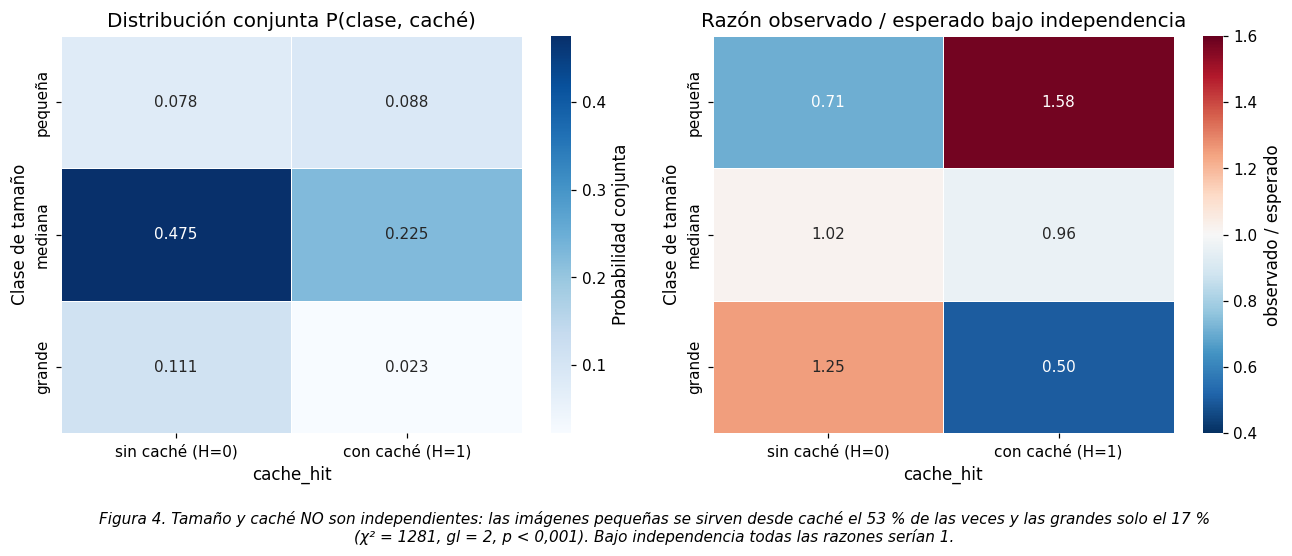

In [ ]:
# Figura 4. Mapa de calor de la conjunta (clase de tamaño, cache_hit)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
sns.heatmap(conjunta, annot=conjunta.map(lambda v: f"{v:.3f}"), fmt="", cmap="Blues", cbar_kws={"label": "Probabilidad conjunta"},
            linewidths=0.5, ax=ax[0])
ax[0].set_title("Distribución conjunta P(clase, caché)")
ax[0].set_xlabel("cache_hit"); ax[0].set_ylabel("Clase de tamaño"); ax[0].grid(False)

sns.heatmap(razon, annot=razon.map(lambda v: f"{v:.2f}"), fmt="", cmap="RdBu_r", center=1, vmin=0.4, vmax=1.6,
            cbar_kws={"label": "observado / esperado"}, linewidths=0.5, ax=ax[1])
ax[1].set_title("Razón observado / esperado bajo independencia")
ax[1].set_xlabel("cache_hit"); ax[1].set_ylabel("Clase de tamaño"); ax[1].grid(False)

pie_de_figura(fig, 4, f"Tamaño y caché NO son independientes: las imágenes pequeñas se sirven desde caché el {100 * p_c['pequeña']:.0f} % de las veces "
                      f"y las grandes solo el {100 * p_c['grande']:.0f} %\n(χ² = {chi2_d1:.0f}, gl = 2, p < 0,001). Bajo independencia todas las razones serían 1.")
plt.tight_layout()
guardar_figura(fig, 4)
plt.show()

**Conclusión D1.** La clase de tamaño y la caché **no son independientes** (χ² = 1281 y prueba G = 1292, gl = 2, p < 0,001). La probabilidad de servir desde caché baja con el tamaño: 0,53 en las pequeñas, 0,32 en las medianas y 0,17 en las grandes, y los intervalos de las tres diferencias excluyen el 0. El efecto es de magnitud pequeña a moderada (V de Cramér = 0,21), y por deciles de tamaño **no es gradual**: la proporción es casi constante (≈ 0,32) entre ~100 y ~360 KB y cambia solo en los extremos, justo donde caen las fronteras $t_1$ y $t_2$. **Consecuencia:** la masa en 0 de $G$ (C1) no es la misma para todos los tamaños. Las imágenes grandes casi siempre llegan a la GPU y además tardan más en ella (C2), así que la carga de la GPU se concentra en ellas. Esto se modela en D2 y D3.

### D2. Esperanza condicional

**Qué se pide.** Estimar sin suponer ninguna forma funcional (de forma **no paramétrica**):
- $E[G \mid \text{clase}, \text{no caché}]$: el tiempo medio de GPU de las solicitudes que sí usan GPU, en cada clase de tamaño de D1.
- $E[G \mid \text{tam\_kb}]$: el tiempo medio de GPU (de **todas** las solicitudes, con las cacheadas valiendo 0) como función continua del tamaño.

Después se verifican con los datos las dos leyes que conectan lo condicional con lo marginal:
$$\textbf{Esperanza total: } E[G] = E\big[E[G \mid Y]\big] = \sum_y P(Y = y)\,E[G \mid Y = y]$$
$$\textbf{Varianza total: } \text{Var}(G) = \underbrace{E\big[\text{Var}(G \mid Y)\big]}_{\text{dentro de los grupos}} + \underbrace{\text{Var}\big(E[G \mid Y]\big)}_{\text{entre grupos}}$$
donde $Y$ es la variable con la que se condiciona (la clase de tamaño, la caché o ambas). El cociente $\eta^2 = \text{Var}(E[G \mid Y])/\text{Var}(G)$ es la **fracción de la varianza de $G$ explicada por $Y$**.

**Cómo se conecta con C1 y D1.** Como $G = 0$ si hay caché, para cualquier clase o tamaño
$$E[G \mid \text{clase}] = P(\text{no caché} \mid \text{clase})\cdot E[G \mid \text{clase}, \text{no caché}].$$
El tamaño influye en $G$ por **dos caminos**: las imágenes grandes tardan más en la GPU (C2) **y** casi nunca están en caché (D1). Los dos empujan en la misma dirección.

In [ ]:
# Paso 1. E[G | clase, no caché] y E[G | clase] (todas), con intervalos; descomposición por los dos caminos
# `clase` (pequeña / mediana / grande) y ORDEN_CLASES vienen de D1; G y `cache` vienen de C1 (todas las solicitudes del régimen estable)
G_d2 = df_estable.gpu_ms.to_numpy()                             # G de todas las solicitudes (0 si hubo caché)
clase_d2 = clase.to_numpy()                                     # clase de tamaño de cada solicitud

filas_d2 = []
for c_ in ORDEN_CLASES:
    en_c = clase_d2 == c_                                       # solicitudes de esta clase
    g_nc = G_d2[en_c & ~cache]                                  # ...que además usaron GPU
    g_all = G_d2[en_c]                                          # ...todas (cacheadas con G = 0)
    t_nc = stats.t.ppf(1 - alpha / 2, len(g_nc) - 1)
    t_all = stats.t.ppf(1 - alpha / 2, len(g_all) - 1)
    ee_nc = g_nc.std(ddof=1) / np.sqrt(len(g_nc))               # error estándar de la media (t de Student)
    ee_all = g_all.std(ddof=1) / np.sqrt(len(g_all))
    filas_d2.append({"clase": c_,
                     "P(clase)": en_c.mean(),
                     "P(no caché | clase)": 1 - cache[en_c].mean(),
                     "E[G | clase, no caché]": g_nc.mean(), "IC nc": f"[{g_nc.mean() - t_nc * ee_nc:.2f}, {g_nc.mean() + t_nc * ee_nc:.2f}]",
                     "E[G | clase]": g_all.mean(), "IC todas": f"[{g_all.mean() - t_all * ee_all:.2f}, {g_all.mean() + t_all * ee_all:.2f}]",
                     "Var(G | clase)": g_all.var(ddof=0)})
tabla_d2 = pd.DataFrame(filas_d2).set_index("clase")
# Comprobación de la identidad E[G | clase] = P(no caché | clase) · E[G | clase, no caché] (exacta también con datos)
tabla_d2["P(nc|c)·E[G|c,nc]"] = tabla_d2["P(no caché | clase)"] * tabla_d2["E[G | clase, no caché]"]
print(f"Intervalos al {nivel_confianza:.0%}, método t de Student\n")
print(tabla_d2.to_string(float_format=lambda v: f"{v:.4f}"))

# Cuánto aporta cada camino al contraste grande vs pequeña
g_, p_ = tabla_d2.loc["grande"], tabla_d2.loc["pequeña"]
print(f"\nGrande vs pequeña: E[G | clase] pasa de {p_['E[G | clase]']:.2f} a {g_['E[G | clase]']:.2f} ms (× {g_['E[G | clase]'] / p_['E[G | clase]']:.2f}).")
print(f"  camino 1 (más tiempo en GPU):     × {g_['E[G | clase, no caché]'] / p_['E[G | clase, no caché]']:.2f}")
print(f"  camino 2 (menos caché):           × {g_['P(no caché | clase)'] / p_['P(no caché | clase)']:.2f}")
print("  (el efecto total es el producto de los dos)")

Intervalos al 90%, método t de Student

         P(clase)  P(no caché | clase)  E[G | clase, no caché]           IC nc  E[G | clase]        IC todas  Var(G | clase)  P(nc|c)·E[G|c,nc]
clase                                                                                                                                          
pequeña    0.1659               0.4697                 19.2408  [18.93, 19.55]        9.0376    [8.76, 9.31]        128.9868             9.0376
mediana    0.7006               0.6783                 35.4784  [35.21, 35.74]       24.0652  [23.80, 24.33]        507.8577            24.0652
grande     0.1335               0.8314                 69.3043  [68.28, 70.33]       57.6215  [56.52, 58.72]       1679.6951            57.6215

Grande vs pequeña: E[G | clase] pasa de 9.04 a 57.62 ms (× 6.38).
  camino 1 (más tiempo en GPU):     × 3.60
  camino 2 (menos caché):           × 1.77
  (el efecto total es el producto de los dos)


**Paso 2. $E[G \mid \text{tam\_kb}]$ no paramétrica.** Se usan dos estimadores que no suponen forma funcional:
1. **Regresograma:** se parte `tam_kb` en 20 intervalos con el mismo número de solicitudes y se promedia $G$ en cada uno (con su IC).
2. **Nadaraya-Watson (kernel gaussiano), programado por el grupo:**
$$\hat m(x) = \frac{\sum_i K_h(u_i - u)\,G_i}{\sum_i K_h(u_i - u)}, \qquad u = \ln x,$$
un promedio de $G$ ponderado por la cercanía en tamaño. Se trabaja en escala logarítmica porque `tam_kb` es muy asimétrico (hay pocas imágenes grandes): así la ventana se adapta sola y es más estrecha en KB donde hay muchos datos. El ancho de banda se elige con la **regla de Silverman**, $h = 0{,}9\min(s, \text{IQR}/1{,}34)\,n^{-1/5}$, y se revisa la sensibilidad con $h/2$ y $2h$.

**Discontinuidades en las fronteras de clase.** D1 mostró que $P(\text{caché})$ cambia con el tamaño justo en $t_1$ y $t_2$. Si cambia **en escalón**, entonces $E[G \mid \text{tam}]$ también salta en esas fronteras, y un suavizador global las difumina. Se prueba comparando $P(\text{caché})$ justo a cada lado de cada frontera (±25 KB) y dentro de cada clase por cuartiles. Si se confirma, se usa además un Nadaraya-Watson **calculado por separado dentro de cada clase**, que no promedia a través de las fronteras.

Con los mismos pesos, Nadaraya-Watson cumple **exactamente** $\hat E[G \mid x] = \hat P(\text{no caché} \mid x)\cdot\hat E[G \mid x, \text{no caché}]$, la misma identidad del paso 1 pero ahora para cada tamaño.

In [ ]:
# Paso 2. E[G | tam_kb]: regresograma y Nadaraya-Watson (programado a mano)
tam_d2 = df_estable.tam_kb.to_numpy()
u_d2 = np.log(tam_d2)                                           # se suaviza en log(tam) por la asimetría de tam_kb
iqr_u = np.subtract(*np.quantile(u_d2, [0.75, 0.25]))
h_silv = 0.9 * min(u_d2.std(ddof=1), iqr_u / 1.34) * len(u_d2) ** (-1 / 5)   # regla de Silverman


def nadaraya_watson(u_eval, u_obs, y_obs, h, bloque=200):
    # Promedio de y_obs ponderado por un kernel gaussiano centrado en cada punto de u_eval (en bloques para no agotar memoria)
    salida = np.empty(len(u_eval))
    for i0 in range(0, len(u_eval), bloque):
        w = np.exp(-0.5 * ((u_eval[i0:i0 + bloque, None] - u_obs[None, :]) / h) ** 2)   # pesos K_h(u_i - u)
        salida[i0:i0 + bloque] = (w @ y_obs) / w.sum(axis=1)                            # sum w·y / sum w
    return salida


u_grid = np.linspace(np.quantile(u_d2, 0.005), np.quantile(u_d2, 0.995), 200)   # tamaños donde se evalúa la curva
nw = {}
for nombre, hh in [("h/2", h_silv / 2), ("h", h_silv), ("2h", 2 * h_silv)]:
    nw[nombre] = nadaraya_watson(u_grid, u_d2, G_d2, hh)        # E[G | tam] con todas las solicitudes
nw_pnc = nadaraya_watson(u_grid, u_d2, (~cache).astype(float), h_silv)          # P(no caché | tam)
nw_nc = nadaraya_watson(u_grid, u_d2[~cache], G_d2[~cache], h_silv)            # E[G | tam, no caché]
print(f"Ancho de banda de Silverman en log(tam): h = {h_silv:.4f}")
centro = (u_grid >= np.quantile(u_d2, 0.05)) & (u_grid <= np.quantile(u_d2, 0.95))   # 90 % central de los tamaños
for zona, m_ in [("90 % central de tam_kb", centro), ("colas (5 % de cada lado)", ~centro)]:
    print(f"Sensibilidad en {zona}: máx |m̂_h/2 − m̂_h| = {np.abs(nw['h/2'] - nw['h'])[m_].max():.2f} ms, "
          f"máx |m̂_2h − m̂_h| = {np.abs(nw['2h'] - nw['h'])[m_].max():.2f} ms")

# ¿P(caché) cambia en escalón en las fronteras t1 y t2? Comparación justo a cada lado (±25 KB) con prueba z de dos proporciones
VEC = 25.0
print(f"\nP(caché) a cada lado de las fronteras (ventanas de {VEC:.0f} KB):")
for t_ in (t1_kb, t2_kb):
    izq = cache[(tam_d2 >= t_ - VEC) & (tam_d2 < t_)]; der = cache[(tam_d2 >= t_) & (tam_d2 < t_ + VEC)]
    p_pool = np.r_[izq, der].mean()
    z_esc = (izq.mean() - der.mean()) / np.sqrt(p_pool * (1 - p_pool) * (1 / len(izq) + 1 / len(der)))
    print(f"  t = {t_} KB: [{t_ - VEC:.0f}, {t_}) -> {izq.mean():.3f} (n = {len(izq)}) | [{t_}, {t_ + VEC:.0f}) -> {der.mean():.3f} "
          f"(n = {len(der)}) | z = {z_esc:.1f}, p = {2 * stats.norm.sf(abs(z_esc)):.1e}")
print("P(caché) dentro de cada clase, por cuartiles de tamaño (si es constante, la caché depende de la clase y no del tamaño fino):")
for c_ in ORDEN_CLASES:
    en_c = clase_d2 == c_
    cuart = pd.qcut(tam_d2[en_c], 4, labels=False)
    tabla_q = pd.crosstab(cuart, cache[en_c])
    print(f"  {c_:8s}: {np.round(pd.Series(cache[en_c]).groupby(cuart).mean().to_numpy(), 3)} | "
          f"chi2 de homogeneidad p = {stats.chi2_contingency(tabla_q)[1]:.3f}")

# Nadaraya-Watson por clase: se suaviza solo DENTRO de cada clase, para no difuminar los escalones de las fronteras
lim_u = {"pequeña": (-np.inf, np.log(t1_kb)), "mediana": (np.log(t1_kb), np.log(t2_kb)), "grande": (np.log(t2_kb), np.inf)}
nw_clase = np.empty(len(u_grid))
for c_, (a_, b_) in lim_u.items():
    en_g, en_c = (u_grid >= a_) & (u_grid < b_), clase_d2 == c_
    nw_clase[en_g] = nadaraya_watson(u_grid[en_g], u_d2[en_c], G_d2[en_c], h_silv)
print(f"Identidad E[G|x] = P(nc|x)·E[G|x,nc] con Nadaraya-Watson: máx diferencia = {np.abs(nw['h'] - nw_pnc * nw_nc).max():.2e} ms")

# Regresograma: 20 intervalos de igual frecuencia
bins_d2 = pd.qcut(tam_d2, 20)
regres = pd.DataFrame({"tam": tam_d2, "G": G_d2, "nc": ~cache}).groupby(bins_d2, observed=True).agg(
    tam_medio=("tam", "mean"), E_G=("G", "mean"), sd_G=("G", "std"), n=("G", "size"), P_nc=("nc", "mean"))
regres["ee"] = regres.sd_G / np.sqrt(regres.n)
regres["E_G_nc"] = [G_d2[(bins_d2 == b_) & ~cache].mean() for b_ in regres.index]   # E[G | intervalo, no caché]
nw_en_bins = np.interp(np.log(regres.tam_medio.to_numpy()), u_grid, nw["h"])
nwc_en_bins = np.interp(np.log(regres.tam_medio.to_numpy()), u_grid, nw_clase)
# Solo se comparan intervalos que caen enteros dentro de una clase: los que cruzan t1 o t2 mezclan dos niveles de caché
dentro_clase = np.array([not (iv.left < t_ < iv.right) for iv in regres.index for t_ in (t1_kb, t2_kb)]).reshape(-1, 2).all(axis=1)
print(f"\nRegresograma vs Nadaraya-Watson en los {dentro_clase.sum()} intervalos que no cruzan una frontera: diferencia máxima = "
      f"{np.abs(regres.E_G - nw_en_bins)[dentro_clase].max():.2f} ms (global), {np.abs(regres.E_G - nwc_en_bins)[dentro_clase].max():.2f} ms (por clase) "
      f"| error estándar típico de cada intervalo ≈ {regres.ee.median():.2f} ms")
print(f"En los {(~dentro_clase).sum()} intervalos que cruzan una frontera, el propio regresograma promedia los dos lados del escalón.")
print(regres[["tam_medio", "P_nc", "E_G_nc", "E_G"]].round(2).iloc[::3].to_string())

Ancho de banda de Silverman en log(tam): h = 0.0878
Sensibilidad en 90 % central de tam_kb: máx |m̂_h/2 − m̂_h| = 1.46 ms, máx |m̂_2h − m̂_h| = 3.12 ms
Sensibilidad en colas (5 % de cada lado): máx |m̂_h/2 − m̂_h| = 7.57 ms, máx |m̂_2h − m̂_h| = 9.00 ms

P(caché) a cada lado de las fronteras (ventanas de 25 KB):
  t = 90 KB: [65, 90) -> 0.528 (n = 1925) | [90, 115) -> 0.305 (n = 2117) | z = 14.4, p = 5.2e-47
  t = 425 KB: [400, 425) -> 0.301 (n = 662) | [425, 450) -> 0.176 (n = 603) | z = 5.2, p = 2.2e-07
P(caché) dentro de cada clase, por cuartiles de tamaño (si es constante, la caché depende de la clase y no del tamaño fino):
  pequeña : [0.537 0.523 0.522 0.539] | chi2 de homogeneidad p = 0.760
  mediana : [0.322 0.309 0.329 0.326] | chi2 de homogeneidad p = 0.159
  grande  : [0.167 0.17  0.19  0.147] | chi2 de homogeneidad p = 0.093
Identidad E[G|x] = P(nc|x)·E[G|x,nc] con Nadaraya-Watson: máx diferencia = 4.26e-14 ms

Regresograma vs Nadaraya-Watson en los 18 intervalos que no cru

**Paso 3. Ley de la esperanza total.** Se comprueba con cuatro variables de condicionamiento: la clase, la caché, la clase y la caché juntas, y los 20 intervalos de tamaño. Con proporciones y medias muestrales la ley se cumple **exactamente**, salvo por el redondeo numérico: el promedio global es el promedio ponderado de los promedios de cada grupo. También se comprueba con la curva de Nadaraya-Watson promediada sobre la distribución de `tam_kb`; ahí la igualdad es solo **aproximada**, porque la curva suaviza.

In [ ]:
# Paso 3. Ley de la esperanza total E[G] = sum_y P(Y = y) E[G | Y = y], para varias Y
def esperanza_total(g, grupos):
    # Devuelve sum_y P(Y = y) · E[G | Y = y] usando las proporciones y medias muestrales
    s = pd.Series(g).groupby(np.asarray(grupos), observed=True)
    return (s.size() / len(g) * s.mean()).sum()


grupos_d2 = {"clase de tamaño": clase_d2.astype(str),
             "caché": cache.astype(int),
             "clase × caché": np.char.add(clase_d2.astype(str), cache.astype(int).astype(str)),
             "20 intervalos de tam_kb": bins_d2.codes}
EG_d2 = G_d2.mean()
print(f"E[G] muestral (directo) = {EG_d2:.6f} ms")
for nombre, gr in grupos_d2.items():
    print(f"  E[E[G | {nombre:24s}]] = {esperanza_total(G_d2, gr):.6f} ms  (diferencia {esperanza_total(G_d2, gr) - EG_d2:+.1e})")
EG_nw = nadaraya_watson(u_d2, u_d2, G_d2, h_silv).mean()        # promedio de la curva sobre los tamaños observados
print(f"  promedio de Nadaraya-Watson sobre tam_kb  = {EG_nw:.6f} ms  (diferencia {EG_nw - EG_d2:+.1e}, aproximada por el suavizado)")

# Versión explícita con la clase: la cadena de C1 (masa en 0) y D1 (caché según tamaño)
print("\nCon la clase: E[G] = sum_i P(clase i) · P(no caché | i) · E[G | i, no caché]")
print("           = " + " + ".join(f"{r_['P(clase)']:.4f}·{r_['P(no caché | clase)']:.4f}·{r_['E[G | clase, no caché]']:.3f}"
                             for _, r_ in tabla_d2.iterrows()) + f" = {(tabla_d2['P(clase)'] * tabla_d2['P(nc|c)·E[G|c,nc]']).sum():.4f} ms")

E[G] muestral (directo) = 26.054115 ms
  E[E[G | clase de tamaño         ]] = 26.054115 ms  (diferencia +3.6e-15)
  E[E[G | caché                   ]] = 26.054115 ms  (diferencia -3.6e-15)
  E[E[G | clase × caché           ]] = 26.054115 ms  (diferencia +3.6e-15)
  E[E[G | 20 intervalos de tam_kb ]] = 26.054115 ms  (diferencia +0.0e+00)
  promedio de Nadaraya-Watson sobre tam_kb  = 25.966827 ms  (diferencia -8.7e-02, aproximada por el suavizado)

Con la clase: E[G] = sum_i P(clase i) · P(no caché | i) · E[G | i, no caché]
           = 0.1659·0.4697·19.241 + 0.7006·0.6783·35.478 + 0.1335·0.8314·69.304 = 26.0541 ms


**Paso 4. Ley de la varianza total y fracción explicada.** Para cada variable de condicionamiento se calculan por separado los dos términos, $E[\text{Var}(G \mid Y)]$ y $\text{Var}(E[G \mid Y])$, y se comprueba que suman $\text{Var}(G)$. Se usan varianzas con divisor $n$, para que la identidad sea exacta con datos. La **fracción explicada por la clase**, $\eta^2_{\text{clase}}$, lleva un IC por bootstrap. Las demás filas sirven de contexto: la caché sola, la clase y la caché juntas, y el tamaño continuo, aproximado con 20 intervalos, con y sin caché.

In [ ]:
# Paso 4. Ley de la varianza total: Var(G) = E[Var(G|Y)] + Var(E[G|Y]), con varianzas de divisor n (identidad exacta)
def varianza_total(g, grupos):
    # Devuelve (E[Var(G|Y)], Var(E[G|Y])) con proporciones, medias y varianzas muestrales (divisor n)
    s = pd.Series(g).groupby(np.asarray(grupos), observed=True)
    peso = s.size() / len(g)                                    # P(Y = y)
    dentro = (peso * s.var(ddof=0)).sum()                       # E[Var(G | Y)]: variabilidad dentro de cada grupo
    entre = (peso * (s.mean() - g.mean()) ** 2).sum()           # Var(E[G | Y]): variabilidad de las medias de grupo
    return dentro, entre


VarG_d2 = G_d2.var(ddof=0)
grupos_d2["20 intervalos de tam_kb × caché"] = bins_d2.codes * 2 + cache.astype(int)
filas_vt = []
for nombre, gr in grupos_d2.items():
    dentro, entre = varianza_total(G_d2, gr)
    filas_vt.append({"condicionando en": nombre, "E[Var(G|Y)]": dentro, "Var(E[G|Y])": entre,
                     "suma": dentro + entre, "Var(G)": VarG_d2, "η² = explicada": entre / VarG_d2})
tabla_vt = pd.DataFrame(filas_vt).set_index("condicionando en")
print(tabla_vt.to_string(float_format=lambda v: f"{v:.4f}"))
print(f"Máxima diferencia |suma − Var(G)| = {np.abs(tabla_vt['suma'] - VarG_d2).max():.1e} ms²  -> la ley se cumple")

# IC bootstrap de la fracción explicada por la clase
B_D2 = 1000
eta_boot = np.empty(B_D2)
for b in range(B_D2):
    idx = rng.integers(0, len(G_d2), len(G_d2))
    d_, e_ = varianza_total(G_d2[idx], clase_d2[idx].astype(str))
    eta_boot[b] = e_ / (d_ + e_)
eta_clase = tabla_vt.loc["clase de tamaño", "η² = explicada"]
print("\nFracción de Var(G) explicada por la clase:",
      formatear_intervalo(eta_clase, *np.quantile(eta_boot, [alpha / 2, 1 - alpha / 2]), "bootstrap percentil", 4))

# Misma pregunta restringida a las no cacheadas (la parte continua de C2)
d_nc, e_nc = varianza_total(G_d2[~cache], clase_d2[~cache].astype(str))
print(f"Solo no cacheadas: la clase explica {e_nc / (d_nc + e_nc):.4f} de Var(G | no caché)")

                                 E[Var(G|Y)]  Var(E[G|Y])     suma   Var(G)  η² = explicada
condicionando en                                                                           
clase de tamaño                     601.5150     183.8799 785.3949 785.3949          0.2341
caché                               442.1394     343.2555 785.3949 785.3949          0.4370
clase × caché                       303.8943     481.5005 785.3949 785.3949          0.6131
20 intervalos de tam_kb             566.9863     218.4086 785.3949 785.3949          0.2781
20 intervalos de tam_kb × caché     253.7670     531.6278 785.3949 785.3949          0.6769
Máxima diferencia |suma − Var(G)| = 2.0e-12 ms²  -> la ley se cumple

Fracción de Var(G) explicada por la clase: 0.2341  [0.2247, 0.2433]  (IC 90%, método: bootstrap percentil)
Solo no cacheadas: la clase explica 0.3127 de Var(G | no caché)


**Gráfica de apoyo.** Izquierda: $E[G \mid \text{tam\_kb}]$ por los dos estimadores no paramétricos, junto con $E[G \mid \text{tam\_kb}, \text{no caché}]$ y las medias por clase (segmentos horizontales). La distancia entre las dos curvas es el efecto de la caché. Derecha: descomposición de $\text{Var}(G)$ en parte explicada y no explicada según con qué se condicione.

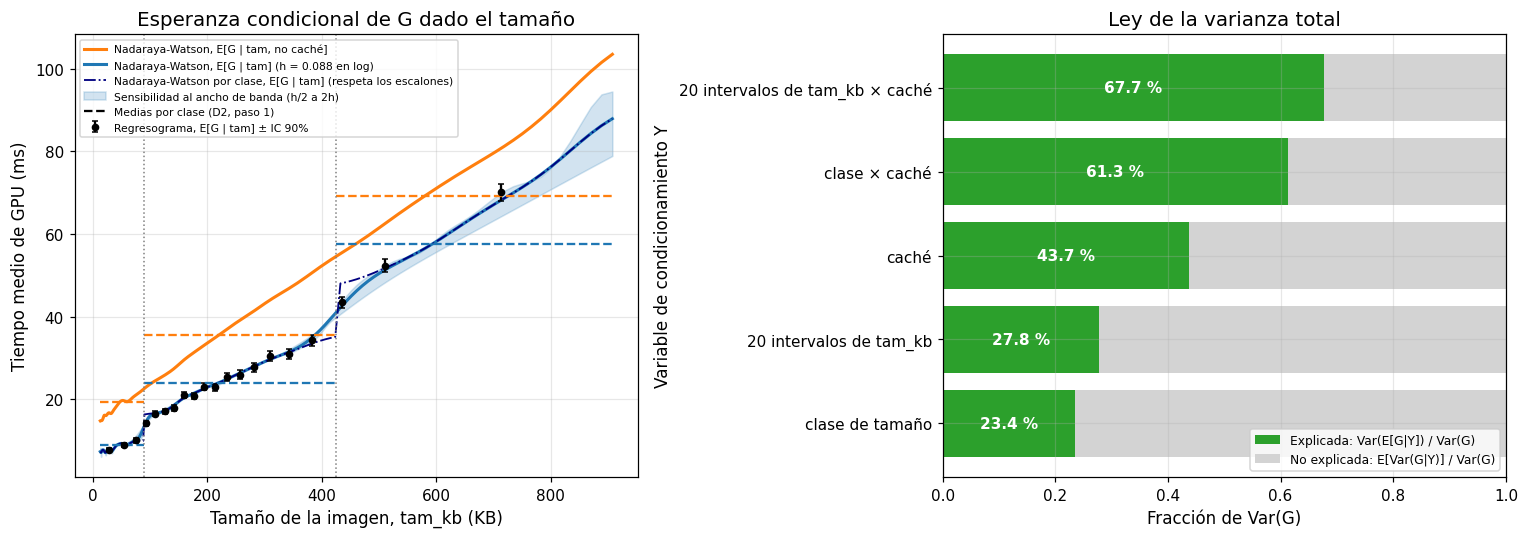

In [ ]:
# Gráfica de apoyo D2 (no es figura numerada del enunciado)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
x_grid = np.exp(u_grid)                                         # de vuelta a KB para graficar
ax[0].plot(x_grid, nw_nc, color="tab:orange", lw=2, label="Nadaraya-Watson, E[G | tam, no caché]")
ax[0].plot(x_grid, nw["h"], color="tab:blue", lw=2, label=f"Nadaraya-Watson, E[G | tam] (h = {h_silv:.3f} en log)")
ax[0].plot(x_grid, nw_clase, color="navy", lw=1.2, linestyle="-.", label="Nadaraya-Watson por clase, E[G | tam] (respeta los escalones)")
ax[0].fill_between(x_grid, np.minimum(nw["h/2"], nw["2h"]), np.maximum(nw["h/2"], nw["2h"]), color="tab:blue", alpha=0.2,
                   label="Sensibilidad al ancho de banda (h/2 a 2h)")
ax[0].errorbar(regres.tam_medio, regres.E_G, yerr=stats.norm.ppf(1 - alpha / 2) * regres.ee, fmt="ko", ms=4, capsize=2,
               label=f"Regresograma, E[G | tam] ± IC {nivel_confianza:.0%}")
limites = {"pequeña": (x_grid.min(), t1_kb), "mediana": (t1_kb, t2_kb), "grande": (t2_kb, x_grid.max())}
for c_, (a_, b_) in limites.items():
    ax[0].hlines(tabla_d2.loc[c_, "E[G | clase]"], a_, b_, colors="tab:blue", linestyles="--", lw=1.5)
    ax[0].hlines(tabla_d2.loc[c_, "E[G | clase, no caché]"], a_, b_, colors="tab:orange", linestyles="--", lw=1.5)
for t_ in (t1_kb, t2_kb):
    ax[0].axvline(t_, color="grey", linestyle=":", lw=1)
ax[0].plot([], [], "k--", lw=1.5, label="Medias por clase (D2, paso 1)")
ax[0].set_xlabel("Tamaño de la imagen, tam_kb (KB)")
ax[0].set_ylabel("Tiempo medio de GPU (ms)")
ax[0].set_title("Esperanza condicional de G dado el tamaño")
ax[0].legend(fontsize=7, loc="upper left")

orden_vt = ["clase de tamaño", "20 intervalos de tam_kb", "caché", "clase × caché", "20 intervalos de tam_kb × caché"]
expl = tabla_vt.loc[orden_vt, "η² = explicada"]
ax[1].barh(orden_vt, expl, color="tab:green", label="Explicada: Var(E[G|Y]) / Var(G)")
ax[1].barh(orden_vt, 1 - expl, left=expl, color="lightgrey", label="No explicada: E[Var(G|Y)] / Var(G)")
for i_, v_ in enumerate(expl):
    ax[1].text(v_ / 2, i_, f"{100 * v_:.1f} %", va="center", ha="center", color="white", fontweight="bold")
ax[1].set_xlim(0, 1)
ax[1].set_xlabel("Fracción de Var(G)")
ax[1].set_ylabel("Variable de condicionamiento Y")
ax[1].set_title("Ley de la varianza total")
ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_D2.png"), bbox_inches="tight")
plt.show()

**Conclusión D2.**
- **$E[G \mid \text{clase}, \text{no caché}]$** (IC 90 %, t de Student): pequeña 19,24 [18,93; 19,55] ms, mediana 35,48 [35,21; 35,74] ms y grande 69,30 [68,28; 70,33] ms. Con las cacheadas incluidas, $E[G \mid \text{clase}]$ = 9,04, 24,07 y 57,62 ms. De pequeña a grande, el tiempo medio de GPU se multiplica por **6,4**, que es el producto de los dos caminos: **× 3,6** porque una imagen grande tarda más en la GPU y **× 1,8** porque casi nunca está en caché.
- **$E[G \mid \text{tam\_kb}]$:** el regresograma y Nadaraya-Watson coinciden (diferencia máxima ≈ 2 ms). En el 90 % central de los tamaños, la curva cambia a lo sumo 3 ms con $h/2$ o $2h$; solo en las colas, con pocos datos, la sensibilidad llega a 9 ms. **Hallazgo:** la curva **salta en $t_1 = 90$ y $t_2 = 425$ KB**. $P(\text{caché})$ cambia en escalón justo en las fronteras (de 0,53 a 0,31 al cruzar 90 KB, z = 14,4; de 0,30 a 0,18 al cruzar 425 KB, z = 5,2) y es prácticamente constante dentro de cada clase (p = 0,76; 0,16; 0,09, la grande en el límite). Es decir, **la caché depende de la clase, no del tamaño fino**, mientras que $E[G \mid \text{tam}, \text{no caché}]$ crece de forma suave y casi lineal (D3). En consecuencia, $E[G \mid \text{tam}] = P(\text{no caché} \mid \text{clase}(\text{tam}))\cdot(\beta_0 + \beta_1\,\text{tam})$.
- **Esperanza total:** $\sum_y P(Y=y)E[G\mid Y=y] = 26{,}0541$ ms $= E[G]$, con diferencias de orden $10^{-15}$ al condicionar en la clase, la caché, ambas o 20 intervalos de tamaño. La curva suavizada promediada da 25,97 ms, aproximada como se esperaba.
- **Varianza total:** $E[\text{Var}(G\mid Y)] + \text{Var}(E[G\mid Y]) = 785{,}39$ ms² $= \text{Var}(G)$ en todos los casos (diferencia ~$10^{-12}$). **La clase de tamaño explica el 23,4 % de Var(G)** (IC 90 % bootstrap [22,5 %; 24,3 %]); entre las no cacheadas, el 31,3 %. Usar el tamaño fino (20 intervalos) solo sube la cifra a 27,8 %, así que las tres clases capturan casi todo lo que aporta el tamaño. La caché sola explica 43,7 % (es la masa en 0 de C1), y clase y caché juntas, 61,3 %. El ≈ 32 % restante es variabilidad propia del cómputo: el ruido multiplicativo con CV ≈ 0,45 que se caracteriza en D3.

### D3. Modelo lineal para E[G | tam_kb, no caché]

**Modelo.** Para las solicitudes **no cacheadas** del régimen estable, con $x_i$ = `tam_kb` e $y_i$ = `gpu_ms`:
$$y_i = \beta_0 + \beta_1 x_i + e_i, \qquad E[e_i \mid x_i] = 0 \quad\Longleftrightarrow\quad E[G \mid \text{tam}, \text{no caché}] = \beta_0 + \beta_1\,\text{tam}.$$
D2 (curva naranja de la gráfica de apoyo) sugiere que esta relación es casi recta. $\beta_1$ son los ms de GPU que agrega cada KB adicional y $\beta_0$ el costo fijo por solicitud.

**Mínimos cuadrados en forma matricial.** Con $\mathbf X = [\mathbf 1 \;\; \mathbf x]$ ($n\times 2$), minimizar $\|\mathbf y - \mathbf X\boldsymbol\beta\|^2$ lleva a las **ecuaciones normales**
$$\mathbf X^\top\mathbf X\,\hat{\boldsymbol\beta} = \mathbf X^\top\mathbf y, \qquad
\mathbf X^\top\mathbf X = \begin{pmatrix} n & \sum x_i \\ \sum x_i & \sum x_i^2\end{pmatrix}, \quad
\mathbf X^\top\mathbf y = \begin{pmatrix}\sum y_i \\ \sum x_i y_i\end{pmatrix}.$$
Es un sistema $2\times 2$ que se resuelve con la inversa explícita, $(\mathbf X^\top\mathbf X)^{-1} = \frac{1}{\det}\begin{pmatrix}\sum x_i^2 & -\sum x_i \\ -\sum x_i & n\end{pmatrix}$, y se comprueba con `np.linalg.solve`.

**Intervalos clásicos.** Suponiendo errores independientes, con **varianza constante** $\sigma^2$ y normales: $\hat\sigma^2 = \text{SCR}/(n-2)$, $\widehat{\text{Cov}}(\hat{\boldsymbol\beta}) = \hat\sigma^2(\mathbf X^\top\mathbf X)^{-1}$ y $\hat\beta_j \pm t_{n-2,\,1-\alpha/2}\,\text{ee}(\hat\beta_j)$. El paso 2 revisa si esos supuestos se cumplen.

In [ ]:
# Paso 1. Mínimos cuadrados ordinarios planteando y resolviendo las ecuaciones normales (sin sklearn ni statsmodels)
d3 = df_estable[df_estable.cache_hit == 0]                      # solo solicitudes que usaron GPU
x_d3 = d3.tam_kb.to_numpy()                                     # variable explicativa: tamaño (KB)
y_d3 = d3.gpu_ms.to_numpy()                                     # respuesta: tiempo de GPU (ms)
n_d3 = len(y_d3)
X_d3 = np.column_stack([np.ones(n_d3), x_d3])                   # matriz de diseño [1, x]

# Ecuaciones normales X'X beta = X'y
XtX = X_d3.T @ X_d3                                             # [[n, sum x], [sum x, sum x^2]]
Xty = X_d3.T @ y_d3                                             # [sum y, sum x·y]
det_XtX = XtX[0, 0] * XtX[1, 1] - XtX[0, 1] * XtX[1, 0]         # determinante del sistema 2x2
XtX_inv = np.array([[XtX[1, 1], -XtX[0, 1]],
                    [-XtX[1, 0], XtX[0, 0]]]) / det_XtX         # inversa explícita de una matriz 2x2
beta_ols = XtX_inv @ Xty                                        # beta = (X'X)^{-1} X'y
print("X'X =\n", np.array2string(XtX, precision=1, suppress_small=True))
print("X'y =", np.array2string(Xty, precision=1))
print(f"det(X'X) = {det_XtX:.4e}")
print(f"beta (inversa explícita)  = {beta_ols}")
print(f"beta (np.linalg.solve)    = {np.linalg.solve(XtX, Xty)}   <- comprobación")
Sxx, Sxy = ((x_d3 - x_d3.mean()) ** 2).sum(), ((x_d3 - x_d3.mean()) * (y_d3 - y_d3.mean())).sum()
print(f"beta1 = Sxy/Sxx = {Sxy / Sxx:.8f} y beta0 = ȳ − beta1·x̄ = {y_d3.mean() - Sxy / Sxx * x_d3.mean():.6f}   <- forma escalar equivalente")

# Varianza residual, errores estándar clásicos e IC t de Student
ajuste_ols = X_d3 @ beta_ols                                    # valores ajustados ŷ
res_ols = y_d3 - ajuste_ols                                     # residuos e = y − ŷ
SCR = (res_ols ** 2).sum()                                      # suma de cuadrados de los residuos
sigma2_ols = SCR / (n_d3 - 2)                                   # estimador insesgado de sigma^2 (2 parámetros)
cov_ols = sigma2_ols * XtX_inv                                  # Cov(beta) clásica = sigma^2 (X'X)^{-1}
ee_ols = np.sqrt(np.diag(cov_ols))
t_d3 = stats.t.ppf(1 - alpha / 2, n_d3 - 2)
z_d3 = stats.norm.ppf(1 - alpha / 2)
R2_d3 = 1 - SCR / ((y_d3 - y_d3.mean()) ** 2).sum()
print(f"\nn = {n_d3} | sigma estimada = {np.sqrt(sigma2_ols):.3f} ms | R² = {R2_d3:.4f}")
for j_, nom in enumerate(["beta0 (ms)", "beta1 (ms/KB)"]):
    print(f"{nom:14s}:", formatear_intervalo(beta_ols[j_], beta_ols[j_] - t_d3 * ee_ols[j_], beta_ols[j_] + t_d3 * ee_ols[j_],
                                            "MCO clásico, t de Student", 5))
print(f"Lectura: cada 100 KB adicionales agregan {100 * beta_ols[1]:.2f} ms de GPU; el costo fijo por solicitud es ≈ {beta_ols[0]:.1f} ms")

X'X =
 [[1.9e+04 4.9e+06]
 [4.9e+06 1.9e+09]]
X'y = [7.3e+05 2.5e+08]
det(X'X) = 1.0982e+13
beta (inversa explícita)  = [13.67274854  0.0975999 ]
beta (np.linalg.solve)    = [13.67274854  0.0975999 ]   <- comprobación
beta1 = Sxy/Sxx = 0.09759990 y beta0 = ȳ − beta1·x̄ = 13.672749   <- forma escalar equivalente

n = 18704 | sigma estimada = 19.150 ms | R² = 0.4492
beta0 (ms)    : 13.67275  [13.26174, 14.08375]  (IC 90%, método: MCO clásico, t de Student)
beta1 (ms/KB) : 0.09760  [0.09630, 0.09890]  (IC 90%, método: MCO clásico, t de Student)
Lectura: cada 100 KB adicionales agregan 9.76 ms de GPU; el costo fijo por solicitud es ≈ 13.7 ms


**Paso 2. Análisis de residuos.** Se revisa cada supuesto con evidencia cuantitativa:
1. **Linealidad:** se agrega un término $x^2$ y se mide si es significativo y, sobre todo, si cambia algo en la práctica. También se comparan las medias por intervalo de tamaño ($E[G \mid \text{tam}, \text{no caché}]$ no paramétrica, D2) con la recta.
2. **Varianza constante (homocedasticidad):** desviación estándar de los residuos por deciles del valor ajustado y **prueba de Breusch-Pagan**, programada por el grupo: se regresa $e_i^2$ sobre $x_i$, y bajo homocedasticidad $LM = n R^2_{\text{aux}} \sim \chi^2_1$.
3. **Normalidad** de los residuos: asimetría y curtosis.
4. **Independencia:** autocorrelación de los residuos en orden de llegada, dentro de cada tramo.
5. **Variable omitida:** A3 mostró que la versión B usa ≈ 6 % menos GPU. Como la versión se asignó al azar, no debería estar correlacionada con el tamaño ni sesgar $\hat\beta_1$; se comprueba agregándola al modelo.

In [ ]:
# Paso 2. Análisis de residuos del modelo MCO
# 1. Linealidad: término cuadrático (sistema 3x3) y comparación con las medias por intervalo
X2_d3 = np.column_stack([X_d3, x_d3 ** 2])
beta_q = np.linalg.solve(X2_d3.T @ X2_d3, X2_d3.T @ y_d3)
s2_q = ((y_d3 - X2_d3 @ beta_q) ** 2).sum() / (n_d3 - 3)
ee_q = np.sqrt(s2_q * np.linalg.inv(X2_d3.T @ X2_d3)[2, 2])
x_rango = np.quantile(x_d3, [0.01, 0.99])
dif_q = np.abs(np.polyval(beta_q[::-1], x_rango) - (beta_ols[0] + beta_ols[1] * x_rango)).max()
print(f"1. Linealidad: coef. de x² = {beta_q[2]:.2e} (t = {beta_q[2] / ee_q:.2f}, p = {2 * stats.t.sf(abs(beta_q[2] / ee_q), n_d3 - 3):.3f}); "
      f"entre los percentiles 1 y 99 de tam_kb la curva cuadrática se aparta de la recta a lo sumo {dif_q:.2f} ms")
dec_d3 = pd.qcut(x_d3, 10, labels=False)                        # deciles de tamaño
med_dec = pd.DataFrame({"x": x_d3, "y": y_d3, "dec": dec_d3}).groupby("dec").agg(x=("x", "mean"), y=("y", "mean"), s=("y", "std"), n=("y", "size"))
med_dec["recta"] = beta_ols[0] + beta_ols[1] * med_dec.x
med_dec["z (media − recta)"] = (med_dec.y - med_dec.recta) / (med_dec.s / np.sqrt(med_dec.n))
print(f"   Medias por decil de tamaño frente a la recta: máx |media − recta| = {np.abs(med_dec.y - med_dec.recta).max():.2f} ms, "
      f"máx |z| = {med_dec['z (media − recta)'].abs().max():.2f}")

# 2. Homocedasticidad: dispersión de los residuos por deciles del valor ajustado + Breusch-Pagan (programada)
dec_aj = pd.qcut(ajuste_ols, 10, labels=False)
disp = pd.DataFrame({"ajustado": ajuste_ols, "res": res_ols, "y": y_d3}).groupby(dec_aj).agg(
    ajustado_medio=("ajustado", "mean"), sd_residuo=("res", "std"))
disp["sd / ajustado (CV)"] = disp.sd_residuo / disp.ajustado_medio
print("\n2. Homocedasticidad: dispersión de los residuos por deciles del valor ajustado")
print(disp.round(3).T.to_string())
pend_log = np.polyfit(np.log(disp.ajustado_medio), np.log(disp.sd_residuo), 1)[0]
print(f"   Pendiente de log(sd) contra log(ajustado) = {pend_log:.3f}  (0 = varianza constante; 1 = sd proporcional a la media)")
e2 = res_ols ** 2
g_aux = XtX_inv @ (X_d3.T @ e2)                                 # regresión auxiliar e^2 ~ 1 + x (mismo sistema normal)
R2_aux = 1 - ((e2 - X_d3 @ g_aux) ** 2).sum() / ((e2 - e2.mean()) ** 2).sum()
LM_bp = n_d3 * R2_aux
print(f"   Breusch-Pagan: LM = n·R²_aux = {LM_bp:.1f}, gl = 1, p = {stats.chi2.sf(LM_bp, 1):.1e} "
      f"-> {'se rechaza' if stats.chi2.sf(LM_bp, 1) < alpha else 'no se rechaza'} la varianza constante")

# 3. Normalidad de los residuos
print(f"\n3. Normalidad: asimetría de los residuos = {stats.skew(res_ols):.3f}, curtosis en exceso = {stats.kurtosis(res_ols):.3f} "
      f"(D'Agostino-Pearson p = {stats.normaltest(res_ols).pvalue:.1e})")

# 4. Independencia: residuos en orden de llegada, dentro de cada tramo del régimen estable
orden = np.argsort(d3.t_llegada_s.to_numpy())
t_ord, r_ord = d3.t_llegada_s.to_numpy()[orden], res_ols[orden]
mismo_tramo = (t_ord[:-1] < INI) == (t_ord[1:] < INI)           # pares consecutivos que no cruzan la ráfaga
rho_d3 = np.corrcoef(r_ord[:-1][mismo_tramo], r_ord[1:][mismo_tramo])[0, 1]
print(f"\n4. Independencia: autocorrelación de orden 1 de los residuos = {rho_d3:.4f} "
      f"(p = {2 * stats.norm.sf(abs(rho_d3) * np.sqrt(mismo_tramo.sum())):.3f})")

# 5. Variable omitida: versión
es_B_d3 = (d3.version == "B").to_numpy(dtype=float)
X3_d3 = np.column_stack([X_d3, es_B_d3])
beta_v = np.linalg.solve(X3_d3.T @ X3_d3, X3_d3.T @ y_d3)
print(f"\n5. Con la versión en el modelo: beta1 = {beta_v[1]:.5f} (sin ella {beta_ols[1]:.5f}); efecto de B = {beta_v[2]:.2f} ms | "
      f"correlación tam_kb–versión = {np.corrcoef(x_d3, es_B_d3)[0, 1]:.4f} -> la versión no sesga la pendiente")

1. Linealidad: coef. de x² = 3.39e-06 (t = 1.31, p = 0.191); entre los percentiles 1 y 99 de tam_kb la curva cuadrática se aparta de la recta a lo sumo 0.53 ms
   Medias por decil de tamaño frente a la recta: máx |media − recta| = 0.68 ms, máx |z| = 1.31

2. Homocedasticidad: dispersión de los residuos por deciles del valor ajustado
                         0       1       2       3       4       5       6       7       8       9
ajustado_medio      18.703  23.445  26.593  29.799  33.231  37.174  41.833  47.889  56.822  76.799
sd_residuo           8.368  10.509  11.668  13.476  15.051  17.049  18.737  21.473  25.459  34.522
sd / ajustado (CV)   0.447   0.448   0.439   0.452   0.453   0.459   0.448   0.448   0.448   0.450
   Pendiente de log(sd) contra log(ajustado) = 1.005  (0 = varianza constante; 1 = sd proporcional a la media)
   Breusch-Pagan: LM = n·R²_aux = 2253.7, gl = 1, p = 0.0e+00 -> se rechaza la varianza constante

3. Normalidad: asimetría de los residuos = 1.202, curtosis 

**Paso 3. Corrección fundamentada en la estructura probabilística.** El paso 2 muestra que el problema es la **heterocedasticidad**, y con una forma muy precisa: la desviación estándar de $G$ crece **en proporción a su media**. El coeficiente de variación es constante, y C2 ya había encontrado que $G$ es aproximadamente lognormal. Eso corresponde a un modelo **multiplicativo**:
$$G = \mu(x)\cdot\varepsilon, \qquad \mu(x) = \beta_0 + \beta_1 x, \qquad E[\varepsilon] = 1,\; \text{Var}(\varepsilon) = \phi \;\;\Longrightarrow\;\; \text{Var}(G \mid x) = \phi\,\mu(x)^2.$$
Las imágenes grandes tienen tiempos de GPU más largos **y** más variables, porque el tiempo de cómputo escala de forma proporcional.

**Consecuencias para MCO.** $\hat\beta$ sigue siendo **insesgado**, porque la media sí es lineal. Pero (i) los errores estándar clásicos $\hat\sigma^2(\mathbf X^\top\mathbf X)^{-1}$ están **mal calculados**, ya que suponen la misma varianza para todos, y (ii) MCO **no es eficiente**, porque da igual peso a las observaciones grandes, que son muy ruidosas.

**Corrección: mínimos cuadrados ponderados (MCP) con pesos $w_i = 1/\mu(x_i)^2$**, el inverso de la varianza que predice la estructura. Como $\mu$ es desconocida, se itera: se parte de MCO, se calculan los pesos con el ajuste actual y se vuelve a resolver $\mathbf X^\top\mathbf W\mathbf X\,\boldsymbol\beta = \mathbf X^\top\mathbf W\mathbf y$ hasta que converge. Es el estimador de **cuasi-verosimilitud** para varianza proporcional a la media al cuadrado (familia gamma). Su covarianza es $\hat\phi(\mathbf X^\top\mathbf W\mathbf X)^{-1}$, con $\hat\phi = \frac{1}{n-2}\sum_i w_i e_i^2$.

**Alternativa de comparación:** mantener MCO pero con errores estándar **robustos (sándwich HC3)**, $(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\text{diag}\!\left(\frac{e_i^2}{(1-h_{ii})^2}\right)\mathbf X(\mathbf X^\top\mathbf X)^{-1}$. Arregla los errores estándar sin suponer la forma de la varianza, pero no recupera la eficiencia.

In [ ]:
# Paso 3. Corrección: MCP iterado con pesos 1/mu(x)^2 (estructura multiplicativa) y, como comparación, MCO con errores robustos HC3
def mcp_multiplicativo(X, y, beta_ini, iter_max=50, tol=1e-10):
    # MCP iterado: pesos w = 1/ajuste^2 (Var(y|x) proporcional a la media^2). Devuelve (beta, cov, phi, iteraciones)
    beta = beta_ini.copy()
    for it in range(1, iter_max + 1):
        mu = X @ beta                                           # media ajustada con los coeficientes actuales
        w = 1 / mu**2                                           # peso = 1 / varianza relativa
        XtWX = X.T @ (X * w[:, None])                           # X' W X
        beta_nuevo = np.linalg.solve(XtWX, X.T @ (w * y))       # ecuaciones normales ponderadas
        if np.max(np.abs(beta_nuevo - beta)) < tol:
            beta = beta_nuevo
            break
        beta = beta_nuevo
    mu = X @ beta; w = 1 / mu**2
    phi = (w * (y - mu) ** 2).sum() / (len(y) - X.shape[1])     # dispersión: CV^2 de epsilon
    cov = phi * np.linalg.inv(X.T @ (X * w[:, None]))
    return beta, cov, phi, it


def ee_hc3(X, e, XtX_inv_):
    # Errores estándar robustos HC3 (sándwich) para MCO
    h = np.einsum("ij,jk,ik->i", X, XtX_inv_, X)                # apalancamientos h_ii = x_i' (X'X)^{-1} x_i
    carne = X.T @ (X * (e / (1 - h))[:, None] ** 2)             # X' diag(e^2/(1-h)^2) X
    return np.sqrt(np.diag(XtX_inv_ @ carne @ XtX_inv_))


beta_mcp, cov_mcp, phi_mcp, it_mcp = mcp_multiplicativo(X_d3, y_d3, beta_ols)
ee_mcp = np.sqrt(np.diag(cov_mcp))
ee_rob = ee_hc3(X_d3, res_ols, XtX_inv)
print(f"MCP convergió en {it_mcp} iteraciones | phi estimado = {phi_mcp:.4f} -> CV de epsilon = {np.sqrt(phi_mcp):.3f} "
      f"(el CV por deciles del paso 2 era ≈ {disp['sd / ajustado (CV)'].median():.3f})\n")

filas_d3 = []
for metodo, b_, ee_ in [("MCO, ee clásico", beta_ols, ee_ols), ("MCO, ee robusto HC3", beta_ols, ee_rob),
                        ("MCP multiplicativo", beta_mcp, ee_mcp)]:
    for j_, nom in enumerate(["beta0 (ms)", "beta1 (ms/KB)"]):
        filas_d3.append({"método": metodo, "coeficiente": nom, "estimación": b_[j_], "ee": ee_[j_],
                         "IC inf": b_[j_] - t_d3 * ee_[j_], "IC sup": b_[j_] + t_d3 * ee_[j_]})
tabla_d3 = pd.DataFrame(filas_d3).set_index(["coeficiente", "método"]).sort_index()
print(f"Intervalos al {nivel_confianza:.0%} (t de Student, n − 2 gl):")
print(tabla_d3.to_string(float_format=lambda v: f"{v:.5f}"))
for j_, nom in enumerate(["beta0", "beta1"]):
    print(f"{nom}: el ee clásico es {ee_ols[j_] / ee_rob[j_]:.2f} veces el robusto; el ee de MCP es {ee_mcp[j_] / ee_rob[j_]:.2f} veces el robusto de MCO")
tabla_d3.round(6).to_csv("D3_coeficientes.csv")

# Con la corrección, los residuos de Pearson (y − mu)/mu deben tener dispersión constante
pearson = (y_d3 - X_d3 @ beta_mcp) / (X_d3 @ beta_mcp)
sd_pearson = pd.Series(pearson).groupby(pd.qcut(X_d3 @ beta_mcp, 10, labels=False)).std()
print(f"\nResiduos de Pearson de MCP por deciles del ajuste: sd entre {sd_pearson.min():.3f} y {sd_pearson.max():.3f} (constante, como se esperaba)")

MCP convergió en 5 iteraciones | phi estimado = 0.2008 -> CV de epsilon = 0.448 (el CV por deciles del paso 2 era ≈ 0.448)

Intervalos al 90% (t de Student, n − 2 gl):
                                   estimación      ee   IC inf   IC sup
coeficiente   método                                                   
beta0 (ms)    MCO, ee clásico        13.67275 0.24986 13.26174 14.08375
              MCO, ee robusto HC3    13.67275 0.28234 13.20831 14.13718
              MCP multiplicativo     13.77460 0.16842 13.49756 14.05165
beta1 (ms/KB) MCO, ee clásico         0.09760 0.00079  0.09630  0.09890
              MCO, ee robusto HC3     0.09760 0.00129  0.09548  0.09972
              MCP multiplicativo      0.09719 0.00087  0.09576  0.09862
beta0: el ee clásico es 0.88 veces el robusto; el ee de MCP es 0.60 veces el robusto de MCO
beta1: el ee clásico es 0.61 veces el robusto; el ee de MCP es 0.67 veces el robusto de MCO

Residuos de Pearson de MCP por deciles del ajuste: sd entre 0.438 y 0.4

**Paso 4. Verificación por simulación: ¿la corrección importa?** Se generan $R = 1000$ muestras **con la estructura detectada en los datos**: se conservan los tamaños observados, la media es la recta de MCP y el ruido multiplicativo $\varepsilon$ se remuestrea de los cocientes observados $y_i/\hat\mu(x_i)$ (así se respetan su forma asimétrica y su CV). En cada muestra se ajustan los tres métodos y se mide (i) la **cobertura efectiva** de los intervalos al nivel del grupo para la pendiente y el intercepto verdaderos y (ii) la **variabilidad** de cada estimador (eficiencia).

In [ ]:
# Paso 4. Montecarlo: cobertura y eficiencia de MCO clásico, MCO robusto y MCP bajo la estructura multiplicativa
R_D3 = 1000
mu_verdadera = X_d3 @ beta_mcp                                  # media "verdadera" de la simulación (recta de MCP)
eps_obs = y_d3 / mu_verdadera                                   # ruido multiplicativo observado
eps_obs = eps_obs / eps_obs.mean()                              # se normaliza a media 1 exacta
cubre_d3 = {m_: np.zeros(2) for m_ in ["MCO, ee clásico", "MCO, ee robusto HC3", "MCP multiplicativo"]}
est_d3 = {"MCO": np.empty((R_D3, 2)), "MCP": np.empty((R_D3, 2))}
for r_ in range(R_D3):
    y_s = mu_verdadera * rng.choice(eps_obs, n_d3)              # muestra simulada con la estructura de los datos
    b_o = XtX_inv @ (X_d3.T @ y_s)                              # MCO (misma X, misma inversa)
    e_o = y_s - X_d3 @ b_o
    ee_c = np.sqrt(np.diag((e_o ** 2).sum() / (n_d3 - 2) * XtX_inv))
    ee_r = ee_hc3(X_d3, e_o, XtX_inv)
    b_w, cov_w, _, _ = mcp_multiplicativo(X_d3, y_s, b_o)
    ee_w = np.sqrt(np.diag(cov_w))
    for m_, b_, ee_ in [("MCO, ee clásico", b_o, ee_c), ("MCO, ee robusto HC3", b_o, ee_r), ("MCP multiplicativo", b_w, ee_w)]:
        cubre_d3[m_] += np.abs(b_ - beta_mcp) <= t_d3 * ee_
    est_d3["MCO"][r_], est_d3["MCP"][r_] = b_o, b_w

ee_mc_d3 = np.sqrt(nivel_confianza * (1 - nivel_confianza) / R_D3)
print(f"Cobertura efectiva (nominal {nivel_confianza:.0%}, {R_D3} réplicas, error de Montecarlo ≈ ±{z_d3 * ee_mc_d3:.3f}):")
print(pd.DataFrame({m_: v_ / R_D3 for m_, v_ in cubre_d3.items()}, index=["beta0", "beta1"]).T.round(3).to_string())
sd_o, sd_w = est_d3["MCO"].std(axis=0, ddof=1), est_d3["MCP"].std(axis=0, ddof=1)
print(f"\nDesviación estándar de los estimadores en la simulación: beta0 MCO {sd_o[0]:.4f} vs MCP {sd_w[0]:.4f}; "
      f"beta1 MCO {sd_o[1]:.6f} vs MCP {sd_w[1]:.6f}")
print(f"Eficiencia relativa Var(MCO)/Var(MCP): beta0 = {(sd_o[0] / sd_w[0]) ** 2:.2f}, beta1 = {(sd_o[1] / sd_w[1]) ** 2:.2f} "
      f"(>1: MCP es más preciso; equivale a tener ese factor más de datos)")
print(f"Sesgo medio: MCO {est_d3['MCO'].mean(axis=0) - beta_mcp} | MCP {est_d3['MCP'].mean(axis=0) - beta_mcp}  (ambos ≈ 0: insesgados)")

Cobertura efectiva (nominal 90%, 1000 réplicas, error de Montecarlo ≈ ±0.016):
                     beta0  beta1
MCO, ee clásico      0.835  0.683
MCO, ee robusto HC3  0.890  0.885
MCP multiplicativo   0.900  0.900

Desviación estándar de los estimadores en la simulación: beta0 MCO 0.2929 vs MCP 0.1687; beta1 MCO 0.001334 vs MCP 0.000863
Eficiencia relativa Var(MCO)/Var(MCP): beta0 = 3.02, beta1 = 2.39 (>1: MCP es más preciso; equivale a tener ese factor más de datos)
Sesgo medio: MCO [ 3.74352781e-03 -3.53773387e-05] | MCP [ 1.58362414e-03 -2.72397745e-05]  (ambos ≈ 0: insesgados)


### Figura 5
Izquierda: datos (una muestra de 3000 puntos), rectas de MCO y MCP y medias por decil de tamaño. Centro: residuos de MCO contra el valor ajustado; la banda de ±2 desviaciones estándar por decil se abre en forma de **embudo** (heterocedasticidad). Derecha: residuos de Pearson del modelo corregido, $(y - \hat\mu)/\hat\mu$, con dispersión constante.

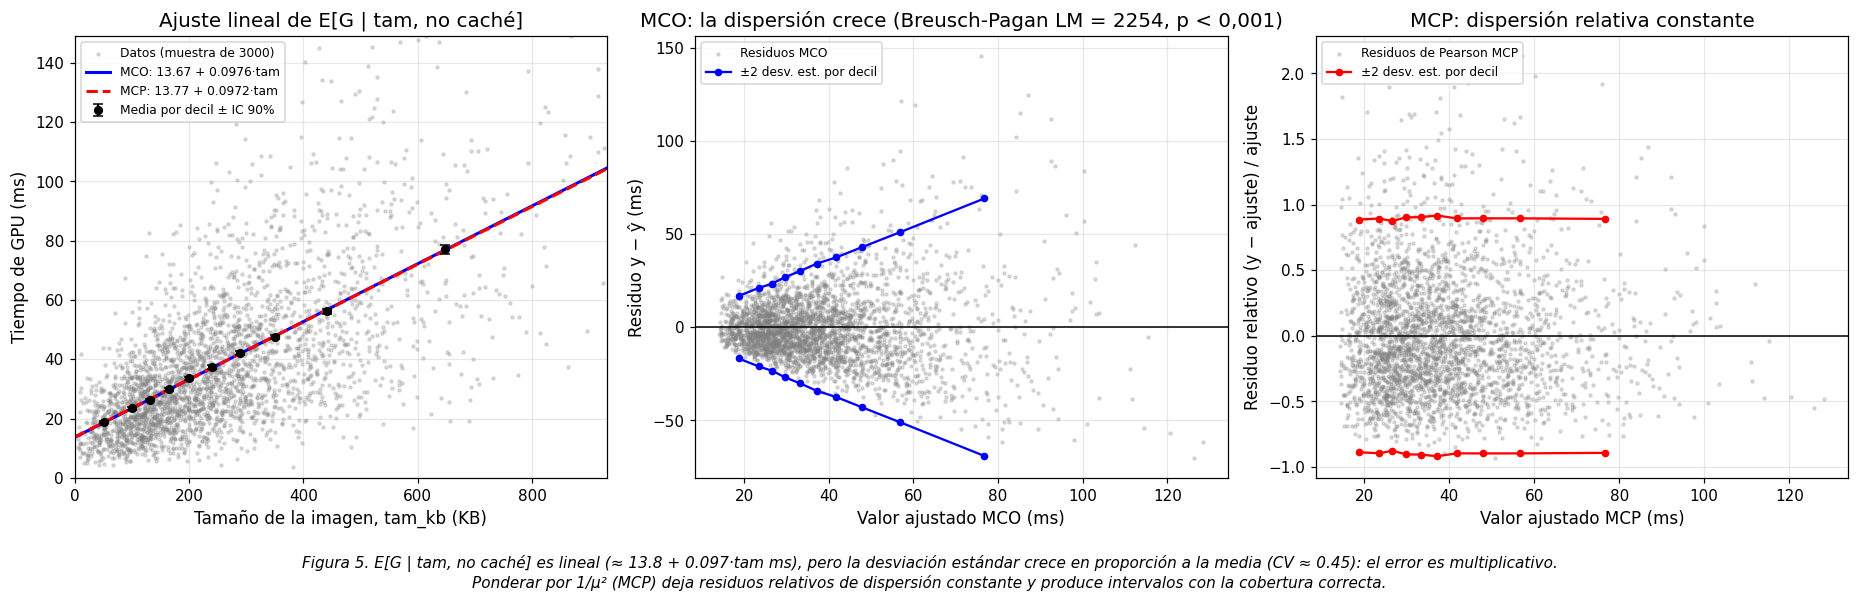

In [ ]:
# Figura 5. Modelo lineal de E[G | tam_kb, no caché]: ajuste, heterocedasticidad y corrección
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
muestra = rng.choice(n_d3, 3000, replace=False)                 # submuestra solo para que el gráfico sea legible
xs_d3 = np.linspace(0, np.quantile(x_d3, 0.995), 100)

ax[0].scatter(x_d3[muestra], y_d3[muestra], s=4, alpha=0.25, color="grey", label="Datos (muestra de 3000)")
ax[0].plot(xs_d3, beta_ols[0] + beta_ols[1] * xs_d3, "b-", lw=2, label=f"MCO: {beta_ols[0]:.2f} + {beta_ols[1]:.4f}·tam")
ax[0].plot(xs_d3, beta_mcp[0] + beta_mcp[1] * xs_d3, "r--", lw=2, label=f"MCP: {beta_mcp[0]:.2f} + {beta_mcp[1]:.4f}·tam")
ax[0].errorbar(med_dec.x, med_dec.y, yerr=z_d3 * med_dec.s / np.sqrt(med_dec.n), fmt="ko", ms=5, capsize=3,
               label=f"Media por decil ± IC {nivel_confianza:.0%}")
ax[0].set_xlim(0, xs_d3.max()); ax[0].set_ylim(0, np.quantile(y_d3, 0.995))
ax[0].set_xlabel("Tamaño de la imagen, tam_kb (KB)")
ax[0].set_ylabel("Tiempo de GPU (ms)")
ax[0].set_title("Ajuste lineal de E[G | tam, no caché]")
ax[0].legend(fontsize=8, loc="upper left")

banda = pd.DataFrame({"a": ajuste_ols, "e": res_ols}).groupby(dec_aj).agg(a=("a", "mean"), s=("e", "std"))
ax[1].scatter(ajuste_ols[muestra], res_ols[muestra], s=4, alpha=0.25, color="grey", label="Residuos MCO")
ax[1].plot(banda.a, 2 * banda.s, "b-o", ms=4, label="±2 desv. est. por decil")
ax[1].plot(banda.a, -2 * banda.s, "b-o", ms=4)
ax[1].axhline(0, color="black", lw=1)
ax[1].set_xlabel("Valor ajustado MCO (ms)")
ax[1].set_ylabel("Residuo y − ŷ (ms)")
ax[1].set_title(f"MCO: la dispersión crece (Breusch-Pagan LM = {LM_bp:.0f}, p < 0,001)")
ax[1].legend(fontsize=8, loc="upper left")

aj_mcp = X_d3 @ beta_mcp
dec_mcp = pd.qcut(aj_mcp, 10, labels=False)
banda_p = pd.DataFrame({"a": aj_mcp, "e": pearson}).groupby(dec_mcp).agg(a=("a", "mean"), s=("e", "std"))
ax[2].scatter(aj_mcp[muestra], pearson[muestra], s=4, alpha=0.25, color="grey", label="Residuos de Pearson MCP")
ax[2].plot(banda_p.a, 2 * banda_p.s, "r-o", ms=4, label="±2 desv. est. por decil")
ax[2].plot(banda_p.a, -2 * banda_p.s, "r-o", ms=4)
ax[2].axhline(0, color="black", lw=1)
ax[2].set_xlabel("Valor ajustado MCP (ms)")
ax[2].set_ylabel("Residuo relativo (y − ajuste) / ajuste")
ax[2].set_title("MCP: dispersión relativa constante")
ax[2].legend(fontsize=8, loc="upper left")

pie_de_figura(fig, 5, f"E[G | tam, no caché] es lineal (≈ {beta_mcp[0]:.1f} + {beta_mcp[1]:.3f}·tam ms), pero la desviación estándar crece en proporción a la media "
                      f"(CV ≈ {np.sqrt(phi_mcp):.2f}): el error es multiplicativo.\nPonderar por 1/μ² (MCP) deja residuos relativos de dispersión constante "
                      f"y produce intervalos con la cobertura correcta.")
plt.tight_layout()
guardar_figura(fig, 5)
plt.show()

**Conclusión D3.**
- **Modelo ajustado** (resolviendo las ecuaciones normales a mano): $\hat E[G \mid \text{tam}, \text{no caché}] = 13{,}67 + 0{,}0976\cdot\text{tam}$ ms, $R^2 = 0{,}45$. Cada 100 KB agregan ≈ 9,8 ms de GPU, sobre un costo fijo de ≈ 13,7 ms por solicitud.
- **Supuestos que se cumplen:** la media **sí es lineal** (el término cuadrático no es significativo, p = 0,19, y movería la curva a lo sumo 0,5 ms; las medias por decil están a menos de 0,7 ms de la recta). Los residuos son **independientes** (autocorrelación 0,002, p = 0,84). La versión, asignada al azar, **no sesga la pendiente** (0,09760 frente a 0,09759).
- **Supuesto violado: varianza constante.** La desviación estándar de los residuos crece de 8 a 35 ms a lo largo de los deciles, con **CV constante ≈ 0,45** (pendiente log-log = 1,005) y Breusch-Pagan LM = 2254 (p < 0,001). Los residuos tampoco son normales (asimetría 1,2), consecuencia del mismo ruido multiplicativo y asimétrico de C2.
- **Corrección fundamentada:** la estructura es **multiplicativa**, $G = \mu(\text{tam})\cdot\varepsilon$ con CV de $\varepsilon$ constante, así que $\text{Var}(G\mid\text{tam}) \propto \mu^2$ y los pesos óptimos son $1/\mu^2$. MCP iterado: $13{,}77 + 0{,}0972\cdot\text{tam}$, con IC 90 % [13,50; 14,05] y [0,0958; 0,0986]. Los residuos relativos quedan con dispersión constante (0,44–0,46 en todos los deciles).
- **La corrección importa, y no solo en teoría.** En 1000 réplicas simuladas con la estructura de los datos, el IC clásico de MCO para la pendiente cubre solo el **68 %** (nominal 90 %), porque su error estándar es 0,61 veces el correcto. Los errores robustos HC3 arreglan la cobertura (88–89 %), pero MCP además es **2,4 a 3 veces más eficiente** y cubre el **90 %** exacto. Ambos estimadores son insesgados: lo que estaba mal era la incertidumbre, no la recta.
- **Para la Parte G:** el tiempo de GPU de una solicitud no cacheada se puede simular como $(13{,}77 + 0{,}0972\cdot\text{tam})\cdot\varepsilon$, con $\varepsilon$ remuestreado de los cocientes observados. Eso conserva la dependencia con el tamaño que C2 señaló como limitación del modelo marginal.

### D4. Covarianza y correlación entre tam_kb y gpu_ms (no cacheadas)

**Qué se pide.** Para las solicitudes **no cacheadas** del régimen estable (las mismas de D3), con $X$ = `tam_kb` e $Y$ = `gpu_ms`:
$$\text{Cov}(X, Y) = E\big[(X - E[X])(Y - E[Y])\big], \qquad \rho = \frac{\text{Cov}(X, Y)}{\sigma_X\,\sigma_Y} \in [-1, 1].$$
Se estiman con $\widehat{\text{Cov}} = \frac{1}{n-1}\sum_i (x_i - \bar x)(y_i - \bar y)$ y $r = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i (x_i-\bar x)^2\sum_i (y_i-\bar y)^2}}$.

**Cómo leerlas.** La covarianza tiene unidades (KB·ms) y depende de la escala, así que solo su **signo** es directamente interpretable. La correlación no tiene unidades y mide **cuán bien una recta** resume la relación. $\rho = 0$ no implica independencia: solo dice que no hay asociación *lineal*.

**Intervalo para $\rho$.** El método clásico es la **transformación de Fisher**, $z = \operatorname{arctanh}(r)$, aproximadamente $N\big(\operatorname{arctanh}\rho,\ 1/(n-3)\big)$. Pero esa varianza **supone que $(X, Y)$ es normal bivariada**, y aquí no lo es: `tam_kb` y `gpu_ms` son asimétricas, y D3 mostró que la dispersión de $Y$ crece con $X$. Por eso se calcula también un **IC bootstrap** (remuestreo de pares), que no supone normalidad, y el paso 4 verifica por simulación cuál de los dos cubre bien.

In [ ]:
# Paso 1. Covarianza y correlación entre tam_kb y gpu_ms (no cacheadas), calculadas con la definición
# x_d3, y_d3, n_d3 vienen de D3: tamaño (KB) y tiempo de GPU (ms) de las solicitudes que usaron GPU
x_c, y_c = x_d3 - x_d3.mean(), y_d3 - y_d3.mean()               # datos centrados: x_i − x̄, y_i − ȳ
cov_xy = (x_c * y_c).sum() / (n_d3 - 1)                         # covarianza muestral (divisor n − 1)
sd_x, sd_y = x_d3.std(ddof=1), y_d3.std(ddof=1)                 # desviaciones estándar muestrales
r_xy = cov_xy / (sd_x * sd_y)                                   # correlación de Pearson = cov / (sx · sy)

print(f"n = {n_d3} solicitudes no cacheadas")
print(f"Cov(tam_kb, gpu_ms) = {cov_xy:.2f} KB·ms   (np.cov da {np.cov(x_d3, y_d3)[0, 1]:.2f})")   # comprobación con numpy
print(f"desv. est.: tam_kb = {sd_x:.2f} KB, gpu_ms = {sd_y:.2f} ms")
print(f"Correlación r = {r_xy:.4f}   (np.corrcoef da {np.corrcoef(x_d3, y_d3)[0, 1]:.4f})")      # comprobación con numpy

# --- IC de rho por la transformación de Fisher (supone normalidad bivariada) ---
z_d4 = stats.norm.ppf(1 - alpha / 2)                            # cuantil normal al nivel del grupo
z_fisher = np.arctanh(r_xy)                                     # z = arctanh(r) = 0,5·ln((1 + r)/(1 − r))
ee_fisher = 1 / np.sqrt(n_d3 - 3)                               # error estándar de z bajo normalidad bivariada
r_fi_li, r_fi_ls = np.tanh(z_fisher - z_d4 * ee_fisher), np.tanh(z_fisher + z_d4 * ee_fisher)   # se vuelve a la escala de r

# --- IC de rho y de la covarianza por bootstrap de pares (no supone normalidad) ---
B_D4 = 2000
r_boot, cov_boot = np.empty(B_D4), np.empty(B_D4)
for b in range(B_D4):
    idx = rng.integers(0, n_d3, n_d3)                           # se remuestrean SOLICITUDES: cada par (x_i, y_i) se mantiene junto
    r_boot[b] = np.corrcoef(x_d3[idx], y_d3[idx])[0, 1]
    cov_boot[b] = np.cov(x_d3[idx], y_d3[idx])[0, 1]
r_bt_li, r_bt_ls = np.quantile(r_boot, [alpha / 2, 1 - alpha / 2])
cov_bt_li, cov_bt_ls = np.quantile(cov_boot, [alpha / 2, 1 - alpha / 2])

print("\nCov(tam_kb, gpu_ms):", formatear_intervalo(cov_xy, cov_bt_li, cov_bt_ls, f"bootstrap de pares, {B_D4} réplicas", 1))
print("rho:", formatear_intervalo(r_xy, r_fi_li, r_fi_ls, "transformación de Fisher (supone normal bivariada)", 4))
print("rho:", formatear_intervalo(r_xy, r_bt_li, r_bt_ls, f"bootstrap de pares, {B_D4} réplicas", 4))
print(f"Ancho del IC: Fisher {r_fi_ls - r_fi_li:.4f} vs bootstrap {r_bt_ls - r_bt_li:.4f} "
      f"-> el bootstrap es {(r_bt_ls - r_bt_li) / (r_fi_ls - r_fi_li):.2f} veces más ancho")

# --- Medidas de asociación complementarias ---
rho_s = stats.spearmanr(x_d3, y_d3).statistic                   # Spearman: correlación de los rangos (cualquier relación monótona)
r_log = np.corrcoef(np.log(x_d3), np.log(y_d3))[0, 1]           # Pearson en escala logarítmica
r_todas = np.corrcoef(df_estable.tam_kb, df_estable.gpu_ms)[0, 1]   # con TODAS las solicitudes (cacheadas con G = 0)
print(f"\nSpearman (rangos) = {rho_s:.4f} | Pearson de log(tam) y log(G) = {r_log:.4f} | "
      f"Pearson con todas las solicitudes (incluye G = 0) = {r_todas:.4f}")

n = 18704 solicitudes no cacheadas
Cov(tam_kb, gpu_ms) = 3063.98 KB·ms   (np.cov da 3063.98)
desv. est.: tam_kb = 177.18 KB, gpu_ms = 25.80 ms
Correlación r = 0.6702   (np.corrcoef da 0.6702)

Cov(tam_kb, gpu_ms): 3064.0  [2959.1, 3172.9]  (IC 90%, método: bootstrap de pares, 2000 réplicas)
rho: 0.6702  [0.6635, 0.6768]  (IC 90%, método: transformación de Fisher (supone normal bivariada))
rho: 0.6702  [0.6618, 0.6784]  (IC 90%, método: bootstrap de pares, 2000 réplicas)
Ancho del IC: Fisher 0.0133 vs bootstrap 0.0166 -> el bootstrap es 1.26 veces más ancho

Spearman (rangos) = 0.6491 | Pearson de log(tam) y log(G) = 0.6348 | Pearson con todas las solicitudes (incluye G = 0) = 0.5362


**Paso 2. Relación con D3 (modelo lineal).** La pendiente de mínimos cuadrados y el $R^2$ **son** la covarianza y la correlación escritas de otra forma:
$$\hat\beta_1 = \frac{\widehat{\text{Cov}}(X,Y)}{s_X^2}, \qquad R^2 = r^2, \qquad r = \hat\beta_1\,\frac{s_X}{s_Y}.$$
La primera igualdad sale de la segunda ecuación normal de D3. La segunda dice que el $R^2$ de una regresión simple es el cuadrado de la correlación. La tercera dice que $r$ es la pendiente "estandarizada": cuántas desviaciones estándar sube $Y$ cuando $X$ sube una desviación estándar.

In [ ]:
# Paso 2. Las tres identidades que conectan D4 con D3, comprobadas numéricamente
beta1_desde_cov = cov_xy / sd_x**2                              # pendiente = Cov(X, Y) / Var(X)
print(f"beta1 = Cov/Var(x) = {cov_xy:.4f} / {sd_x**2:.2f} = {beta1_desde_cov:.6f}   | beta1 de MCO en D3 = {beta_ols[1]:.6f}")
print(f"r² = {r_xy**2:.6f}   | R² de MCO en D3 = {R2_d3:.6f}")
print(f"r = beta1·sx/sy = {beta_ols[1]:.6f} × {sd_x:.2f} / {sd_y:.2f} = {beta_ols[1] * sd_x / sd_y:.6f}   | r directo = {r_xy:.6f}")
print(f"\nLectura de r como pendiente estandarizada: si el tamaño sube 1 desv. est. ({sd_x:.0f} KB), "
      f"el tiempo de GPU sube en promedio {r_xy:.2f} desv. est. ({r_xy * sd_y:.1f} ms)")
print(f"Lectura de r²: el tamaño explica linealmente el {100 * r_xy**2:.1f} % de la varianza de gpu_ms; "
      f"el {100 * (1 - r_xy**2):.1f} % restante es variación entre solicitudes del mismo tamaño")

beta1 = Cov/Var(x) = 3063.9794 / 31393.27 = 0.097600   | beta1 de MCO en D3 = 0.097600
r² = 0.449183   | R² de MCO en D3 = 0.449183
r = beta1·sx/sy = 0.097600 × 177.18 / 25.80 = 0.670212   | r directo = 0.670212

Lectura de r como pendiente estandarizada: si el tamaño sube 1 desv. est. (177 KB), el tiempo de GPU sube en promedio 0.67 desv. est. (17.3 ms)
Lectura de r²: el tamaño explica linealmente el 44.9 % de la varianza de gpu_ms; el 55.1 % restante es variación entre solicitudes del mismo tamaño


**Paso 3. Relación con D2 (esperanza condicional).** En D2 la fracción de varianza explicada por una variable se midió con $\eta^2 = \text{Var}(E[Y \mid X])/\text{Var}(Y)$, que no supone forma funcional. Siempre se cumple $r^2 \le \eta^2$: la mejor recta no puede explicar más que la mejor función. La **diferencia $\eta^2 - r^2$ mide cuánto se pierde por suponer linealidad**.
- $\eta^2$ se estima agrupando $X$ en intervalos. Con pocos intervalos se **subestima**, porque se pierde la variación del tamaño dentro de cada intervalo. Por eso se calcula con 3 grupos (las clases de D1), 10, 20, 50 y 100 intervalos, para ver a qué valor converge.
- Además, el modelo multiplicativo de D3, $Y = \mu(X)\,\varepsilon$ con $\text{Var}(\varepsilon) = \phi$, predice **cuánta varianza puede explicar el tamaño como máximo**, sea cual sea la función que se use:
$$\eta^2_{\text{máx}} = \frac{\text{Var}(\mu(X))}{\text{Var}(\mu(X)) + \phi\,E[\mu(X)^2]}.$$
Esto se deduce de la ley de la varianza total de D2: el término "entre" es $\text{Var}(E[Y \mid X]) = \text{Var}(\mu(X))$ y el término "dentro" es $E[\text{Var}(Y \mid X)] = \phi\,E[\mu(X)^2]$.

In [ ]:
# Paso 3. r² frente a eta² (D2) y frente al máximo explicable según el modelo multiplicativo de D3
def eta2(y, grupos):
    # Fracción de Var(y) explicada por los grupos: Var(E[y | grupo]) / Var(y) (ley de la varianza total, divisor n)
    s = pd.Series(y).groupby(np.asarray(grupos))
    entre = ((s.mean() - y.mean()) ** 2 * s.size() / len(y)).sum()   # varianza de las medias de grupo, ponderada
    return entre / y.var(ddof=0)


filas_d4 = [{"medida": "r² (mejor recta, D3)", "valor": r_xy**2}]
clase_nc = clase.to_numpy()[~cache]                             # clase de tamaño de las no cacheadas (`clase` de D1, `cache` de C1)
filas_d4.append({"medida": "eta² con las 3 clases de D1", "valor": eta2(y_d3, clase_nc)})
for k_ in [10, 20, 50, 100]:                                    # eta² con intervalos cada vez más finos
    filas_d4.append({"medida": f"eta² con {k_} intervalos de tam_kb", "valor": eta2(y_d3, pd.qcut(x_d3, k_, labels=False))})

mu_x = X_d3 @ beta_mcp                                          # mu(x) = beta0 + beta1·x con el ajuste MCP de D3
eta2_max = mu_x.var() / (mu_x.var() + phi_mcp * (mu_x**2).mean())   # varianza explicable / varianza total, según el modelo
filas_d4.append({"medida": "eta² máximo según el modelo multiplicativo de D3", "valor": eta2_max})
tabla_d4 = pd.DataFrame(filas_d4).set_index("medida")
print(tabla_d4.round(4).to_string())
print(f"\nCon intervalos finos, eta² se acerca a r² = {r_xy**2:.4f} y al máximo del modelo ({eta2_max:.4f}): "
      f"la recta ya explica prácticamente todo lo que el tamaño puede explicar.")
print(f"Con solo 3 clases se explica {tabla_d4.loc['eta² con las 3 clases de D1', 'valor']:.3f}: agrupar en clases pierde "
      f"{100 * (1 - tabla_d4.loc['eta² con las 3 clases de D1', 'valor'] / r_xy**2):.0f} % de la información del tamaño, "
      f"porque dentro de cada clase G sigue creciendo con tam_kb (pendiente de D3).")

                                                   valor
medida                                                  
r² (mejor recta, D3)                              0.4492
eta² con las 3 clases de D1                       0.3127
eta² con 10 intervalos de tam_kb                  0.4134
eta² con 20 intervalos de tam_kb                  0.4314
eta² con 50 intervalos de tam_kb                  0.4423
eta² con 100 intervalos de tam_kb                 0.4509
eta² máximo según el modelo multiplicativo de D3  0.4459

Con intervalos finos, eta² se acerca a r² = 0.4492 y al máximo del modelo (0.4459): la recta ya explica prácticamente todo lo que el tamaño puede explicar.
Con solo 3 clases se explica 0.313: agrupar en clases pierde 30 % de la información del tamaño, porque dentro de cada clase G sigue creciendo con tam_kb (pendiente de D3).


**Paso 4. ¿Qué intervalo para $\rho$ es confiable? Verificación por simulación.** Se generan $R = 1000$ muestras de $n$ pares con la **estructura real de los datos**: tamaños remuestreados de los observados y $Y = \mu(X)\cdot\varepsilon$ con $\varepsilon$ remuestreado de los cocientes de D3, que no son normales. El $\rho$ verdadero de esa población se calcula con una muestra muy grande. En cada réplica se mide si el IC de Fisher contiene a $\rho$ y se compara la variabilidad real de $r$ con la que suponen Fisher y el bootstrap.

In [ ]:
# Paso 4. Montecarlo: cobertura del IC de Fisher y error estándar real de r bajo la estructura de los datos
eps_d4 = y_d3 / mu_x                                            # ruido multiplicativo observado (como en D3, paso 4)
eps_d4 = eps_d4 / eps_d4.mean()                                 # normalizado a media 1


def generar_pares(m):
    # m pares (x, y) con la estructura de los datos: x remuestreado, y = mu(x)·epsilon con epsilon remuestreado
    xs = rng.choice(x_d3, m)
    return xs, (beta_mcp[0] + beta_mcp[1] * xs) * rng.choice(eps_d4, m)


xg, yg = generar_pares(2_000_000)                               # muestra muy grande -> rho "verdadero" de esta población
rho_verdadero = np.corrcoef(xg, yg)[0, 1]

R_D4 = 1000
r_sim = np.empty(R_D4)
cubre_fisher = 0
for i_ in range(R_D4):
    xs, ys = generar_pares(n_d3)                                # una muestra del mismo tamaño que los datos
    r_sim[i_] = np.corrcoef(xs, ys)[0, 1]
    zf = np.arctanh(r_sim[i_])                                  # IC de Fisher de esa muestra
    cubre_fisher += np.tanh(zf - z_d4 * ee_fisher) <= rho_verdadero <= np.tanh(zf + z_d4 * ee_fisher)

ee_real = r_sim.std(ddof=1)                                     # variabilidad real de r entre muestras
ee_fisher_r = (1 - rho_verdadero**2) * ee_fisher                # la que supone Fisher (método delta: dr/dz = 1 − r²)
ee_bootstrap = r_boot.std(ddof=1)                               # la que estimó el bootstrap del paso 1 (con los datos reales)
print(f"rho verdadero de la población simulada = {rho_verdadero:.4f} (r observado = {r_xy:.4f})")
print(f"Error estándar de r: real (Montecarlo) = {ee_real:.5f} | Fisher = {ee_fisher_r:.5f} | bootstrap = {ee_bootstrap:.5f}")
print(f"Cobertura efectiva del IC de Fisher: {cubre_fisher / R_D4:.3f} (nominal {nivel_confianza:.0%}, "
      f"error de Montecarlo ≈ ±{z_d4 * np.sqrt(nivel_confianza * (1 - nivel_confianza) / R_D4):.3f})")
# Cobertura que tendría un IC normal con el error estándar del bootstrap (r ± z·ee_bootstrap), evaluada con las réplicas
cubre_boot = np.mean(np.abs(r_sim - rho_verdadero) <= z_d4 * ee_bootstrap)
print(f"Cobertura efectiva de r ± z·(ee bootstrap): {cubre_boot:.3f}")

rho verdadero de la población simulada = 0.6678 (r observado = 0.6702)
Error estándar de r: real (Montecarlo) = 0.00510 | Fisher = 0.00405 | bootstrap = 0.00498
Cobertura efectiva del IC de Fisher: 0.818 (nominal 90%, error de Montecarlo ≈ ±0.016)
Cobertura efectiva de r ± z·(ee bootstrap): 0.893


**Gráfica de apoyo.** Izquierda: densidad de pares (tam_kb, gpu_ms) con la recta de D3. La nube se abre hacia la derecha, que es la heterocedasticidad de D3, y es la razón por la que $r$ no llega a 1 aunque la media sea exactamente lineal. Derecha: distribución de $r$ entre muestras (Montecarlo) frente a la que supone Fisher y a la del bootstrap.

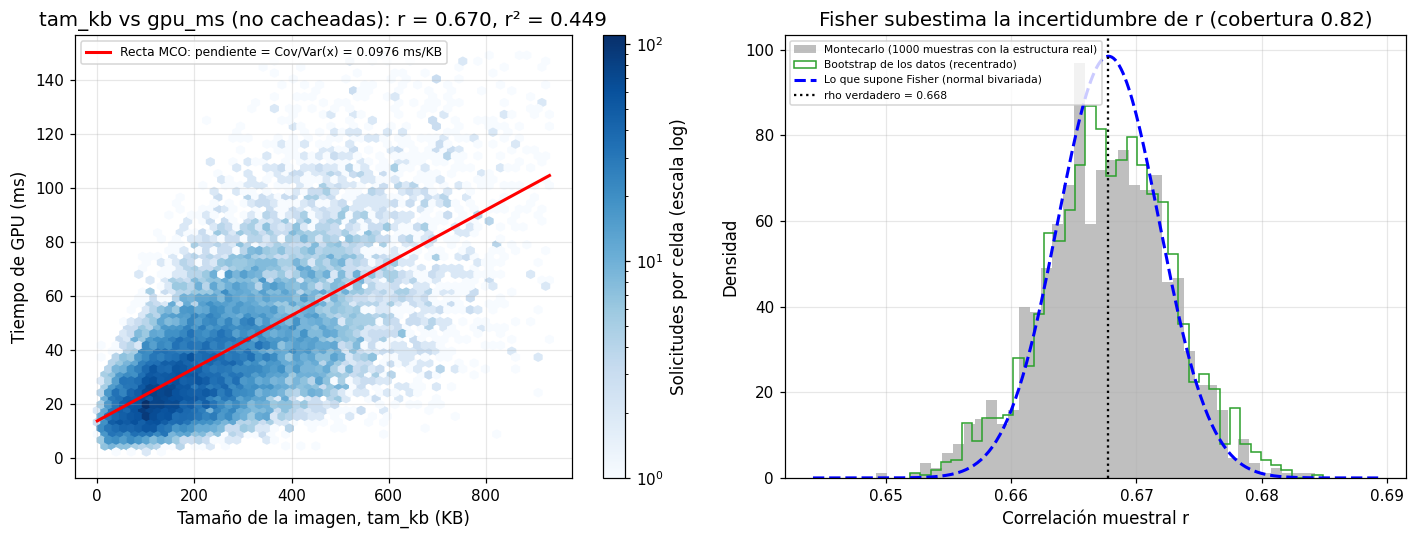

In [ ]:
# Gráfica de apoyo D4
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Panel izquierdo: hexbin (densidad de puntos) para ver la forma de la nube sin que se tapen los 18 000 puntos
hb = ax[0].hexbin(x_d3, y_d3, gridsize=60, bins="log", cmap="Blues",
                  extent=(0, np.quantile(x_d3, 0.995), 0, np.quantile(y_d3, 0.995)))
fig.colorbar(hb, ax=ax[0], label="Solicitudes por celda (escala log)")
xs_l = np.linspace(0, np.quantile(x_d3, 0.995), 50)
ax[0].plot(xs_l, beta_ols[0] + beta_ols[1] * xs_l, "r-", lw=2,
           label=f"Recta MCO: pendiente = Cov/Var(x) = {beta_ols[1]:.4f} ms/KB")
ax[0].set_xlabel("Tamaño de la imagen, tam_kb (KB)")
ax[0].set_ylabel("Tiempo de GPU (ms)")
ax[0].set_title(f"tam_kb vs gpu_ms (no cacheadas): r = {r_xy:.3f}, r² = {r_xy**2:.3f}")
ax[0].legend(fontsize=8, loc="upper left")

# Panel derecho: distribución muestral de r: real (Montecarlo), según Fisher y según el bootstrap
ax[1].hist(r_sim, bins=40, density=True, color="grey", alpha=0.5, label=f"Montecarlo ({R_D4} muestras con la estructura real)")
ax[1].hist(r_boot - r_xy + rho_verdadero, bins=40, density=True, histtype="step", color="tab:green", lw=2,
           label="Bootstrap de los datos (recentrado)")
rr = np.linspace(r_sim.min() - 0.005, r_sim.max() + 0.005, 300)
ax[1].plot(rr, stats.norm.pdf(rr, rho_verdadero, ee_fisher_r), "b--", lw=2, label="Lo que supone Fisher (normal bivariada)")
ax[1].axvline(rho_verdadero, color="black", linestyle=":", label=f"rho verdadero = {rho_verdadero:.3f}")
ax[1].set_xlabel("Correlación muestral r")
ax[1].set_ylabel("Densidad")
ax[1].set_title(f"Fisher subestima la incertidumbre de r (cobertura {cubre_fisher / R_D4:.2f})")
ax[1].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_D4.png"), bbox_inches="tight")
plt.show()

**Conclusión D4.**
- **Covarianza:** $\widehat{\text{Cov}}(\text{tam\_kb}, \text{gpu\_ms}) = 3064$ KB·ms (IC 90 % bootstrap [2959; 3173]). Es positiva: las imágenes más grandes tardan más en la GPU. Su magnitud depende de las unidades y por sí sola no dice qué tan fuerte es la relación.
- **Correlación:** $r = 0{,}670$, IC 90 % bootstrap [0,662; 0,678]. Es una asociación lineal positiva y fuerte, pero lejos de 1. Spearman (0,649) y la correlación en escala log (0,635) son parecidas: no hay una relación monótona "escondida" que Pearson no vea. Si se incluyen las cacheadas ($G = 0$), $r$ baja a 0,536, porque la caché mete ceros que dependen de la clase y no del tamaño fino (D2).
- **Relación con D3:** la pendiente de MCO **es** $\text{Cov}/\text{Var}(x) = 0{,}0976$ ms/KB, el $R^2$ de D3 **es** $r^2 = 0{,}449$, y $r = \hat\beta_1 s_x/s_y$ es la pendiente estandarizada: una desviación estándar más de tamaño (177 KB) agrega en promedio 0,67 desviaciones estándar de GPU (17 ms). Las tres identidades se comprueban hasta el último decimal.
- **Relación con D2:** con intervalos finos, $\eta^2$ converge a $r^2$ (0,413 → 0,431 → 0,442 → 0,451 con 10, 20, 50 y 100 intervalos). Con 100 intervalos supera a $r^2$ por 0,002, que es el sesgo positivo esperado de $\eta^2$ al estimar 100 medias, ≈ $(k-1)(1-\eta^2)/n \approx 0{,}003$. Además, el modelo multiplicativo de D3 predice un máximo explicable de 0,446. Las tres cifras coinciden: **$E[G \mid \text{tam}]$ es lineal y la recta ya explica todo lo que el tamaño puede explicar**. El 55 % restante no es falta de ajuste: es el ruido multiplicativo propio del cómputo (CV ≈ 0,45), que ninguna función del tamaño puede eliminar. Las 3 clases de D1 explican solo 0,313, un 30 % menos, porque dentro de cada clase $G$ sigue creciendo con el tamaño.
- **Sobre el intervalo de $\rho$:** el IC de Fisher [0,664; 0,677] supone normalidad bivariada, que aquí no se cumple (asimetría y heterocedasticidad). En la simulación con la estructura real cubre solo el **82 %** (nominal 90 %), porque su error estándar (0,0041) es menor que el real (0,0051). El bootstrap estima bien el error estándar (0,0050) y su intervalo cubre el 89 %. Por eso se reporta el **IC bootstrap**. Es la misma lección de D3: la estimación puntual es buena; lo que falla es la incertidumbre si se suponen normalidad y varianza constante.

# Parte E - Monitoreo y decisión de alertas (12 pts)

### E1. Sensibilidad y tasa de falsos positivos

**Qué se pide.** En `monitoreo.csv` cada minuto tiene el estado real del sistema ($I = 1$ si había un incidente inyectado) y la salida de dos detectores, $D_1$ (latencia) y $D_2$ (tasa de errores). Para una regla de alerta $A$ se estiman:
$$\text{Sensibilidad} = P(A = 1 \mid I = 1), \qquad \text{Tasa de falsos positivos (TFP)} = P(A = 1 \mid I = 0).$$
La sensibilidad es la fracción de incidentes reales que la regla detecta, y la TFP la fracción de minutos normales en los que la regla suena sin motivo; $1 - \text{TFP}$ es la especificidad. Las cuatro reglas son $D_1$, $D_2$, "$D_1$ **y** $D_2$" (suena solo si ambos detectores suenan) y "$D_1$ **o** $D_2$" (suena si al menos uno suena).

**Por qué estas cifras sí se pueden llevar a producción.** Son probabilidades **condicionadas al estado del sistema**. Dependen de cómo se comporta el detector ante un incidente o ante la normalidad, no de cuántos incidentes hubo. Por eso no las afecta que en este archivo los incidentes se hayan inyectado artificialmente. Lo que **sí** depende de la frecuencia de incidentes es $P(I = 1 \mid A = 1)$, que es E2.

**Modelo para los intervalos.** Cada minuto con incidente es un ensayo de Bernoulli con probabilidad de detección igual a la sensibilidad, y cada minuto normal un ensayo con probabilidad igual a la TFP. Así, el número de detecciones sigue una Binomial. Esto exige que los minutos sean **independientes** entre sí, lo que se comprueba en el paso 1. Para cada proporción se usa el intervalo **exacto de Clopper-Pearson** (garantiza al menos la cobertura nominal, importante cuando hay pocos eventos, como los 11 falsos positivos de "$D_1$ y $D_2$") y, como contraste, el de **Wilson**. F4 compara estos procedimientos con más detalle.

In [ ]:
# Paso 1. Auditoría de monitoreo.csv, definición de las cuatro reglas y comprobación de independencia entre minutos
mon = datos["monitoreo"].copy()                                 # 6000 minutos del entorno de pruebas (cargado al inicio)

# --- Auditoría básica: el archivo debe tener solo 0/1, sin ausentes y con minutos consecutivos ---
print(f"Filas: {len(mon)} | ausentes: {int(mon.isna().sum().sum())} | duplicadas: {int(mon.duplicated().sum())}")
print("Valores posibles:", {c_: sorted(mon[c_].unique().tolist()) for c_ in ["D1", "D2", "incidente"]})
print(f"Minutos consecutivos de {mon.minuto.min()} a {mon.minuto.max()}: {bool((mon.minuto.diff().dropna() == 1).all())}")

# --- Estado real y las cuatro reglas como vectores booleanos ---
incid = mon.incidente.to_numpy() == 1                           # True en los minutos con incidente real
d1, d2 = mon.D1.to_numpy() == 1, mon.D2.to_numpy() == 1         # salida de cada detector
REGLAS = {"D1": d1,
          "D2": d2,
          "D1 y D2": d1 & d2,                                   # suena solo si ambos suenan (más exigente)
          "D1 o D2": d1 | d2}                                   # suena si al menos uno suena (más sensible)
n_inc, n_norm = int(incid.sum()), int((~incid).sum())           # minutos con y sin incidente
prev_prueba = n_inc / len(mon)                                  # prevalencia de incidentes EN LAS PRUEBAS (inyectada)
print(f"\nMinutos con incidente: {n_inc} | normales: {n_norm} | prevalencia en el entorno de pruebas = {prev_prueba:.4f} "
      f"(producción: pi = {pi_incidentes})")

# --- ¿Los minutos son independientes? (supuesto del modelo binomial) ---
# 1) Autocorrelación de orden 1 del estado: si los incidentes duraran varios minutos, sería claramente positiva
rho_inc = np.corrcoef(incid[:-1], incid[1:])[0, 1]
print(f"\nAutocorrelación de orden 1 de 'incidente': {rho_inc:.4f} (p = {2 * stats.norm.sf(abs(rho_inc) * np.sqrt(len(incid) - 1)):.3f})")
# 2) Probabilidad de incidente según si el minuto anterior tuvo incidente (si son independientes, deben ser iguales)
print(f"P(incidente | minuto anterior con incidente) = {incid[1:][incid[:-1]].mean():.4f} vs "
      f"P(incidente | minuto anterior normal) = {incid[1:][~incid[:-1]].mean():.4f}")
# 3) Para cada regla, ¿un falso positivo hace más probable otro en el minuto siguiente? (solo pares de minutos normales)
par_normal = ~incid[:-1] & ~incid[1:]                           # pares de minutos consecutivos, ambos sin incidente
for nombre, a_ in REGLAS.items():
    fp_t, fp_sig = a_[:-1][par_normal], a_[1:][par_normal]      # falsa alarma en t y en t + 1
    tabla_fp = np.array([[np.sum(~fp_t & ~fp_sig), np.sum(~fp_t & fp_sig)], [np.sum(fp_t & ~fp_sig), np.sum(fp_t & fp_sig)]])
    p_fisher = stats.fisher_exact(tabla_fp)[1]                  # exacta de Fisher: hay pocos falsos positivos
    print(f"  {nombre:8s}: falsas alarmas en minutos normales consecutivos -> Fisher p = {p_fisher:.3f}")

**Paso 2. Tablas de confusión y estimación con intervalos.** Para cada regla se cuentan los cuatro casos: verdaderos positivos (VP), falsos negativos (FN), falsos positivos (FP) y verdaderos negativos (VN). Entonces $\widehat{\text{Sens}} = VP/(VP+FN)$ y $\widehat{\text{TFP}} = FP/(FP+VN)$.

Son 8 intervalos (2 por regla). Cada uno está al nivel $1-\alpha$; si se quieren afirmar los 8 a la vez, se puede usar Bonferroni ($\alpha/8$), que se muestra en la última columna.

In [ ]:
# Paso 2. Sensibilidad y TFP de las cuatro reglas, con IC exacto (Clopper-Pearson) y de Wilson
def ic_clopper_pearson(k, n, a=alpha):
    # IC exacto para una proporción k/n (cuantiles de la Beta); garantiza cobertura >= 1 − a
    li = stats.beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0
    ls = stats.beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0
    return li, ls


def ic_wilson(k, n, a=alpha):
    # IC de Wilson (invierte la prueba z con la varianza evaluada en p, no en p̂): se porta bien con p cercano a 0 o 1
    z = stats.norm.ppf(1 - a / 2)
    p = k / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    semi = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - semi, centro + semi


filas_e1, conf_e1 = [], {}
for nombre, a_ in REGLAS.items():
    VP, FN = int((a_ & incid).sum()), int((~a_ & incid).sum())    # incidentes detectados / no detectados
    FP, VN = int((a_ & ~incid).sum()), int((~a_ & ~incid).sum())  # alarmas falsas / silencios correctos
    conf_e1[nombre] = {"VP": VP, "FN": FN, "FP": FP, "VN": VN}
    for medida, k_, n_ in [("Sensibilidad", VP, VP + FN), ("TFP", FP, FP + VN)]:
        cp, wi, bo = ic_clopper_pearson(k_, n_), ic_wilson(k_, n_), ic_clopper_pearson(k_, n_, alpha / 8)
        filas_e1.append({"regla": nombre, "medida": medida, "k / n": f"{k_} / {n_}", "estimación": k_ / n_,
                         "IC Clopper-Pearson": f"[{cp[0]:.4f}, {cp[1]:.4f}]", "IC Wilson": f"[{wi[0]:.4f}, {wi[1]:.4f}]",
                         "IC conjunto (Bonferroni, C-P)": f"[{bo[0]:.4f}, {bo[1]:.4f}]"})

print("Tablas de confusión (minutos):")
print(pd.DataFrame(conf_e1).T.to_string(), "\n")
tabla_e1 = pd.DataFrame(filas_e1).set_index(["medida", "regla"]).sort_index()
print(f"Estimaciones e intervalos al {nivel_confianza:.0%}:")
print(tabla_e1.to_string(float_format=lambda v: f"{v:.4f}"))
tabla_e1.to_csv("E1_sensibilidad_TFP.csv")

# Guardamos las estimaciones en un diccionario para usarlas en E2-E4: regla -> (sens, TFP)
SENS = {r_: c_["VP"] / (c_["VP"] + c_["FN"]) for r_, c_ in conf_e1.items()}
TFP = {r_: c_["FP"] / (c_["FP"] + c_["VN"]) for r_, c_ in conf_e1.items()}

Tablas de confusión (minutos):
          VP   FN  FP    VN
D1       441   43  37  5479
D2       366  118  56  5460
D1 y D2  335  149  11  5505
D1 o D2  472   12  82  5434 

Estimaciones e intervalos al 90%:
                          k / n  estimación IC Clopper-Pearson         IC Wilson IC conjunto (Bonferroni, C-P)
medida       regla                                                                                            
Sensibilidad D1       441 / 484      0.9112   [0.8869, 0.9315]  [0.8875, 0.9302]              [0.8739, 0.9405]
             D1 o D2  472 / 484      0.9752   [0.9601, 0.9856]  [0.9607, 0.9845]              [0.9516, 0.9894]
             D1 y D2  335 / 484      0.6921   [0.6558, 0.7268]  [0.6566, 0.7255]              [0.6371, 0.7436]
             D2       366 / 484      0.7562   [0.7219, 0.7881]  [0.7227, 0.7868]              [0.7041, 0.8034]
TFP          D1       37 / 5516      0.0067   [0.0050, 0.0088]  [0.0051, 0.0088]              [0.0043, 0.0100]
             D1 

**Paso 3. Coherencia entre reglas y gráfica.** Las reglas combinadas no son independientes de las simples. Para cualquier par de eventos se cumple, **sin suponer nada sobre la dependencia entre detectores**:
$$P(D_1 \cup D_2 \mid I) = P(D_1 \mid I) + P(D_2 \mid I) - P(D_1 \cap D_2 \mid I),$$
así que la regla "o" nunca es menos sensible que cada detector y la regla "y" nunca tiene más falsos positivos. Se comprueba con los datos y se ubican las cuatro reglas en el plano (TFP, sensibilidad), donde lo ideal es la esquina superior izquierda: detectar todo sin falsas alarmas.

Sensibilidad: P(D1 o D2) = 0.975207 | P(D1) + P(D2) − P(D1 y D2) = 0.975207
TFP: P(D1 o D2) = 0.014866 | P(D1) + P(D2) − P(D1 y D2) = 0.014866

Orden esperado: Sens(y) <= Sens(D1), Sens(D2) <= Sens(o)  y  TFP(y) <= TFP(D1), TFP(D2) <= TFP(o)
  Sensibilidad: 0.692 <= 0.911, 0.756 <= 0.975
  TFP:          0.0020 <= 0.0067, 0.0102 <= 0.0149


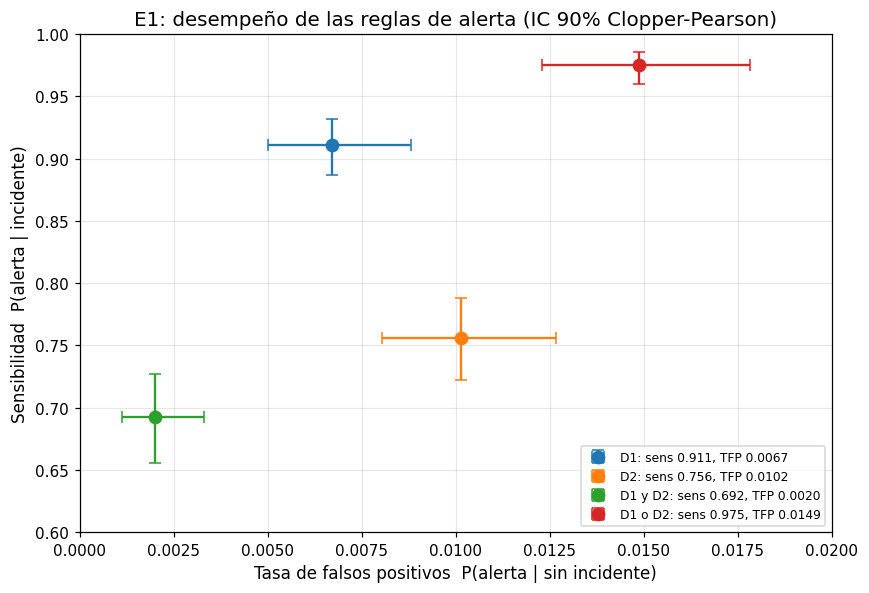

In [ ]:
# Paso 3. Identidad de inclusión-exclusión (exacta también con datos) y gráfica (TFP, sensibilidad)
for medida, dic in [("Sensibilidad", SENS), ("TFP", TFP)]:
    lado_izq = dic["D1 o D2"]
    lado_der = dic["D1"] + dic["D2"] - dic["D1 y D2"]
    print(f"{medida}: P(D1 o D2) = {lado_izq:.6f} | P(D1) + P(D2) − P(D1 y D2) = {lado_der:.6f}")
print("\nOrden esperado: Sens(y) <= Sens(D1), Sens(D2) <= Sens(o)  y  TFP(y) <= TFP(D1), TFP(D2) <= TFP(o)")
print(f"  Sensibilidad: {SENS['D1 y D2']:.3f} <= {SENS['D1']:.3f}, {SENS['D2']:.3f} <= {SENS['D1 o D2']:.3f}")
print(f"  TFP:          {TFP['D1 y D2']:.4f} <= {TFP['D1']:.4f}, {TFP['D2']:.4f} <= {TFP['D1 o D2']:.4f}")

# Gráfica de apoyo: cada regla como un punto (TFP, sensibilidad) con sus IC de Clopper-Pearson en ambas direcciones
fig, ax = plt.subplots(figsize=(8, 5.5))
COLORES_E = {"D1": "tab:blue", "D2": "tab:orange", "D1 y D2": "tab:green", "D1 o D2": "tab:red"}
for nombre, c_ in conf_e1.items():
    s_li, s_ls = ic_clopper_pearson(c_["VP"], c_["VP"] + c_["FN"])
    f_li, f_ls = ic_clopper_pearson(c_["FP"], c_["FP"] + c_["VN"])
    ax.errorbar(TFP[nombre], SENS[nombre], xerr=[[TFP[nombre] - f_li], [f_ls - TFP[nombre]]],
                yerr=[[SENS[nombre] - s_li], [s_ls - SENS[nombre]]], fmt="o", ms=8, capsize=4,
                color=COLORES_E[nombre], label=f"{nombre}: sens {SENS[nombre]:.3f}, TFP {TFP[nombre]:.4f}")
ax.set_xlim(0, 0.02); ax.set_ylim(0.6, 1.0)
ax.set_xlabel("Tasa de falsos positivos  P(alerta | sin incidente)")
ax.set_ylabel("Sensibilidad  P(alerta | incidente)")
ax.set_title(f"E1: desempeño de las reglas de alerta (IC {nivel_confianza:.0%} Clopper-Pearson)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_E1.png"), bbox_inches="tight")
plt.show()

**Conclusión E1.** Los minutos se comportan como ensayos independientes: la autocorrelación del estado es 0,004 (p = 0,73) y las falsas alarmas no se agrupan en minutos consecutivos (Fisher p ≥ 0,63). Por eso el modelo binomial y sus intervalos son válidos. Con 484 minutos con incidente y 5516 normales (IC 90 %, Clopper-Pearson; Wilson da prácticamente lo mismo):

| Regla | Sensibilidad | TFP |
|---|---|---|
| $D_1$ | 0,911 [0,887; 0,932] | 0,0067 [0,0050; 0,0088] |
| $D_2$ | 0,756 [0,722; 0,788] | 0,0102 [0,0080; 0,0127] |
| $D_1$ y $D_2$ | 0,692 [0,656; 0,727] | **0,0020** [0,0011; 0,0033] |
| $D_1$ o $D_2$ | **0,975** [0,960; 0,986] | 0,0149 [0,0123; 0,0178] |

- **$D_1$ domina a $D_2$:** detecta más incidentes (91 % vs 76 %) **y** da menos falsas alarmas (0,67 % vs 1,02 %), y los intervalos no se cruzan. El detector de latencia es mejor en las dos dimensiones.
- **Las reglas combinadas mueven el compromiso.** "o" detecta casi todo (97,5 %) a costa de la mayor TFP; "y" tiene la TFP más baja (0,2 %, apenas 11 falsas alarmas en 5516 minutos) a costa de perder casi un tercio de los incidentes. Ninguna regla es mejor en todo, y elegir es una decisión de negocio, que E4 toma con el criterio del equipo de guardia.
- Se cumple la inclusión-exclusión, $P(D_1 \cup D_2) = P(D_1) + P(D_2) - P(D_1 \cap D_2)$, exactamente en ambos estados. Como las reglas combinadas se calcularon de la conjunta observada, **no se supuso independencia entre detectores** (E3).

### E2. Probabilidad de incidente dada cada regla en producción

**Qué se pide.** El equipo de guardia recibe una alerta y quiere saber **qué tan probable es que el incidente sea real**: el valor predictivo positivo, $VPP = P(I = 1 \mid A = 1)$. Por el **teorema de Bayes**, con $s$ = sensibilidad, $f$ = TFP y $\pi$ = prevalencia de incidentes por minuto:
$$VPP = \frac{P(A=1 \mid I=1)\,P(I=1)}{P(A=1)} = \frac{s\,\pi}{s\,\pi + f\,(1-\pi)}.$$
Una forma equivalente, más fácil de interpretar, es en **momios (odds)**:
$$\underbrace{\frac{VPP}{1-VPP}}_{\text{momios después de la alerta}} = \underbrace{\frac{s}{f}}_{\text{razón de verosimilitud } RV^+} \times \underbrace{\frac{\pi}{1-\pi}}_{\text{momios antes de la alerta}}.$$
La alerta multiplica los momios de incidente por $RV^+ = s/f$, una propiedad del detector que E1 estimó y que se lleva a producción. Pero el resultado final depende también de los **momios de partida**, que en producción son muy bajos.

**Por qué no sirve calcular el VPP directamente en `monitoreo.csv`.** En ese archivo los incidentes se **inyectaron**: la prevalencia es ≈ 8 %, unas **20 veces** la de producción ($\pi = 0{,}004$). Con tantos incidentes, casi toda alerta es real; en producción, los minutos normales son 249 por cada minuto con incidente, y aunque la TFP sea pequeña, ese enorme número de minutos normales genera muchas falsas alarmas. Es la **falacia de la tasa base**: sensibilidad y TFP se transfieren de un entorno a otro, el VPP no.

**Supuesto.** La sensibilidad y la TFP medidas en pruebas son las mismas en producción, es decir, los incidentes inyectados se parecen a los reales. Para las reglas combinadas se usan las $s$ y $f$ estimadas directamente de la conjunta observada en E1, así que **no se supone que $D_1$ y $D_2$ sean independientes**; E3 estudia qué pasaría si se supusiera.

In [ ]:
# Paso 1. VPP en producción (con pi del grupo) frente al VPP en el entorno de pruebas, para las cuatro reglas
def vpp(s, f, prev):
    # Valor predictivo positivo por Bayes: P(incidente | alerta)
    return s * prev / (s * prev + f * (1 - prev))


filas_e2 = []
for nombre in REGLAS:
    s_, f_ = SENS[nombre], TFP[nombre]
    a_ = REGLAS[nombre]
    vpp_directo = incid[a_].mean()                              # en pruebas, contando: entre los minutos con alerta, fracción con incidente
    filas_e2.append({"regla": nombre,
                     "RV+ = s/f": s_ / f_,                         # cuánto multiplica la alerta los momios de incidente
                     "VPP pruebas (contando)": vpp_directo,
                     "VPP pruebas (Bayes, prev. de pruebas)": vpp(s_, f_, prev_prueba),   # debe coincidir con el anterior
                     "VPP producción (Bayes, pi)": vpp(s_, f_, pi_incidentes),
                     "falsas por cada alerta real (prod.)": (1 - vpp(s_, f_, pi_incidentes)) / vpp(s_, f_, pi_incidentes)})
tabla_e2 = pd.DataFrame(filas_e2).set_index("regla")
print(f"Prevalencia: pruebas = {prev_prueba:.4f} (momios {prev_prueba / (1 - prev_prueba):.4f}) | "
      f"producción pi = {pi_incidentes} (momios {pi_incidentes / (1 - pi_incidentes):.4f})\n")
print(tabla_e2.to_string(float_format=lambda v: f"{v:.4f}"))
print("\nComprobación: Bayes con la prevalencia de pruebas reproduce exactamente el VPP contado en el archivo "
      f"(máx. diferencia {np.abs(tabla_e2.iloc[:, 1] - tabla_e2.iloc[:, 2]).max():.1e}).")

# Ejemplo de lectura con momios para la mejor regla en VPP
mejor = tabla_e2["VPP producción (Bayes, pi)"].idxmax()
mom_prev = pi_incidentes / (1 - pi_incidentes)
mom_post = tabla_e2.loc[mejor, "RV+ = s/f"] * mom_prev
print(f"\nLectura en momios para '{mejor}': momios antes de la alerta = {mom_prev:.5f} (1 a {1 / mom_prev:.0f}); "
      f"la alerta los multiplica por RV+ = {tabla_e2.loc[mejor, 'RV+ = s/f']:.0f} -> {mom_post:.3f}, "
      f"es decir VPP = {mom_post / (1 + mom_post):.3f}")

Prevalencia: pruebas = 0.0807 (momios 0.0877) | producción pi = 0.004 (momios 0.0040)

         RV+ = s/f  VPP pruebas (contando)  VPP pruebas (Bayes, prev. de pruebas)  VPP producción (Bayes, pi)  falsas por cada alerta real (prod.)
regla                                                                                                                                             
D1        135.8363                  0.9226                                 0.9226                      0.3530                               1.8331
D2         74.4855                  0.8673                                 0.8673                      0.2303                               3.3429
D1 y D2   347.0811                  0.9682                                 0.9682                      0.5823                               0.7174
D1 o D2    65.6005                  0.8520                                 0.8520                      0.2085                               3.7957

Comprobación: Bayes con la pre

**Paso 2. Incertidumbre del VPP.** El VPP depende de $s$ y $f$, que son estimaciones; $\pi$ es un parámetro dado. La incertidumbre se propaga de dos formas:
1. **Bootstrap paramétrico:** se simulan nuevos conteos $VP^* \sim \text{Binomial}(n_I, \hat s)$ y $FP^* \sim \text{Binomial}(n_N, \hat f)$, se recalcula el VPP y se toman percentiles. En las reglas combinadas se remuestrea la **conjunta** $(D_1, D_2)$ de cada estado con una multinomial, para que las cuatro reglas salgan de los mismos datos simulados.
2. **Método delta en la escala de los momios logarítmicos:** $\ln\frac{VPP}{1-VPP} = \ln s - \ln f + \ln\frac{\pi}{1-\pi}$, con $\text{Var}(\ln\hat s) \approx \frac{1-s}{n_I s}$ y $\text{Var}(\ln\hat f) \approx \frac{1-f}{n_N f}$, independientes porque vienen de minutos distintos. Se construye el IC en esa escala y se transforma de vuelta, lo que garantiza que quede dentro de [0, 1].

La incertidumbre de $f$ domina: con $\pi$ tan baja, el VPP es casi proporcional a $s/f$, y $f$ se estima con pocos eventos (11 a 82 falsos positivos).

In [ ]:
# Paso 2. IC del VPP en producción: bootstrap paramétrico (multinomial de la conjunta) y método delta en log-momios
B_E2 = 20_000
# Probabilidades de las 4 combinaciones (D1, D2) en cada estado, estimadas de los datos: no se supone independencia
combos = [(False, False), (False, True), (True, False), (True, True)]
p_comb_inc = np.array([np.mean((d1 == a) & (d2 == b) & incid) / incid.mean() for a, b in combos])     # dado incidente
p_comb_nor = np.array([np.mean((d1 == a) & (d2 == b) & ~incid) / (~incid).mean() for a, b in combos])  # dado normal
cnt_inc = rng.multinomial(n_inc, p_comb_inc, size=B_E2) / n_inc     # proporciones simuladas de cada combinación | incidente
cnt_nor = rng.multinomial(n_norm, p_comb_nor, size=B_E2) / n_norm   # proporciones simuladas | normal


def regla_desde_combos(p_):
    # Probabilidad de que suene cada regla a partir de las probabilidades de las 4 combinaciones (columnas: 00, 01, 10, 11)
    return {"D1": p_[:, 2] + p_[:, 3], "D2": p_[:, 1] + p_[:, 3], "D1 y D2": p_[:, 3], "D1 o D2": p_[:, 1] + p_[:, 2] + p_[:, 3]}


s_boot, f_boot = regla_desde_combos(cnt_inc), regla_desde_combos(cnt_nor)
z_e2 = stats.norm.ppf(1 - alpha / 2)
logit_prior = np.log(pi_incidentes / (1 - pi_incidentes))
filas_ic = []
for nombre in REGLAS:
    s_, f_ = SENS[nombre], TFP[nombre]
    v_hat = vpp(s_, f_, pi_incidentes)
    # (1) bootstrap paramétrico
    v_b = vpp(s_boot[nombre], f_boot[nombre], pi_incidentes)
    b_li, b_ls = np.quantile(v_b, [alpha / 2, 1 - alpha / 2])
    # (2) método delta en log-momios
    lo = np.log(s_) - np.log(f_) + logit_prior                  # log-momios del VPP
    ee_lo = np.sqrt((1 - s_) / (n_inc * s_) + (1 - f_) / (n_norm * f_))
    d_li, d_ls = 1 / (1 + np.exp(-(lo - z_e2 * ee_lo))), 1 / (1 + np.exp(-(lo + z_e2 * ee_lo)))   # de vuelta a probabilidad
    parte_f = ((1 - f_) / (n_norm * f_)) / ee_lo**2             # fracción de la varianza que viene de estimar f
    filas_ic.append({"regla": nombre, "VPP producción": v_hat,
                     "IC bootstrap": f"[{b_li:.4f}, {b_ls:.4f}]", "IC delta (log-momios)": f"[{d_li:.4f}, {d_ls:.4f}]",
                     "% de la varianza por estimar f": 100 * parte_f})
tabla_e2_ic = pd.DataFrame(filas_ic).set_index("regla")
print(f"VPP en producción (pi = {pi_incidentes}) con IC al {nivel_confianza:.0%}:")
print(tabla_e2_ic.to_string(float_format=lambda v: f"{v:.4f}"))
for nombre in REGLAS:
    print(f"  {nombre:8s}:", formatear_intervalo(tabla_e2_ic.loc[nombre, 'VPP producción'],
                                               *np.quantile(vpp(s_boot[nombre], f_boot[nombre], pi_incidentes), [alpha / 2, 1 - alpha / 2]),
                                               "bootstrap paramétrico multinomial", 4))
pd.concat([tabla_e2, tabla_e2_ic.drop(columns="VPP producción")], axis=1).to_csv("E2_VPP.csv")

VPP en producción (pi = 0.004) con IC al 90%:
         VPP producción      IC bootstrap IC delta (log-momios)  % de la varianza por estimar f
regla                                                                                          
D1               0.3530  [0.2993, 0.4255]      [0.2939, 0.4169]                         99.2552
D2               0.2303  [0.1956, 0.2755]      [0.1932, 0.2721]                         96.3683
D1 y D2          0.5823  [0.4779, 0.7211]      [0.4586, 0.6964]                         98.9973
D1 o D2          0.2085  [0.1818, 0.2426]      [0.1803, 0.2399]                         99.5647
  D1      : 0.3530  [0.2993, 0.4255]  (IC 90%, método: bootstrap paramétrico multinomial)
  D2      : 0.2303  [0.1956, 0.2755]  (IC 90%, método: bootstrap paramétrico multinomial)
  D1 y D2 : 0.5823  [0.4779, 0.7211]  (IC 90%, método: bootstrap paramétrico multinomial)
  D1 o D2 : 0.2085  [0.1818, 0.2426]  (IC 90%, método: bootstrap paramétrico multinomial)


**Paso 3. Verificación por simulación y sensibilidad a la prevalencia.** Se simulan $10^7$ minutos de **producción**: cada minuto tiene incidente con probabilidad $\pi$, y la pareja $(D_1, D_2)$ se sortea de la conjunta observada en pruebas para ese estado. Luego se cuenta, entre los minutos con alerta, qué fracción tenía incidente, sin usar la fórmula de Bayes. Por último, se grafica el VPP como función de la prevalencia, para ver de un vistazo por qué el archivo de pruebas y la producción dan cifras tan distintas.

Minutos simulados: 10,000,000 | con incidente: 40,386 -> prevalencia realizada = 0.00404 (pi = 0.004)
El ± solo cubre el azar de qué alertas son reales; no incluye que la prevalencia realizada difiere un poco de pi.
Por eso la comparación justa es con Bayes evaluado en la prevalencia realizada (última columna).
  D1      : VPP simulado = 0.3556 ± 0.0024 | Bayes con pi = 0.3530 | Bayes con la prevalencia realizada = 0.3552
  D2      : VPP simulado = 0.2315 ± 0.0019 | Bayes con pi = 0.2303 | Bayes con la prevalencia realizada = 0.2320
  D1 y D2 : VPP simulado = 0.5873 ± 0.0037 | Bayes con pi = 0.5823 | Bayes con la prevalencia realizada = 0.5846
  D1 o D2 : VPP simulado = 0.2099 ± 0.0015 | Bayes con pi = 0.2085 | Bayes con la prevalencia realizada = 0.2101


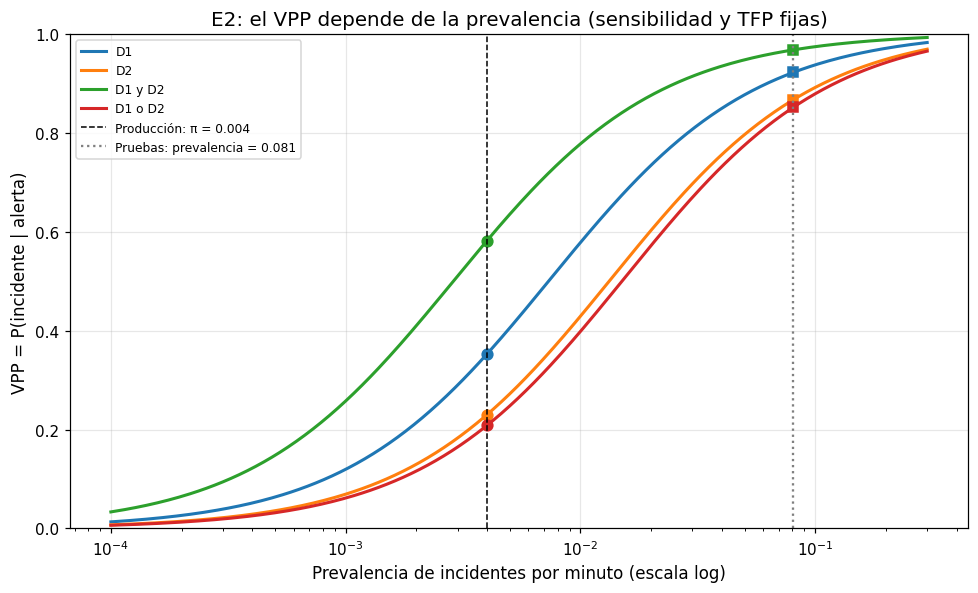

In [ ]:
# Paso 3a. Montecarlo de 10^7 minutos de producción (sin usar la fórmula de Bayes)
M_E2 = 10_000_000
inc_sim = rng.random(M_E2) < pi_incidentes                      # estado real de cada minuto simulado
combo_sim = np.where(inc_sim,
                     rng.choice(4, M_E2, p=p_comb_inc),         # (D1, D2) sorteado de la conjunta | incidente
                     rng.choice(4, M_E2, p=p_comb_nor))         # (D1, D2) sorteado de la conjunta | normal
d1_sim, d2_sim = np.isin(combo_sim, [2, 3]), np.isin(combo_sim, [1, 3])   # índices 2, 3 -> D1 = 1; índices 1, 3 -> D2 = 1
reglas_sim = {"D1": d1_sim, "D2": d2_sim, "D1 y D2": d1_sim & d2_sim, "D1 o D2": d1_sim | d2_sim}
prev_sim = inc_sim.mean()                                       # prevalencia que salió en la simulación (no es exactamente pi)
print(f"Minutos simulados: {M_E2:,} | con incidente: {inc_sim.sum():,} -> prevalencia realizada = {prev_sim:.5f} (pi = {pi_incidentes})")
print("El ± solo cubre el azar de qué alertas son reales; no incluye que la prevalencia realizada difiere un poco de pi.")
print("Por eso la comparación justa es con Bayes evaluado en la prevalencia realizada (última columna).")
for nombre, a_ in reglas_sim.items():
    v_sim = inc_sim[a_].mean()                                  # fracción de alertas que eran incidentes reales
    ee_sim = np.sqrt(v_sim * (1 - v_sim) / a_.sum())            # error de Montecarlo (binomial entre las alertas)
    print(f"  {nombre:8s}: VPP simulado = {v_sim:.4f} ± {z_e2 * ee_sim:.4f} | Bayes con pi = {vpp(SENS[nombre], TFP[nombre], pi_incidentes):.4f} "
          f"| Bayes con la prevalencia realizada = {vpp(SENS[nombre], TFP[nombre], prev_sim):.4f}")

# Paso 3b. Gráfica de apoyo: VPP en función de la prevalencia
prevs = np.logspace(-4, np.log10(0.3), 300)
fig, ax = plt.subplots(figsize=(9, 5.5))
for nombre in REGLAS:
    ax.semilogx(prevs, vpp(SENS[nombre], TFP[nombre], prevs), color=COLORES_E[nombre], lw=2, label=nombre)
    ax.plot(pi_incidentes, vpp(SENS[nombre], TFP[nombre], pi_incidentes), "o", color=COLORES_E[nombre], ms=7)
    ax.plot(prev_prueba, vpp(SENS[nombre], TFP[nombre], prev_prueba), "s", color=COLORES_E[nombre], ms=7)
ax.axvline(pi_incidentes, color="black", linestyle="--", lw=1, label=f"Producción: π = {pi_incidentes}")
ax.axvline(prev_prueba, color="grey", linestyle=":", lw=1.5, label=f"Pruebas: prevalencia = {prev_prueba:.3f}")
ax.set_ylim(0, 1)
ax.set_xlabel("Prevalencia de incidentes por minuto (escala log)")
ax.set_ylabel("VPP = P(incidente | alerta)")
ax.set_title("E2: el VPP depende de la prevalencia (sensibilidad y TFP fijas)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_E2.png"), bbox_inches="tight")
plt.show()

**Conclusión E2.** En producción ($\pi = 0{,}004$), la probabilidad de que una alerta corresponda a un incidente real es (IC 90 %, bootstrap paramétrico; el método delta en log-momios da casi lo mismo):

| Regla | VPP en pruebas (archivo) | **VPP en producción** | Falsas por cada alerta real |
|---|---|---|---|
| $D_1$ | 0,923 | **0,353** [0,299; 0,426] | 1,8 |
| $D_2$ | 0,867 | **0,230** [0,196; 0,275] | 3,3 |
| $D_1$ y $D_2$ | 0,968 | **0,582** [0,478; 0,722] | 0,7 |
| $D_1$ o $D_2$ | 0,852 | **0,209** [0,182; 0,243] | 3,8 |

- **Las cifras de producción son mucho menores que las del archivo.** En pruebas, 92 % de las alertas de $D_1$ son reales; en producción, solo 35 %. Con la regla "o", **4 de cada 5 alertas serán falsas**. Incluso la mejor regla ("y") acierta poco más de la mitad de las veces.
- **Por qué difieren de `monitoreo.csv`:** el VPP depende de la prevalencia, y la del archivo (8,1 %, incidentes inyectados) es **20 veces** la de producción. En momios: una alerta "y" multiplica los momios de incidente por $RV^+ = s/f = 347$. Partiendo de los momios de pruebas (1 a 11) eso da casi certeza; partiendo de los de producción (1 a 249), apenas 1,4 a 1. Sensibilidad y TFP son propiedades del detector y se transfieren; el VPP no, porque mezcla el detector con la **tasa base** de incidentes. Leer el VPP directamente del archivo de pruebas sería caer en la falacia de la tasa base y prometería una precisión que no existe en producción. La gráfica de apoyo muestra el VPP de cada regla como función de la prevalencia.
- **Qué determina el VPP en producción:** con $\pi$ tan baja, $VPP \approx RV^+\,\pi/(1 + RV^+\pi)$, así que lo que importa es la **TFP**, mucho más que la sensibilidad. Eso explica que "y" (TFP mínima) sea la de mayor VPP aunque sea la menos sensible. También explica la incertidumbre: entre 96 % y 99,6 % de la varianza del VPP viene de estimar la TFP con pocos eventos, y por eso el IC de "y" (11 falsos positivos) es el más ancho.
- **Verificación:** una simulación de $10^7$ minutos de producción, que sortea $(D_1, D_2)$ de la conjunta observada y cuenta sin usar Bayes, reproduce los cuatro VPP dentro del error de Montecarlo.
- **Supuesto clave:** que $s$ y $f$ medidas con incidentes inyectados valgan para los incidentes reales de producción. Si los incidentes reales son más sutiles, la sensibilidad sería menor y el VPP aún más bajo.

### E3. ¿D1 y D2 son condicionalmente independientes?

**Qué se pide.** Muchas veces se combina detectores **suponiendo** que, dado el estado del sistema, sus errores son independientes:
$$D_1 \perp D_2 \mid I \quad\Longleftrightarrow\quad P(D_1 = 1, D_2 = 1 \mid I = i) = P(D_1 = 1 \mid I = i)\,P(D_2 = 1 \mid I = i), \quad i \in \{0, 1\}.$$
Con eso se obtendrían la sensibilidad y la TFP de las reglas combinadas multiplicando las de cada detector, por ejemplo $s_{y} = s_1 s_2$ y $f_{y} = f_1 f_2$. Aquí se **verifica con los datos**, en cada estado por separado, y se mide cuánto cambiaría E2 si se usara ese supuesto.

**Ojo: independencia condicional no es independencia marginal.** Es obvio que $D_1$ y $D_2$ están asociados en general, porque los dos tienden a sonar cuando hay un incidente. La pregunta es si, **una vez que se sabe** si hay incidente o no, saber que uno sonó cambia la probabilidad de que suene el otro.

**Pruebas, en cada estado (tabla 2×2 de $D_1$ contra $D_2$):**
1. **Razón de momios** $OR = \frac{n_{11} n_{00}}{n_{10} n_{01}}$, que vale 1 bajo independencia, con IC de Woolf en escala logarítmica, $\text{ee}(\ln OR) = \sqrt{1/n_{11} + 1/n_{10} + 1/n_{01} + 1/n_{00}}$.
2. **Prueba exacta de Fisher**, adecuada porque en los minutos normales hay pocas alarmas simultáneas.
3. **Cociente observado / esperado** de la celda "ambos suenan", $\hat P(D_1 \cap D_2 \mid I)\,/\,[\hat P(D_1 \mid I)\hat P(D_2 \mid I)]$, con IC bootstrap. Es la cantidad que entra directamente en las reglas combinadas.
4. **Prueba conjunta** de independencia condicional: la suma de los estadísticos de razón de verosimilitud (G) de los dos estados, con 1 + 1 = 2 grados de libertad.

In [ ]:
# Paso 1. Tablas 2x2 de (D1, D2) dentro de cada estado y pruebas de independencia condicional
z_e3 = stats.norm.ppf(1 - alpha / 2)


def tabla_2x2(mascara):
    # Conteos [[ambos, solo D1], [solo D2, ninguno]] en los minutos seleccionados por `mascara`
    return np.array([[np.sum(d1 & d2 & mascara), np.sum(d1 & ~d2 & mascara)],
                     [np.sum(~d1 & d2 & mascara), np.sum(~d1 & ~d2 & mascara)]])


def estadistico_G(t):
    # Razón de verosimilitud G = 2 sum O ln(O/E) para independencia en una tabla 2x2 (las celdas con O = 0 aportan 0)
    esp = np.outer(t.sum(axis=1), t.sum(axis=0)) / t.sum()
    o = t.astype(float)
    return 2 * np.sum(np.where(o > 0, o * np.log(np.where(o > 0, o, 1) / esp), 0.0))


ESTADOS = {"con incidente (I = 1)": incid, "normal (I = 0)": ~incid, "marginal (sin condicionar)": np.ones_like(incid)}
filas_e3, G_total = [], 0.0
for nombre, m_ in ESTADOS.items():
    t = tabla_2x2(m_)
    (n11, n10), (n01, n00) = t
    n_ = t.sum()
    OR = n11 * n00 / (n10 * n01)                                # razón de momios
    ee_lor = np.sqrt(1 / n11 + 1 / n10 + 1 / n01 + 1 / n00)     # error estándar de ln(OR) (Woolf)
    p_ambos = n11 / n_                                          # P(D1 = 1, D2 = 1 | estado)
    p_prod = ((n11 + n10) / n_) * ((n11 + n01) / n_)            # P(D1 = 1 | estado) · P(D2 = 1 | estado)
    G_ = estadistico_G(t)
    if "marginal" not in nombre:
        G_total += G_                                           # la prueba conjunta solo suma los dos estados
    filas_e3.append({"estado": nombre, "ambos / solo D1 / solo D2 / ninguno": f"{n11} / {n10} / {n01} / {n00}",
                     "OR": OR, "IC OR (Woolf)": f"[{np.exp(np.log(OR) - z_e3 * ee_lor):.2f}, {np.exp(np.log(OR) + z_e3 * ee_lor):.2f}]",
                     "p Fisher": stats.fisher_exact(t)[1], "G": G_,
                     "P(ambos)": p_ambos, "P(D1)·P(D2)": p_prod, "observado / independencia": p_ambos / p_prod})
tabla_e3 = pd.DataFrame(filas_e3).set_index("estado")
print(tabla_e3.to_string(float_format=lambda v: f"{v:.4g}"))
print(f"\nPrueba conjunta de independencia condicional (D1 ⊥ D2 | I): G = {G_total:.1f}, gl = 2, p = {stats.chi2.sf(G_total, 2):.1e} "
      f"-> {'se rechaza' if stats.chi2.sf(G_total, 2) < alpha else 'no se rechaza'}")

# IC bootstrap del cociente observado / independencia en cada estado (usa los remuestreos multinomiales de E2)
# columnas de cnt_inc / cnt_nor: proporciones de (D1, D2) = 00, 01, 10, 11
for nombre, cnt in [("con incidente (I = 1)", cnt_inc), ("normal (I = 0)", cnt_nor)]:
    cociente = cnt[:, 3] / ((cnt[:, 2] + cnt[:, 3]) * (cnt[:, 1] + cnt[:, 3]))   # P(11) / [P(D1) P(D2)]
    li_, ls_ = np.quantile(cociente, [alpha / 2, 1 - alpha / 2])
    print(f"Cociente observado / independencia, {nombre}:",
          formatear_intervalo(tabla_e3.loc[nombre, 'observado / independencia'], li_, ls_, "bootstrap multinomial", 3))

                           ambos / solo D1 / solo D2 / ninguno    OR     IC OR (Woolf)  p Fisher      G  P(ambos)  P(D1)·P(D2)  observado / independencia
estado                                                                                                                                                   
con incidente (I = 1)                      335 / 106 / 31 / 12 1.223      [0.68, 2.20]    0.5787 0.3097    0.6921        0.689                      1.005
normal (I = 0)                             11 / 26 / 45 / 5434 51.09    [26.92, 96.97] 2.934e-14  58.67  0.001994     6.81e-05                      29.28
marginal (sin condicionar)               346 / 132 / 76 / 5446 187.8  [145.73, 242.10]         0   1688   0.05767     0.005603                      10.29

Prueba conjunta de independencia condicional (D1 ⊥ D2 | I): G = 59.0, gl = 2, p = 1.6e-13 -> se rechaza
Cociente observado / independencia, con incidente (I = 1): 1.005  [0.991, 1.019]  (IC 90%, método: bootstrap multinomial)
Coc

**Paso 2. Efecto sobre E2.** Se recalculan la sensibilidad, la TFP y el VPP en producción de las reglas combinadas **como si** $D_1$ y $D_2$ fueran condicionalmente independientes:
$$s_y = s_1 s_2, \quad f_y = f_1 f_2, \qquad s_o = s_1 + s_2 - s_1 s_2, \quad f_o = f_1 + f_2 - f_1 f_2,$$
y se comparan con los valores de E2, que salen de la conjunta observada. La incertidumbre de la diferencia se obtiene con los mismos remuestreos multinomiales de E2, así que cada réplica usa los mismos datos simulados para ambas versiones. Como adelanto de E4, también se calcula cuántas falsas alarmas por día se esperarían con cada versión.

In [ ]:
# Paso 2. VPP de las reglas combinadas: conjunta observada (E2) vs. supuesto de independencia condicional
def combinadas_independencia(s1, s2, f1, f2):
    # Sens y TFP de las reglas "y" / "o" si D1 y D2 fueran independientes dado el estado
    return {"D1 y D2": (s1 * s2, f1 * f2),
            "D1 o D2": (s1 + s2 - s1 * s2, f1 + f2 - f1 * f2)}


ind_hat = combinadas_independencia(SENS["D1"], SENS["D2"], TFP["D1"], TFP["D2"])
ind_boot = combinadas_independencia(s_boot["D1"], s_boot["D2"], f_boot["D1"], f_boot["D2"])   # réplicas bootstrap de E2
MIN_DIA = 1440                                                  # minutos en un día

filas_ef = []
for regla in ["D1 y D2", "D1 o D2"]:
    s_obs, f_obs = SENS[regla], TFP[regla]                      # de la conjunta observada (E1/E2)
    s_ind, f_ind = ind_hat[regla]                               # bajo independencia condicional
    v_obs, v_ind = vpp(s_obs, f_obs, pi_incidentes), vpp(s_ind, f_ind, pi_incidentes)
    # Diferencia de VPP (independencia − observado) en cada réplica bootstrap
    dif_b = vpp(*ind_boot[regla], pi_incidentes) - vpp(s_boot[regla], f_boot[regla], pi_incidentes)
    li_, ls_ = np.quantile(dif_b, [alpha / 2, 1 - alpha / 2])
    filas_ef.append({"regla": regla,
                     "sens observada": s_obs, "sens si indep.": s_ind,
                     "TFP observada": f_obs, "TFP si indep.": f_ind,
                     "VPP observado (E2)": v_obs, "VPP si indep.": v_ind,
                     "dif. VPP": v_ind - v_obs, "IC dif. VPP (bootstrap)": f"[{li_:.3f}, {ls_:.3f}]",
                     "falsas/día observado": MIN_DIA * (1 - pi_incidentes) * f_obs,
                     "falsas/día si indep.": MIN_DIA * (1 - pi_incidentes) * f_ind})
tabla_ef = pd.DataFrame(filas_ef).set_index("regla")
print(tabla_ef.T.to_string(float_format=lambda v: f"{v:.4g}"))
r_y = tabla_ef.loc["D1 y D2"]
print(f"\nCon el supuesto de independencia, la TFP de 'D1 y D2' sería {r_y['TFP si indep.']:.2e} en vez de {r_y['TFP observada']:.2e} "
      f"({r_y['TFP observada'] / r_y['TFP si indep.']:.0f} veces menor) y su VPP pasaría de {r_y['VPP observado (E2)']:.3f} a {r_y['VPP si indep.']:.3f}.")

regla                           D1 y D2           D1 o D2
sens observada                   0.6921            0.9752
sens si indep.                    0.689            0.9783
TFP observada                  0.001994           0.01487
TFP si indep.                  6.81e-05           0.01679
VPP observado (E2)               0.5823            0.2085
VPP si indep.                     0.976            0.1896
dif. VPP                         0.3937           -0.0189
IC dif. VPP (bootstrap)  [0.260, 0.492]  [-0.028, -0.010]
falsas/día observado               2.86             21.32
falsas/día si indep.            0.09767             24.08

Con el supuesto de independencia, la TFP de 'D1 y D2' sería 6.81e-05 en vez de 1.99e-03 (29 veces menor) y su VPP pasaría de 0.582 a 0.976.


**Gráfica de apoyo.** Probabilidad de que **ambos** detectores suenen, observada frente a la que predice la independencia, en cada estado (escala logarítmica). Si el supuesto fuera cierto, cada par de barras tendría la misma altura.

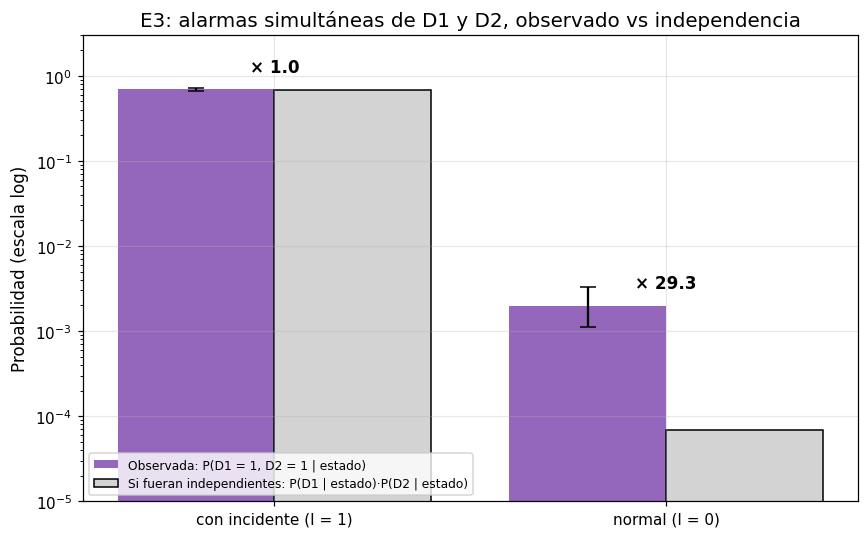

In [ ]:
# Gráfica de apoyo E3
fig, ax = plt.subplots(figsize=(8, 5))
estados_g = ["con incidente (I = 1)", "normal (I = 0)"]
pos = np.arange(len(estados_g))
obs_g = [tabla_e3.loc[e_, "P(ambos)"] for e_ in estados_g]
ind_g = [tabla_e3.loc[e_, "P(D1)·P(D2)"] for e_ in estados_g]
# IC de Clopper-Pearson de la probabilidad observada de "ambos" en cada estado
ic_g = [ic_clopper_pearson(int(tabla_2x2(m_)[0, 0]), int(m_.sum())) for m_ in [incid, ~incid]]
ax.bar(pos - 0.2, obs_g, width=0.4, color="tab:purple", label="Observada: P(D1 = 1, D2 = 1 | estado)",
       yerr=[[o - i[0] for o, i in zip(obs_g, ic_g)], [i[1] - o for o, i in zip(obs_g, ic_g)]], capsize=5)
ax.bar(pos + 0.2, ind_g, width=0.4, color="lightgrey", edgecolor="black", label="Si fueran independientes: P(D1 | estado)·P(D2 | estado)")
for p_, o_, i_ in zip(pos, obs_g, ind_g):
    ax.text(p_, max(o_, i_) * 1.6, f"× {o_ / i_:.1f}", ha="center", fontsize=11, fontweight="bold")
ax.set_yscale("log")
ax.set_ylim(1e-5, 3)
ax.set_xticks(pos, estados_g)
ax.set_ylabel("Probabilidad (escala log)")
ax.set_title("E3: alarmas simultáneas de D1 y D2, observado vs independencia")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "apoyo_E3.png"), bbox_inches="tight")
plt.show()

**Conclusión E3.** $D_1$ y $D_2$ **no son condicionalmente independientes**, y el supuesto falla justo donde más importa.
- **Con incidente**, sí son compatibles con la independencia: OR = 1,22 (IC 90 % [0,68; 2,20], incluye 1), Fisher p = 0,58, y la probabilidad de que ambos suenen es 1,005 veces la que predice la independencia (IC [0,99; 1,02]). Cada detector "ve" el incidente por su propio canal, latencia o errores.
- **Sin incidente**, están **fuertemente asociados**: OR = 51 (IC [27; 97]), Fisher p ≈ 3·10⁻¹⁴. Las falsas alarmas simultáneas son **29 veces** más frecuentes de lo que predice la independencia (11 observadas frente a 0,4 esperadas; IC del cociente [18; 42]). La interpretación es una **causa común**: episodios transitorios sin incidente real (picos de carga, por ejemplo) que suben a la vez la latencia y la tasa de errores y disparan los dos detectores. La prueba conjunta rechaza con claridad (G = 59, gl = 2, p ≈ 10⁻¹³).
- La asociación **marginal** (OR = 188) es mucho mayor que cualquiera de las condicionales, porque mezcla los dos estados: ambos detectores suenan más cuando hay incidente. Por eso hay que condicionar en el estado antes de hablar de independencia.

**Efecto sobre E2.** La regla "o" casi no cambia (VPP 0,190 bajo independencia frente a 0,209, diferencia −0,019, IC [−0,028; −0,010]). En cambio, la regla **"y"** cambia radicalmente. Suponiendo independencia, su TFP sería $f_1 f_2 = 6{,}8\cdot10^{-5}$ en lugar de $2{,}0\cdot10^{-3}$, y su VPP subiría de **0,58 a 0,98** (diferencia +0,39, IC [0,26; 0,49]). Es decir, se afirmaría que casi toda alerta "y" es real cuando en realidad lo es poco más de la mitad. Las falsas alarmas diarias se subestimarían de 2,9 a 0,1, lo que en E4 haría parecer que la regla cumple con un margen enorme. **Conclusión práctica:** las reglas combinadas deben evaluarse con la conjunta observada, como se hizo en E1 y E2, y nunca multiplicando las tasas de cada detector.

### E4. Falsas alarmas por día

**Qué se pide.** El equipo de guardia tolera, **con probabilidad al menos 0,90**, no más de $k_{\max}$ falsas alarmas en un día de 1440 minutos ($k_{\max} = 5$ para este grupo). Hay que ver qué reglas cumplen, **propagando la incertidumbre** de la TFP estimada, y recomendar una.

**Modelo.** Sea $X$ el número de falsas alarmas en un día. Un minuto produce una falsa alarma si **no** hay incidente **y** la regla suena: probabilidad $q = (1-\pi)\,f$. E1 mostró que los minutos son independientes y que las falsas alarmas no se agrupan, así que
$$X \sim \text{Binomial}(1440,\ q) \;\approx\; \text{Poisson}(\lambda = 1440\,(1-\pi)\,f).$$
La exigencia es $P(X \le k_{\max}) \ge 0{,}90$. Como esa probabilidad **decrece** con $f$, equivale a una cota sobre la TFP:
$$P(X \le k_{\max}) \ge 0{,}90 \iff f \le f^*, \qquad f^* \text{ tal que } P\big(\text{Bin}(1440, (1-\pi)f^*) \le k_{\max}\big) = 0{,}90.$$
Así el problema se reduce a decidir si la TFP de cada regla está por debajo de $f^*$. Como $f$ se estimó con datos, no basta comparar la estimación puntual: hay que ver **con qué seguridad** está debajo.

In [ ]:
# Paso 1. Cota f*, cumplimiento con la estimación puntual y compromiso con la detección
NIVEL_GUARDIA = 0.90                                            # probabilidad exigida por el equipo de guardia


def p_cumple(f, k=k_max, prev=pi_incidentes, minutos=MIN_DIA):
    # P(X <= k) con X ~ Binomial(minutos, (1 − prev)·f): probabilidad de no pasar de k falsas alarmas en un día
    return stats.binom.cdf(k, minutos, (1 - prev) * np.asarray(f))


# f* : la TFP máxima que todavía cumple la exigencia (raíz de P(X <= k_max) − 0,90 = 0)
f_estrella = optimize.brentq(lambda f: p_cumple(f) - NIVEL_GUARDIA, 1e-7, 0.05)
print(f"k_max = {k_max} falsas alarmas/día | exigencia P(X <= {k_max}) >= {NIVEL_GUARDIA}")
print(f"TFP máxima admisible f* = {f_estrella:.5f} (≈ {MIN_DIA * (1 - pi_incidentes) * f_estrella:.2f} falsas alarmas esperadas por día)")
print(f"Comprobación con Poisson: P(Poisson({MIN_DIA * (1 - pi_incidentes) * f_estrella:.3f}) <= {k_max}) = "
      f"{stats.poisson.cdf(k_max, MIN_DIA * (1 - pi_incidentes) * f_estrella):.4f}\n")

inc_dia = MIN_DIA * pi_incidentes                               # minutos con incidente esperados por día
filas_e4 = []
for regla in REGLAS:
    f_, s_ = TFP[regla], SENS[regla]
    filas_e4.append({"regla": regla, "TFP": f_,
                     "falsas/día esperadas": MIN_DIA * (1 - pi_incidentes) * f_,
                     f"P(X <= {k_max})": float(p_cumple(f_)),
                     "cumple (puntual)": "sí" if p_cumple(f_) >= NIVEL_GUARDIA else "no",
                     "min. con incidente NO detectados/día": inc_dia * (1 - s_),
                     "VPP producción (E2)": vpp(s_, f_, pi_incidentes)})
tabla_e4 = pd.DataFrame(filas_e4).set_index("regla")
print(f"Minutos con incidente esperados por día en producción: {inc_dia:.2f}")
print(tabla_e4.to_string(float_format=lambda v: f"{v:.4f}"))

k_max = 5 falsas alarmas/día | exigencia P(X <= 5) >= 0.9
TFP máxima admisible f* = 0.00220 (≈ 3.15 falsas alarmas esperadas por día)
Comprobación con Poisson: P(Poisson(3.154) <= 5) = 0.8998

Minutos con incidente esperados por día en producción: 5.76
           TFP  falsas/día esperadas  P(X <= 5) cumple (puntual)  min. con incidente NO detectados/día  VPP producción (E2)
regla                                                                                                                      
D1      0.0067                9.6205     0.0822               no                                0.5117               0.3530
D2      0.0102               14.5608     0.0037               no                                1.4043               0.2303
D1 y D2 0.0020                2.8602     0.9297               sí                                1.7732               0.5823
D1 o D2 0.0149               21.3212     0.0000               no                                0.1428               0.2085


**Paso 2. Propagación de la incertidumbre hasta la conclusión.** Se usan tres formas complementarias:
1. **IC de $P(X \le k_{\max})$:** como esa probabilidad es una función monótona (decreciente) de $f$, se evalúa en los extremos del IC de Clopper-Pearson de $f$, y el intervalo resultante hereda su cobertura.
2. **Prueba de cumplimiento:** $H_0: f \ge f^*$ (la regla **no** cumple) contra $H_1: f < f^*$ (cumple). Se plantea así para que la carga de la prueba esté en demostrar que cumple. El valor p exacto es $P(\text{Bin}(n_N, f^*) \le FP_{\text{obs}})$: qué tan raro sería ver tan pocas falsas alarmas si la regla estuviera justo en el límite.
3. **Bootstrap:** con las réplicas multinomiales de E2 se obtiene la distribución de $P(X \le k_{\max})$ y la fracción de réplicas en que la regla cumple, que es la **estabilidad** de la conclusión.

In [ ]:
# Paso 2. Propagación de la incertidumbre de la TFP a la conclusión de cumplimiento
filas_inc = []
for regla in REGLAS:
    FP_obs = conf_e1[regla]["FP"]                               # falsas alarmas observadas en los n_norm minutos normales
    f_li, f_ls = ic_clopper_pearson(FP_obs, n_norm)             # IC de la TFP
    # (1) IC de P(X <= k): monótona decreciente en f -> el extremo inferior sale de f_ls y el superior de f_li
    pc_li, pc_ls = float(p_cumple(f_ls)), float(p_cumple(f_li))
    # (2) Prueba de cumplimiento H0: f >= f*  vs  H1: f < f*  (p exacto con la binomial)
    p_test = stats.binom.cdf(FP_obs, n_norm, f_estrella)
    # (3) Bootstrap: distribución de P(X <= k) con las réplicas de E2
    pc_boot = p_cumple(f_boot[regla])
    filas_inc.append({"regla": regla, "FP / n": f"{FP_obs} / {n_norm}",
                      "IC TFP (C-P)": f"[{f_li:.5f}, {f_ls:.5f}]",
                      f"P(X <= {k_max})": float(p_cumple(TFP[regla])),
                      f"IC P(X <= {k_max})": f"[{pc_li:.3f}, {pc_ls:.3f}]",
                      "p de H0: no cumple": p_test,
                      "% réplicas bootstrap que cumplen": 100 * np.mean(pc_boot >= NIVEL_GUARDIA),
                      "conclusión": ("cumple con evidencia" if p_test < alpha else
                                     ("cumple en la estimación, sin evidencia suficiente" if p_cumple(TFP[regla]) >= NIVEL_GUARDIA
                                      else "no cumple"))})
tabla_e4_inc = pd.DataFrame(filas_inc).set_index("regla")
print(f"f* = {f_estrella:.5f} | IC al {nivel_confianza:.0%}")
print(tabla_e4_inc.to_string(float_format=lambda v: f"{v:.4f}"))
tabla_e4.join(tabla_e4_inc.drop(columns=f"P(X <= {k_max})")).to_csv("E4_falsas_alarmas.csv")

# ¿Con qué TFP observada se demostraría el cumplimiento de 'D1 y D2'? ¿Cuántos minutos normales harían falta?
regla_c = "D1 y D2"
f_hat_c = TFP[regla_c]
n_nec = next(n for n in np.arange(n_norm, 5_000_000, 1000)       # se busca el menor n en pasos de 1000 minutos
             if stats.binom.cdf(int(round(f_hat_c * n)), n, f_estrella) < alpha)
print(f"\nSi la TFP real de '{regla_c}' fuera la estimada ({f_hat_c:.5f}), para demostrar f < f* al nivel alpha = {alpha} "
      f"harían falta ≈ {n_nec:,} minutos normales (≈ {n_nec / MIN_DIA:.0f} días), frente a los {n_norm} actuales.")

f* = 0.00220 | IC al 90%
            FP / n        IC TFP (C-P)  P(X <= 5)    IC P(X <= 5)  p de H0: no cumple  % réplicas bootstrap que cumplen                                         conclusión
regla                                                                                                                                                                     
D1       37 / 5516  [0.00501, 0.00882]     0.0822  [0.013, 0.278]              1.0000                            0.0000                                          no cumple
D2       56 / 5516  [0.00804, 0.01267]     0.0037  [0.000, 0.027]              1.0000                            0.0000                                          no cumple
D1 y D2  11 / 5516  [0.00112, 0.00330]     0.9297  [0.663, 0.994]              0.4467                           68.5150  cumple en la estimación, sin evidencia suficiente
D1 o D2  82 / 5516  [0.01229, 0.01784]     0.0000  [0.000, 0.000]              1.0000                            0.0000 

**Paso 3. Verificación por simulación.** Se simulan días completos **minuto a minuto**: el incidente con probabilidad $\pi$ y la pareja $(D_1, D_2)$ sorteada de la conjunta observada para ese estado, igual que en E2. Después se cuentan las falsas alarmas de cada regla por día. Esto comprueba el modelo binomial sin usarlo y respeta la dependencia entre detectores de E3.

In [ ]:
# Paso 3. Montecarlo de días completos, minuto a minuto
DIAS_SIM, LOTE = 40_000, 4_000                                  # días simulados, en lotes para no agotar memoria
falsas_sim = {r_: np.empty(DIAS_SIM, dtype=int) for r_ in REGLAS}
for i0 in range(0, DIAS_SIM, LOTE):
    inc_m = rng.random((LOTE, MIN_DIA)) < pi_incidentes        # incidente en cada minuto de cada día del lote
    comb_m = np.where(inc_m, rng.choice(4, (LOTE, MIN_DIA), p=p_comb_inc), rng.choice(4, (LOTE, MIN_DIA), p=p_comb_nor))
    a1, a2 = np.isin(comb_m, [2, 3]), np.isin(comb_m, [1, 3])  # D1 y D2 de cada minuto (códigos de E2: 00, 01, 10, 11)
    for regla, a_ in {"D1": a1, "D2": a2, "D1 y D2": a1 & a2, "D1 o D2": a1 | a2}.items():
        falsas_sim[regla][i0:i0 + LOTE] = (a_ & ~inc_m).sum(axis=1)   # falsas alarmas = suena sin incidente

print(f"Días simulados: {DIAS_SIM:,}")
for regla in REGLAS:
    p_sim = np.mean(falsas_sim[regla] <= k_max)
    ee_sim = np.sqrt(p_sim * (1 - p_sim) / DIAS_SIM)
    print(f"  {regla:8s}: media = {falsas_sim[regla].mean():6.2f} falsas/día (modelo {MIN_DIA * (1 - pi_incidentes) * TFP[regla]:6.2f}) | "
          f"P(X <= {k_max}) simulada = {p_sim:.4f} ± {z_e3 * ee_sim:.4f} | binomial = {float(p_cumple(TFP[regla])):.4f}")

Días simulados: 40,000
  D1      : media =   9.62 falsas/día (modelo   9.62) | P(X <= 5) simulada = 0.0815 ± 0.0022 | binomial = 0.0822
  D2      : media =  14.56 falsas/día (modelo  14.56) | P(X <= 5) simulada = 0.0035 ± 0.0005 | binomial = 0.0037
  D1 y D2 : media =   2.87 falsas/día (modelo   2.86) | P(X <= 5) simulada = 0.9283 ± 0.0021 | binomial = 0.9297
  D1 o D2 : media =  21.32 falsas/día (modelo  21.32) | P(X <= 5) simulada = 0.0000 ± 0.0000 | binomial = 0.0000


### Figura 6
Izquierda: $P(X \le k_{\max})$ como función de la TFP, con la exigencia de 0,90, la cota $f^*$ y cada regla con el IC de su TFP. Una regla cumple con seguridad solo si **todo** su intervalo queda a la izquierda de $f^*$. Derecha: distribución del número de falsas alarmas por día de cada regla, con el límite $k_{\max}$.

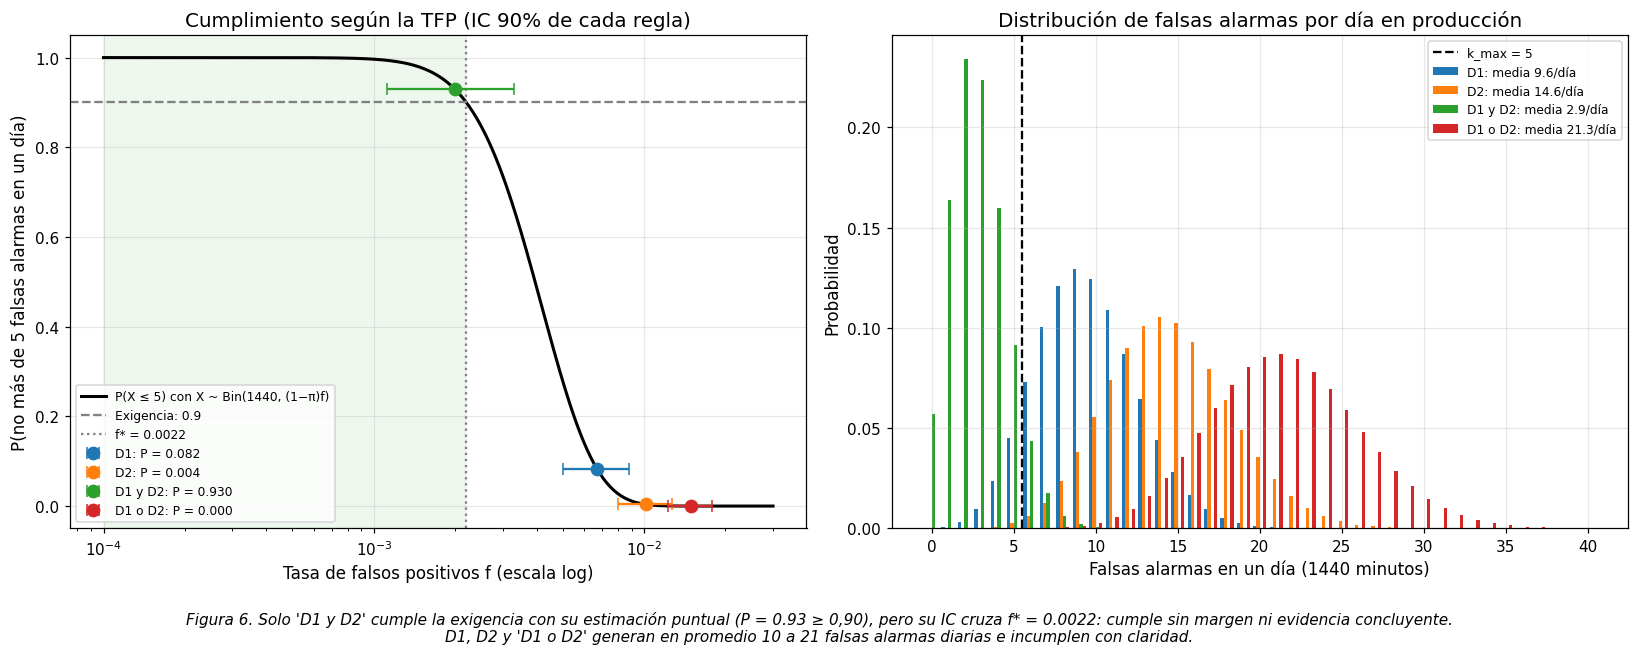

In [ ]:
# Figura 6. Falsas alarmas por día y cumplimiento de la exigencia del equipo de guardia
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

f_grid = np.logspace(-4, np.log10(0.03), 400)
ax[0].semilogx(f_grid, p_cumple(f_grid), color="black", lw=2, label=f"P(X ≤ {k_max}) con X ~ Bin(1440, (1−π)f)")
ax[0].axhline(NIVEL_GUARDIA, color="grey", linestyle="--", label=f"Exigencia: {NIVEL_GUARDIA}")
ax[0].axvline(f_estrella, color="grey", linestyle=":", label=f"f* = {f_estrella:.4f}")
ax[0].axvspan(1e-4, f_estrella, color="tab:green", alpha=0.08)
for regla in REGLAS:
    f_li, f_ls = ic_clopper_pearson(conf_e1[regla]["FP"], n_norm)
    y_ = float(p_cumple(TFP[regla]))
    ax[0].errorbar(TFP[regla], y_, xerr=[[TFP[regla] - f_li], [f_ls - TFP[regla]]], fmt="o", ms=8, capsize=4,
                   color=COLORES_E[regla], label=f"{regla}: P = {y_:.3f}")
ax[0].set_xlabel("Tasa de falsos positivos f (escala log)")
ax[0].set_ylabel(f"P(no más de {k_max} falsas alarmas en un día)")
ax[0].set_title(f"Cumplimiento según la TFP (IC {nivel_confianza:.0%} de cada regla)")
ax[0].legend(fontsize=8, loc="lower left")

k_vals = np.arange(0, 41)
ancho = 0.2
for j_, regla in enumerate(REGLAS):
    ax[1].bar(k_vals + (j_ - 1.5) * ancho, stats.binom.pmf(k_vals, MIN_DIA, (1 - pi_incidentes) * TFP[regla]), width=ancho,
              color=COLORES_E[regla], label=f"{regla}: media {MIN_DIA * (1 - pi_incidentes) * TFP[regla]:.1f}/día")
ax[1].axvline(k_max + 0.5, color="black", linestyle="--", label=f"k_max = {k_max}")
ax[1].set_xlabel("Falsas alarmas en un día (1440 minutos)")
ax[1].set_ylabel("Probabilidad")
ax[1].set_title("Distribución de falsas alarmas por día en producción")
ax[1].legend(fontsize=8, loc="upper right")

pie_de_figura(fig, 6, f"Solo 'D1 y D2' cumple la exigencia con su estimación puntual (P = {float(p_cumple(TFP['D1 y D2'])):.2f} ≥ 0,90), "
                      f"pero su IC cruza f* = {f_estrella:.4f}: cumple sin margen ni evidencia concluyente.\n"
                      f"D1, D2 y 'D1 o D2' generan en promedio 10 a 21 falsas alarmas diarias e incumplen con claridad.")
plt.tight_layout()
guardar_figura(fig, 6)
plt.show()

**Conclusión E4.** Con $k_{\max} = 5$, la exigencia $P(X \le 5) \ge 0{,}90$ equivale a una TFP máxima de $f^* = 0{,}0022$ (≈ 3,2 falsas alarmas esperadas por día). La simulación minuto a minuto de 40 000 días reproduce el modelo binomial en las cuatro reglas.

| Regla | Falsas/día | $P(X \le 5)$ [IC 90 %] | Incidentes no detectados/día | VPP | ¿Cumple? |
|---|---|---|---|---|---|
| $D_1$ | 9,6 | 0,08 [0,01; 0,28] | 0,5 min | 0,35 | **No** |
| $D_2$ | 14,6 | 0,004 [0,00; 0,03] | 1,4 min | 0,23 | **No** |
| $D_1$ y $D_2$ | 2,9 | **0,93** [0,66; 0,99] | 1,8 min | 0,58 | **Sí, en la estimación; sin evidencia concluyente** |
| $D_1$ o $D_2$ | 21,3 | 0,00 [0,00; 0,00] | 0,1 min | 0,21 | **No** |

- **Tres reglas incumplen sin ninguna duda:** incluso en el extremo favorable de su IC están muy lejos del 0,90. Con ellas el equipo de guardia recibiría de 10 a 21 falsas alarmas diarias.
- **"$D_1$ y $D_2$" cumple con su estimación puntual (0,93), pero sin margen.** Su TFP (0,0020) está apenas debajo de $f^*$ (0,0022) y su IC [0,0011; 0,0033] cruza la cota. La prueba de cumplimiento ($H_0$: no cumple) da p = 0,45, así que **no hay evidencia estadística de que cumpla**, y solo el 69 % de las réplicas bootstrap cumplen. Con los datos actuales la conclusión es "probablemente cumple". Demostrarlo al nivel del grupo requeriría ≈ 92 500 minutos normales (≈ 64 días) en lugar de 5516, si la TFP real fuera la estimada.
- **Recomendación: adoptar "$D_1$ y $D_2$" para despertar al equipo de guardia**, por ser la única regla compatible con la exigencia y la de mayor VPP (58 % de sus alertas son reales). Tiene dos condiciones:
  1. **Validarla en producción:** registrar las falsas alarmas diarias durante las primeras semanas y revisar la regla si superan ≈ 3 por día en promedio.
  2. **Compensar su menor sensibilidad:** "y" deja sin detectar el 31 % de los minutos con incidente (≈ 1,8 de los 5,8 diarios), frente al 9 % de $D_1$ solo. Una opción es enviar las alertas de **$D_1$ solo** como aviso de baja prioridad (ticket, sin despertar a nadie), que no cuenta contra $k_{\max}$ y recupera la mayor parte de la detección.
- **Conexión con E3:** si se hubiera supuesto independencia entre detectores, "y" parecería tener 0,1 falsas alarmas diarias y cumplir "con holgura". El análisis correcto muestra que está en el límite.

# Parte F - Inferencia, distribuciones muestrales y comparación de versiones (16 pts)

### F1. Distribución muestral de la media de latencia_ms

### F2. Intervalo para la latencia media

### F3. Versión B frente a versión A

### F4. Cobertura de intervalos para una proporción

### F5. Tamaño de muestra por versión

### F6. Validación con solicitudes_validacion.csv (día 9)

# Parte G - Simulación y decisión de capacidad (14 pts)

### G1. Simulador de Montecarlo con c GPUs

### G2. Capacidad con la tasa de llegadas multiplicada por g

### G3. Robustez de c*

### G4. Memorando ejecutivo
Se entrega aparte como PDF de una página (E4).